# Room Occupancy Estimation: Discovering Room-Usage Patterns and Unusual Behaviour

**Module:** DSA8003 – Data Mining  
**Group:** Group 5  
**Dataset:** Room Occupancy Estimation  
**Investigation type:** Unsupervised learning and anomaly detection

## Research Question

Can unlabelled sensor readings reveal distinct room-usage patterns and unusual periods, and how can we distinguish unusual room behaviour from potential sensor faults?

## Investigation Overview

This investigation explores environmental sensor data collected from a room to discover recurring room-usage patterns and identify unusual observations or periods.

The analysis focuses on temperature, light, sound, carbon dioxide (CO₂), and passive infrared (PIR) motion measurements.

Clustering is used to investigate whether the sensor readings reveal distinct patterns of room usage. Anomaly detection is then used to identify observations or periods that differ from typical behaviour.

The investigation also examines which sensor types contribute to the discovered structure and whether temporal changes in sensor readings can provide indicators of possible room-entry and exit events.

The occupancy label is reserved for evaluation and interpretation rather than being used as an input to the unsupervised discovery process.

## Supporting Research Questions

1. Which sensor types contribute most to distinguishing the discovered room-usage patterns?
2. Can changes in sensor readings provide indicators of possible room-entry and exit events without relying on occupancy labels?

## Analytical Approach

The investigation follows a connected analytical process:

1. Understand and prepare the sensor dataset.
2. Discover recurring room-usage patterns through clustering.
3. Examine the contribution of different sensor types and the robustness of the discovered structure.
4. Detect unusual observations and periods.
5. Investigate the relationship between clusters and anomalies.
6. Examine possible temporal indicators of room-entry and exit events.
7. Evaluate the findings, uncertainty and limitations.

The objective is not simply to identify occupied and empty periods, but to understand what patterns and unusual behaviour can be discovered from the sensor data and how confidently they can be interpreted.

# 1. Data Understanding and Preparation

Before applying clustering and anomaly-detection techniques, it is important to understand the dataset, its structure, temporal characteristics and potential limitations.

This section examines the environmental sensor measurements and establishes a suitable representation for the subsequent data-mining investigation.

The analysis considers the quality of the sensor readings, recording gaps, differences in sensor behaviour and the implications of transforming the original measurements into time-based observations.

The preparation decisions made in this section are important because they directly influence the similarity between observations, the clusters that can be discovered and the anomalies that may be identified.

## 1.1 Notebook Setup and Configuration

This subsection establishes the computational environment and central configuration used throughout the investigation.

The required Python libraries, file paths, output directories, random seed and preparation parameters are defined in one place. This makes the analysis easier to reproduce and allows important preparation settings to be changed consistently when conducting sensitivity analysis.

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_PATH   = "data/Occupancy_Estimation.csv"
OUT_DIR     = "data/prepared"
FIG_DIR     = "figures"
GAP_BREAK_S = 300     # a gap longer than this (5 min) starts a new contiguous segment
WINDOW_MIN  = 5       # primary analytical object: 5-minute windows
MIN_FILL    = 0.8     # a window needs >= 80% of its expected 30 s readings
RANDOM_SEED = 42
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

# plotting style shared by every poster figure (Person 1 owns this, others reuse it)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
C_BLUE, C_ORANGE, C_AQUA, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
    "legend.frameon": False, "text.color": INK,
})

## 1.2 Dataset Loading and Data Dictionary

The dataset is loaded and examined to understand its dimensions, available variables, data types and initial quality.

The sensor measurements are organised into their respective categories:

- Temperature
- Light
- Sound
- Carbon dioxide (CO₂)
- Passive infrared (PIR) motion

A data dictionary is also constructed to document the sensor variables, their measurement units and basic statistical characteristics.

This provides the foundation for understanding what information is available and how each sensor type may contribute to identifying room-usage patterns.

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns; missing values: {raw.isna().sum().sum()}; duplicate rows: {raw.duplicated().sum()}")

LABEL = "Room_Occupancy_Count"
TEMP  = [f"S{i}_Temp"  for i in range(1, 5)]
LIGHT = [f"S{i}_Light" for i in range(1, 5)]
SOUND = [f"S{i}_Sound" for i in range(1, 5)]
CO2   = ["S5_CO2", "S5_CO2_Slope"]
PIR   = ["S6_PIR", "S7_PIR"]
SENSORS = TEMP + LIGHT + SOUND + CO2 + PIR

units = {**{c: "°C" for c in TEMP}, **{c: "lux" for c in LIGHT}, **{c: "V (ADC amplitude)" for c in SOUND},
         "S5_CO2": "ppm", "S5_CO2_Slope": "ppm per reading (sliding-window regression)", **{c: "binary (motion in 30 s)" for c in PIR}}
node = {**{c: "desk node" for c in TEMP + LIGHT + SOUND}, "S5_CO2": "centre node", "S5_CO2_Slope": "centre node (derived)",
        **{c: "ceiling node" for c in PIR}}
dictionary = pd.DataFrame({
    "unit": pd.Series(units), "node": pd.Series(node),
    "min": raw[SENSORS].min(), "median": raw[SENSORS].median(), "max": raw[SENSORS].max(),
    "n_unique": raw[SENSORS].nunique(),
})
dictionary

10,129 rows × 19 columns; missing values: 0; duplicate rows: 0


,unit,node,min,median,max,n_unique
S1_Temp,°C,desk node,24.940000,25.38,26.380000,24
S2_Temp,°C,desk node,24.750000,25.38,29.000000,69
S3_Temp,°C,desk node,24.440000,24.94,26.190000,29
S4_Temp,°C,desk node,24.940000,25.75,26.560000,27
S1_Light,lux,desk node,0.000000,0.00,165.000000,68
S2_Light,lux,desk node,0.000000,0.00,258.000000,82
S3_Light,lux,desk node,0.000000,0.00,280.000000,177
S4_Light,lux,desk node,0.000000,0.00,74.000000,75
S1_Sound,V (ADC amplitude),desk node,0.060000,0.08,3.880000,231
S2_Sound,V (ADC amplitude),desk node,0.040000,0.05,3.440000,185


## 1.3 Temporal Structure and Recording Periods

The dataset contains time-dependent sensor measurements. Therefore, understanding the temporal structure is essential before creating analytical observations.

This subsection examines the timestamp sequence, sampling intervals, missing time periods and recording blocks.

Recording gaps are particularly important because observations separated by substantial periods of missing data should not automatically be treated as continuous measurements.

The temporal structure is therefore considered when constructing time-based windows for subsequent analysis.

In [3]:
df = raw.copy()
df["ts"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%Y/%m/%d %H:%M:%S")
assert df["ts"].is_monotonic_increasing and not df["ts"].duplicated().any()

gap = df["ts"].diff().dt.total_seconds()
print("Sampling interval (s):", gap.value_counts().head(4).to_dict())
print(f"Single missed readings (≈61 s): {((gap > 45) & (gap <= 65)).sum()}; gaps > 65 s: {(gap > 65).sum()}")

df["segment"] = (gap > GAP_BREAK_S).cumsum().astype(int)
seg = df.groupby("segment").agg(start=("ts", "min"), end=("ts", "max"), readings=("ts", "size"),
                                occupied_readings=(LABEL, lambda s: int((s > 0).sum())))
seg["hours"] = ((seg["end"] - seg["start"]).dt.total_seconds() / 3600).round(1)
seg["gap_before_min"] = (gap[df.groupby("segment").head(1).index].values / 60).round(1)
seg

Sampling interval (s): {31.0: 6373, 30.0: 3614, 61.0: 131, 154.0: 2}
Single missed readings (≈61 s): 133; gaps > 65 s: 8


,start,end,readings,occupied_readings,hours,gap_before_min
segment,,,,,,
0,2017-12-22 10:49:41,2017-12-22 12:42:31,216,216,1.9,NaN
1,2017-12-22 13:08:03,2017-12-24 09:10:50,5089,1391,44.0,25.5
2,2017-12-25 09:11:42,2017-12-26 09:10:01,2779,0,24.0,1440.9
3,2018-01-10 15:25:48,2018-01-11 09:00:09,2045,294,17.6,21975.8


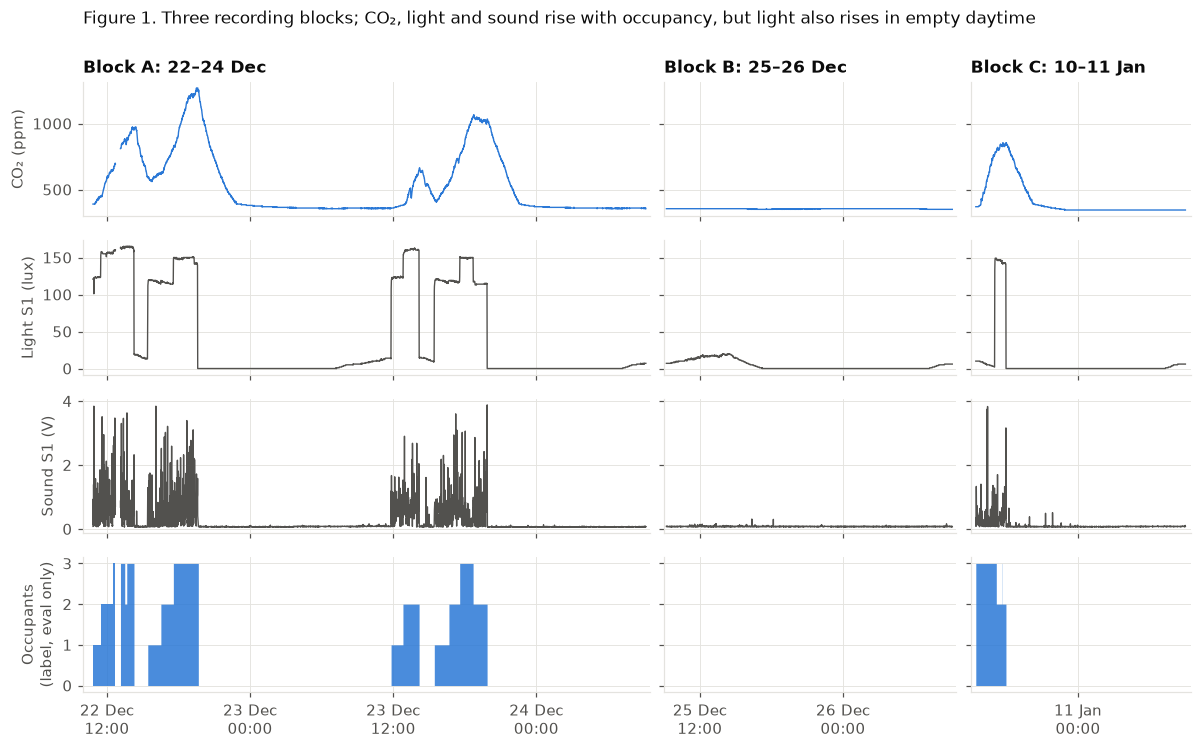

In [4]:
blocks = [(pd.Timestamp("2017-12-22 10:00"), pd.Timestamp("2017-12-24 09:30"), "Block A: 22–24 Dec"),
          (pd.Timestamp("2017-12-25 09:00"), pd.Timestamp("2017-12-26 09:30"), "Block B: 25–26 Dec"),
          (pd.Timestamp("2018-01-10 15:00"), pd.Timestamp("2018-01-11 09:30"), "Block C: 10–11 Jan")]
rows = [("S5_CO2", "CO₂ (ppm)"), ("S1_Light", "Light S1 (lux)"), ("S1_Sound", "Sound S1 (V)"), (LABEL, "Occupants\n(label, eval only)")]
widths = [(b - a).total_seconds() for a, b, _ in blocks]
fig, axes = plt.subplots(len(rows), 3, figsize=(13, 7.2), sharey="row", gridspec_kw={"width_ratios": widths, "wspace": 0.04, "hspace": 0.18})
for j, (a, b, title) in enumerate(blocks):
    for i, (col, lab) in enumerate(rows):
        ax = axes[i, j]
        for _, g in df[(df.ts >= a) & (df.ts <= b)].groupby("segment"):
            if col == LABEL:
                ax.fill_between(g.ts, g[col], step="post", color=C_BLUE, alpha=0.85, linewidth=0)
            else:
                ax.plot(g.ts, g[col], color=C_BLUE if col == "S5_CO2" else INK2, linewidth=0.9)
        ax.set_xlim(a, b)
        if j == 0: ax.set_ylabel(lab)
        if i == 0: ax.set_title(title)
        ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
        if i < len(rows) - 1: ax.tick_params(labelbottom=False)
axes[-1, 0].set_yticks([0, 1, 2, 3])
fig.suptitle("Figure 1. Three recording blocks; CO₂, light and sound rise with occupancy, but light also rises in empty daytime", x=0.125, ha="left", fontsize=11, y=0.97)
fig.savefig(f"{FIG_DIR}/fig1_timeline.png"); plt.show()

**Finding:** the "4 days" are really **three recording blocks** (22–24 Dec, 25–26 Dec, 10–11 Jan), separated by gaps of 24 hours and 15 days. A 25-minute gap on 22 Dec splits the first block in two. Only segments 0, 1 and 3 contain occupancy, and the 25–26 Dec block is entirely empty. Short gaps (≤ 3.6 min) are kept inside segments; windows with too few readings are dropped.

## 1.4 Data Quality and Sensor Behaviour

Sensor data may contain irregularities, unexpected readings or changes in measurement behaviour that affect the interpretation of the investigation.

This subsection examines the quality and behaviour of the available sensor measurements.

The analysis considers missing values, duplicate observations, recording gaps, sensor variation and potential inconsistencies between sensor readings and the occupancy labels.

Particular attention is given to distinguishing unusual environmental conditions from potential data-quality problems.

Importantly, an unusual reading does not automatically indicate a faulty sensor. Its interpretation must consider the surrounding measurements, temporal context and behaviour of other sensors.

In [5]:
# SENSOR DATA QUALITY AND BEHAVIOUR ANALYSIS

# Separate empty and occupied observations for descriptive analysis.
# Occupancy labels are used only to characterise sensor behaviour.
empty_mask = df[LABEL].eq(0)
occupied_mask = df[LABEL].eq(1)

# Sensor measurement characteristics

def get_smallest_increment(series):
    """Return the smallest positive difference between unique readings."""
    values = np.sort(series.dropna().unique())

    if len(values) < 2:
        return np.nan

    differences = np.diff(values)
    positive_differences = differences[differences > 0]

    return positive_differences.min() if len(positive_differences) else np.nan


def get_longest_constant_run(series):
    """Return the longest consecutive run of identical readings."""
    run_groups = series.ne(series.shift()).cumsum()
    return int(series.groupby(run_groups).size().max())


sensor_quality = []

for sensor in SENSORS:
    sensor_quality.append({
        "Sensor": sensor,
        "Unique readings": df[sensor].nunique(),
        "Smallest observed increment": get_smallest_increment(df[sensor]),
        "Longest unchanged run (readings)": get_longest_constant_run(df[sensor])
    })

sensor_quality_df = pd.DataFrame(sensor_quality)

display(
    sensor_quality_df.style
    .format({
        "Smallest observed increment": "{:.3f}",
        "Longest unchanged run (readings)": "{:.0f}"
    }, na_rep="N/A")
    .hide(axis="index")
)

Sensor,Unique readings,Smallest observed increment,Longest unchanged run (readings)
S1_Temp,24,0.060,103
S2_Temp,69,0.060,268
S3_Temp,29,0.060,108
S4_Temp,27,0.060,59
S1_Light,68,1.000,1626
S2_Light,82,1.000,1624
S3_Light,177,1.000,1521
S4_Light,75,1.000,1523
S1_Sound,231,0.010,31
S2_Sound,185,0.010,49


In [6]:
# CO2 baseline across recording segments

co2_baseline_df = (
    df.groupby("segment")["S5_CO2"]
    .agg(
        readings="count",
        median="median",
        lower_baseline=lambda x: x.quantile(0.05),
        upper_baseline=lambda x: x.quantile(0.95)
    )
    .reset_index()
    .rename(columns={
        "segment": "Recording segment",
        "median": "Median CO2 (ppm)",
        "lower_baseline": "5th percentile (ppm)",
        "upper_baseline": "95th percentile (ppm)"
    })
)

display(
    co2_baseline_df.style
    .format({
        "Median CO2 (ppm)": "{:.1f}",
        "5th percentile (ppm)": "{:.1f}",
        "95th percentile (ppm)": "{:.1f}"
    })
    .hide(axis="index")
)

Recording segment,readings,Median CO2 (ppm),5th percentile (ppm),95th percentile (ppm)
0,216,527.5,390.0,675.0
1,5089,375.0,355.0,1035.0
2,2779,355.0,350.0,355.0
3,2045,345.0,345.0,805.0


In [7]:
# Sensor behaviour under empty and occupied conditions

sensor_groups = {
    "Temperature": TEMP,
    "Light": LIGHT,
    "Sound": SOUND,
    "CO2": ["S5_CO2"],
    "Motion (PIR)": PIR
}

occupancy_summary = []

for group_name, sensors in sensor_groups.items():
    for sensor in sensors:

        empty_values = df.loc[empty_mask, sensor]
        occupied_values = df.loc[occupied_mask, sensor]

        occupancy_summary.append({
            "Sensor group": group_name,
            "Sensor": sensor,
            "Empty median": empty_values.median(),
            "Occupied median": occupied_values.median(),
            "Empty readings above zero (%)": (
                (empty_values > 0).mean() * 100
                if group_name in ("Light", "Motion (PIR)")
                else np.nan
            )
        })

occupancy_summary_df = pd.DataFrame(occupancy_summary)

display(
    occupancy_summary_df.style
    .format({
        "Empty median": "{:.2f}",
        "Occupied median": "{:.2f}",
        "Empty readings above zero (%)": "{:.1f}%"
    }, na_rep="—")
    .hide(axis="index")
)

Sensor group,Sensor,Empty median,Occupied median,Empty readings above zero (%)
Temperature,S1_Temp,25.31,25.88,—
Temperature,S2_Temp,25.31,25.75,—
Temperature,S3_Temp,24.88,25.50,—
Temperature,S4_Temp,25.69,26.25,—
Light,S1_Light,0.00,120.00,29.0%
Light,S2_Light,0.00,33.00,29.0%
Light,S3_Light,0.00,58.00,32.1%
Light,S4_Light,0.00,40.00,32.0%
Sound,S1_Sound,0.07,0.26,—
Sound,S2_Sound,0.05,0.09,—


In [8]:

# Hourly occupancy and light statistics

hour = df["ts"].dt.hour
light_positive = df[LIGHT].gt(0).any(axis=1)

hourly_data = pd.DataFrame({
    "hour": hour,
    "occupied": occupied_mask.astype(int),
    "empty": empty_mask.astype(int),
    "empty_with_light": (empty_mask & light_positive).astype(int)
})

# Summarise sensor readings by hour
hourly_summary = (
    hourly_data.groupby("hour")
    .agg(
        total_readings=("occupied", "size"),
        occupied_readings=("occupied", "sum"),
        empty_readings=("empty", "sum"),
        empty_light_positive=("empty_with_light", "sum")
    )
    .reindex(range(24))
)

# Calculate hourly percentages
hourly_summary["occupied_pct"] = (
    hourly_summary["occupied_readings"]
    / hourly_summary["total_readings"] * 100
)

hourly_summary["empty_light_positive_pct"] = (
    hourly_summary["empty_light_positive"]
    / hourly_summary["empty_readings"].replace(0, np.nan) * 100
)

display(hourly_summary.round(1))


,total_readings,occupied_readings,empty_readings,empty_light_positive,occupied_pct,empty_light_positive_pct
hour,,,,,,
0,460,0,460,0,0.0,0.0
1,465,0,465,0,0.0,0.0
2,465,0,465,0,0.0,0.0
3,464,0,464,0,0.0,0.0
4,465,0,465,0,0.0,0.0
5,465,0,465,0,0.0,0.0
6,464,0,464,73,0.0,15.7
7,463,0,463,463,0.0,100.0
8,464,0,464,464,0.0,100.0


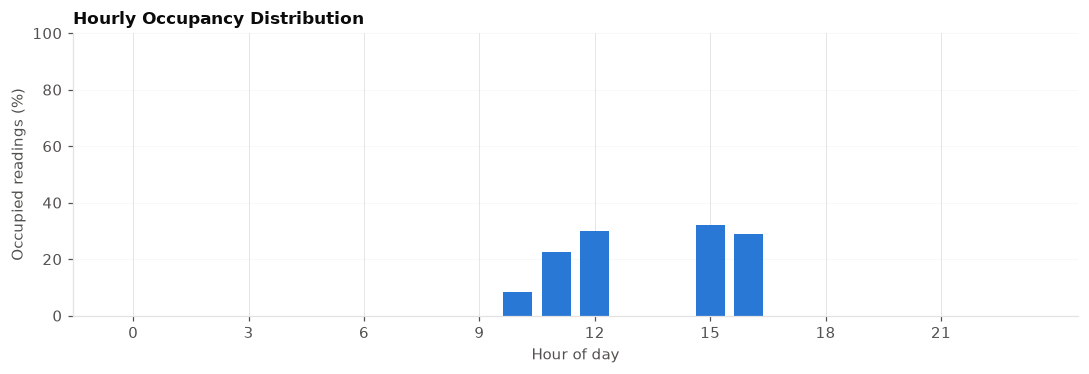

In [9]:
# Percentage of readings labelled as occupied by hour

fig, ax = plt.subplots(figsize=(10, 3.5))

ax.bar(
    hourly_summary.index,
    hourly_summary["occupied_pct"],
    color=C_BLUE,
    width=0.75
)

ax.set_title("Hourly Occupancy Distribution")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Occupied readings (%)")
ax.set_xticks(range(0, 24, 3))
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


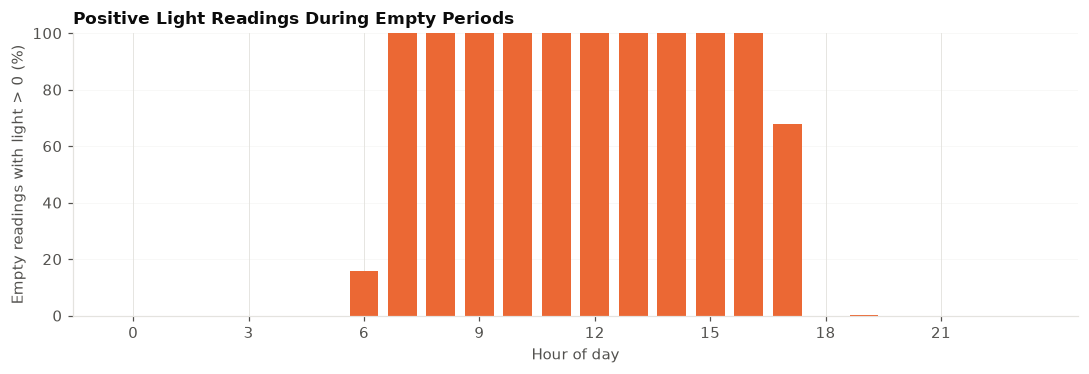

In [10]:

# Percentage of empty readings with positive light measurements by hour

fig, ax = plt.subplots(figsize=(10, 3.5))

ax.bar(
    hourly_summary.index,
    hourly_summary["empty_light_positive_pct"],
    color=C_ORANGE,
    width=0.75
)

ax.set_title("Positive Light Readings During Empty Periods")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Empty readings with light > 0 (%)")
ax.set_xticks(range(0, 24, 3))
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## 1.5 Representation Using Five-Minute Windows

The original dataset contains sensor measurements recorded at approximately 30-second intervals.

For the main data-mining investigation, these readings are transformed into non-overlapping five-minute windows within continuous recording segments.

Each window represents one analytical observation and summarises the sensor behaviour during that period.

The window-based representation provides a more manageable description of room conditions while reducing the influence of highly frequent and potentially noisy measurements.

Sensor-specific summary features are extracted to represent temperature, light, sound, CO₂ and motion behaviour.

The original 30-second measurements are retained separately because aggregating readings into five-minute windows may reduce the temporal detail required to investigate possible room-entry and exit events.

**Analytical object:** Each five-minute window is treated as one observation for the main clustering and anomaly-detection investigation.

In [11]:
FEATURE_GROUPS = {
    "temperature": [f"{c}_mean" for c in TEMP] + [f"{c}_delta" for c in TEMP],
    "light":       [f"{c}_mean" for c in LIGHT],
    "sound":       [f"{c}_mean" for c in SOUND] + [f"{c}_max" for c in SOUND],
    "co2":         ["CO2_excess_mean", "CO2_slope_mean"],
    "motion":      [f"{c}_frac" for c in PIR],
}
NODE_FEATURES = sum(FEATURE_GROUPS.values(), [])
TYPE_FEATURES = ["temp_mean", "temp_delta", "light_mean", "sound_mean", "sound_max", "CO2_excess_mean", "CO2_slope_mean", "pir_frac"]

def make_windows(d, minutes=WINDOW_MIN, min_fill=MIN_FILL):
    # Aggregate 30 s readings into non-overlapping windows inside each contiguous segment.
    d = d.copy()
    d["co2_excess"] = d["S5_CO2"] - d.groupby("segment")["S5_CO2"].transform(lambda s: s.quantile(0.05))
    seg_start = d.groupby("segment")["ts"].transform("min")
    d["win"] = ((d["ts"] - seg_start).dt.total_seconds() // (minutes * 60)).astype(int)
    g = d.groupby(["segment", "win"])
    out = pd.DataFrame({"start": g["ts"].min(), "n_readings": g.size()})
    for c in TEMP:
        out[f"{c}_mean"] = g[c].mean(); out[f"{c}_delta"] = g[c].last() - g[c].first()
    for c in LIGHT: out[f"{c}_mean"] = g[c].mean()
    for c in SOUND: out[f"{c}_mean"] = g[c].mean(); out[f"{c}_max"] = g[c].max()
    out["CO2_excess_mean"] = g["co2_excess"].mean(); out["CO2_slope_mean"] = g["S5_CO2_Slope"].mean()
    for c in PIR: out[f"{c}_frac"] = g[c].mean()
    # sensor-type (node-averaged) representation
    out["temp_mean"]  = out[[f"{c}_mean" for c in TEMP]].mean(axis=1)
    out["temp_delta"] = out[[f"{c}_delta" for c in TEMP]].mean(axis=1)
    out["light_mean"] = out[[f"{c}_mean" for c in LIGHT]].mean(axis=1)
    out["sound_mean"] = out[[f"{c}_mean" for c in SOUND]].mean(axis=1)
    out["sound_max"]  = out[[f"{c}_max" for c in SOUND]].max(axis=1)
    out["pir_frac"]   = out[[f"{c}_frac" for c in PIR]].mean(axis=1)
    # labels: kept in a SEPARATE frame, evaluation only
    lab = pd.DataFrame({"occ_mean": g[LABEL].mean(), "occ_max": g[LABEL].max(),
                        "occ_mode": g[LABEL].agg(lambda s: s.mode().iloc[0]),
                        "transition": g[LABEL].nunique() > 1})
    lab["occupied"] = lab["occ_max"] > 0
    keep = out["n_readings"] >= min_fill * minutes * 2
    out, lab = out[keep].reset_index(), lab[keep].reset_index(drop=True)
    out["date"] = out["start"].dt.date.astype(str); out["hour"] = out["start"].dt.hour
    return out, lab

print("Lag-1 autocorrelation at 30 s:", {c: round(df[c].autocorr(1), 2) for c in ["S1_Temp", "S1_Light", "S5_CO2", "S1_Sound", "S2_Sound", "S6_PIR", "S7_PIR"]})
W, W_lab = make_windows(df)
print(f"{len(W):,} windows of {WINDOW_MIN} min | occupied: {W_lab.occupied.mean():.1%} | windows containing an arrival/departure: {W_lab.transition.mean():.1%}")
print(f"node-level features: {len(NODE_FEATURES)} | sensor-type features: {len(TYPE_FEATURES)}")
W.head()

Lag-1 autocorrelation at 30 s: {'S1_Temp': np.float64(1.0), 'S1_Light': np.float64(1.0), 'S5_CO2': np.float64(1.0), 'S1_Sound': np.float64(0.49), 'S2_Sound': np.float64(0.55), 'S6_PIR': np.float64(0.6), 'S7_PIR': np.float64(0.74)}
1,044 windows of 5 min | occupied: 19.0% | windows containing an arrival/departure: 1.9%
node-level features: 24 | sensor-type features: 8


,segment,win,start,n_readings,S1_Temp_mean,S1_Temp_delta,S2_Temp_mean,S2_Temp_delta,S3_Temp_mean,S3_Temp_delta,...,S6_PIR_frac,S7_PIR_frac,temp_mean,temp_delta,light_mean,sound_mean,sound_max,pir_frac,date,hour
0,0,0,2017-12-22 10:49:41,10,24.988000,0.06,24.774000,0.06,24.554,0.00,...,0.200000,0.1,24.940500,0.0600,61.950000,0.29300,3.84,0.150000,2017-12-22,10
1,0,1,2017-12-22 10:54:47,10,25.060000,0.00,24.845000,0.07,24.616,0.07,...,0.800000,0.1,25.012750,0.0500,64.775000,0.24075,2.20,0.450000,2017-12-22,10
2,0,2,2017-12-22 10:59:54,10,25.123000,0.00,24.880000,0.00,24.660,0.06,...,0.500000,0.0,25.049750,0.0300,65.175000,0.21400,1.57,0.250000,2017-12-22,10
3,0,3,2017-12-22 11:05:00,10,25.190000,0.00,24.892000,0.06,24.690,0.00,...,0.100000,0.0,25.089750,0.0150,64.925000,0.11250,0.93,0.050000,2017-12-22,11
4,0,4,2017-12-22 11:10:06,9,25.203333,0.06,24.933333,0.00,24.730,0.00,...,0.222222,0.0,25.122222,0.0325,65.972222,0.22750,1.44,0.111111,2017-12-22,11


### Transformation and scaling
Distance-based clustering and anomaly methods (k-means, GMM, LOF, DBSCAN) are dominated by whichever feature has the largest numeric range. Light and sound are heavily right-skewed with many zeros, so they get a `log1p` transform, then **every feature is standardised** (z-scores).

For discovery, the scaler is fit on all windows, which is fine because no labels are involved. **For any predictive extension, refit the scaler on the training days only** using `scale_features(train, test)`.

In [12]:
LOG_COLS = [c for c in NODE_FEATURES + TYPE_FEATURES if any(k in c for k in ("Light", "light", "Sound", "sound"))]

def transform(Wdf, cols):
    X = Wdf[cols].copy()
    for c in set(cols) & set(LOG_COLS): X[c] = np.log1p(X[c])
    return X

def scale_features(train, test=None, cols=NODE_FEATURES):
    # log1p skewed columns, then z-score using statistics from `train` only.
    sc = StandardScaler().fit(transform(train, cols))
    Xtr = pd.DataFrame(sc.transform(transform(train, cols)), columns=cols, index=train.index)
    if test is None: return Xtr
    return Xtr, pd.DataFrame(sc.transform(transform(test, cols)), columns=cols, index=test.index)

X_node = scale_features(W, cols=NODE_FEATURES)
X_type = scale_features(W, cols=TYPE_FEATURES)
X_node.describe().loc[["mean", "std"]].round(2)

,S1_Temp_mean,S2_Temp_mean,S3_Temp_mean,S4_Temp_mean,S1_Temp_delta,S2_Temp_delta,S3_Temp_delta,S4_Temp_delta,S1_Light_mean,S2_Light_mean,...,S3_Sound_mean,S4_Sound_mean,S1_Sound_max,S2_Sound_max,S3_Sound_max,S4_Sound_max,CO2_excess_mean,CO2_slope_mean,S6_PIR_frac,S7_PIR_frac
mean,-0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,...,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 1.7 How Preparation Choices Influence the Analysis

Data preparation is not simply a preliminary cleaning step. It influences how observations are compared and, consequently, the patterns and unusual observations that can be discovered.

This subsection examines the implications of important preparation decisions, including feature scaling and the choice of time-window duration.

The analysis considers the trade-off between retaining detailed temporal information and creating more stable observations for data mining.

These comparisons help establish whether the selected representation is appropriate for the investigation and identify limitations that should be considered when interpreting subsequent results.

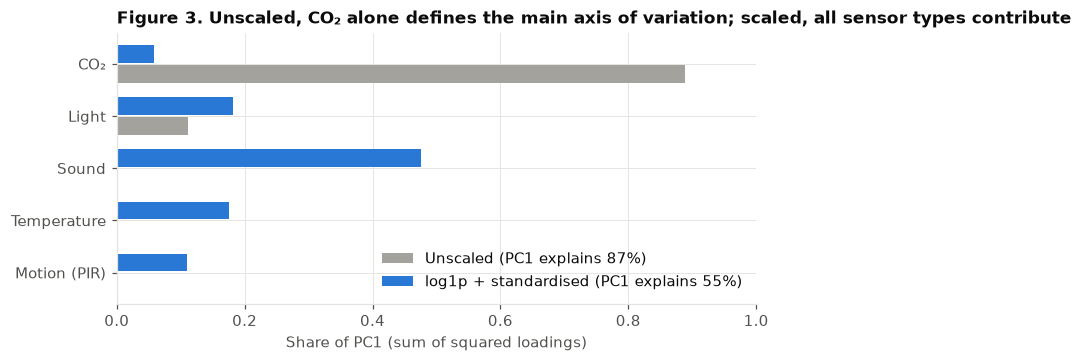

,unscaled,log1p + standardised
co2,0.888,0.059
light,0.112,0.182
sound,0.000,0.476
temperature,0.000,0.175
motion,0.000,0.109


In [13]:
def pc1_share_by_group(X, cols):
    p = PCA(n_components=1, random_state=RANDOM_SEED).fit(X)
    load = pd.Series(np.abs(p.components_[0]) ** 2, index=cols)  # squared loadings sum to 1
    grp = {c: g for g, cs in FEATURE_GROUPS.items() for c in cs}
    return load.groupby(grp).sum(), p.explained_variance_ratio_[0]

raw_share, raw_ev = pc1_share_by_group(W[NODE_FEATURES], NODE_FEATURES)
sc_share,  sc_ev  = pc1_share_by_group(X_node, NODE_FEATURES)
order = ["co2", "light", "sound", "temperature", "motion"]
comp = pd.DataFrame({"unscaled": raw_share, "log1p + standardised": sc_share}).loc[order]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
yy = np.arange(len(order)); h = 0.38
ax.barh(yy + h/2, comp["unscaled"], height=h - 0.04, color=C_GREY, label=f"Unscaled (PC1 explains {raw_ev:.0%})")
ax.barh(yy - h/2, comp["log1p + standardised"], height=h - 0.04, color=C_BLUE, label=f"log1p + standardised (PC1 explains {sc_ev:.0%})")
ax.set_yticks(yy); ax.set_yticklabels(["CO₂", "Light", "Sound", "Temperature", "Motion (PIR)"]); ax.invert_yaxis()
ax.set_xlabel("Share of PC1 (sum of squared loadings)"); ax.set_xlim(0, 1)
ax.legend(loc="lower right")
ax.set_title("Figure 3. Unscaled, CO₂ alone defines the main axis of variation; scaled, all sensor types contribute")
fig.savefig(f"{FIG_DIR}/fig3_scaling_effect.png"); plt.show()
comp.round(3)

In [14]:

# Evaluate different aggregation window lengths

window_lengths = [1, 2, 5, 10, 15, 30]
window_results = []

for minutes in window_lengths:
    windows, labels = make_windows(df, minutes=minutes)

    sound_autocorr = windows["S1_Sound_mean"].autocorr(lag=1)

    window_results.append({
        "window (min)": minutes,
        "windows": len(windows),
        "% windows mixing an arrival/departure": (
            100 * labels["transition"].mean()
        ),
        "lag-1 autocorr of S1 sound": sound_autocorr
    })

wl = pd.DataFrame(window_results).set_index("window (min)")


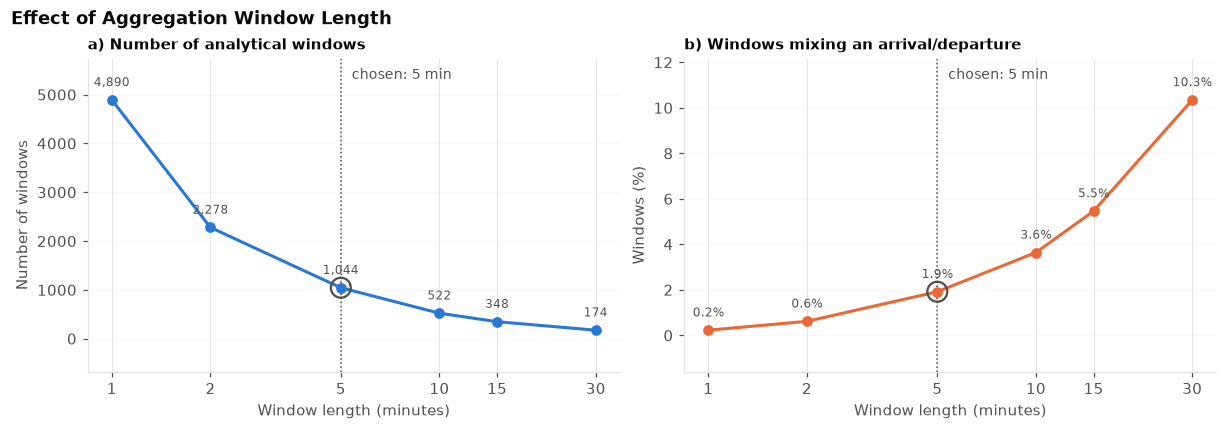

In [15]:
from matplotlib.ticker import ScalarFormatter

# Visualise the effect of aggregation window length
pct_col = "% windows mixing an arrival/departure"

fig, axes = plt.subplots(
    1, 2, figsize=(11, 3.8), sharex=True, constrained_layout=True
)

panels = [
    (axes[0], "windows", C_BLUE,
     "a) Number of analytical windows", "Number of windows", "{:,.0f}"),
    (axes[1], pct_col, C_ORANGE,
     "b) Windows mixing an arrival/departure", "Windows (%)", "{:.1f}%"),
]

for ax, col, color, title, ylabel, fmt in panels:
    # Main line
    ax.plot(wl.index, wl[col], marker="o", markersize=6,
            linewidth=2, color=color, zorder=3)

    # Value label on every point
    for x, v in wl[col].items():
        ax.annotate(fmt.format(v), (x, v), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=8, color=INK2)

    # Highlight the chosen window with a ring
    ax.scatter(WINDOW_MIN, wl.loc[WINDOW_MIN, col], s=170,
               facecolors="none", edgecolors=INK2, linewidths=1.5, zorder=4)

    # Reference line and label for the chosen window
    ax.axvline(WINDOW_MIN, color=INK2, linestyle=":", linewidth=1)
    ax.text(WINDOW_MIN * 1.08, 0.97, f"chosen: {WINDOW_MIN} min",
            transform=ax.get_xaxis_transform(),
            va="top", ha="left", fontsize=9, color=INK2)

    # Log x-axis so 1, 2, 5, 10, 15, 30 are spread out evenly
    ax.set_xscale("log")
    ax.set_xticks(wl.index)
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.minorticks_off()

    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("Window length (minutes)")
    ax.set_ylabel(ylabel)
    ax.margins(y=0.18)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig.suptitle("Effect of Aggregation Window Length",
             x=0.0, ha="left", fontsize=12, fontweight="bold")

fig.savefig(f"{FIG_DIR}/fig4_window_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:

# Compare window lengths numerically

display(wl.round(3))


,windows,% windows mixing an arrival/departure,lag-1 autocorr of S1 sound
window (min),,,
1,4890,0.225,0.647
2,2278,0.615,0.738
5,1044,1.916,0.798
10,522,3.640,0.840
15,348,5.460,0.816
30,174,10.345,0.817


## 1.8 Exporting Prepared Data for Subsequent Analysis

The prepared datasets and feature representations are exported for use in the subsequent stages of the group investigation.

These outputs provide a consistent foundation for clustering, sensor-representation comparisons, anomaly detection and temporal analysis.

The occupancy labels are maintained separately from the unsupervised feature inputs so that they can be used for evaluation and interpretation without influencing the discovery process.

The exported data also support reproducibility and consistency across the different analytical contributions of the group.

In [17]:

# 1.8 Exporting Prepared Data for Subsequent Analysis

from pathlib import Path
import json

# Ensure the output directory exists.
OUT_DIR = Path(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Export original sensor readings.
df.to_csv(OUT_DIR / "points_30s.csv", index=False)

# Export five-minute aggregated sensor features.
W.to_csv(OUT_DIR / "windows_5min.csv", index=False)

# Export occupancy labels separately for evaluation.
W_lab.to_csv(OUT_DIR / "windows_5min_labels.csv", index=False)

# Export scaled feature representations.
X_node.to_csv(OUT_DIR / "X_node_scaled.csv", index=False)
X_type.to_csv(OUT_DIR / "X_type_scaled.csv", index=False)

# Export feature-group definitions.
with open(OUT_DIR / "feature_groups.json", "w") as f:
    json.dump(
        {
            "node_level": FEATURE_GROUPS,
            "sensor_type_level": TYPE_FEATURES
        },
        f,
        indent=2
    )

# Verify exported files.
print("Exported files:")
for file in sorted(OUT_DIR.iterdir()):
    if file.is_file():
        print(f"  {file.name}")

print("\nWindows per date:")
print(W.groupby("date").size().to_dict())


Exported files:
  X_node_scaled.csv
  X_type_scaled.csv
  feature_groups.json
  points_30s.csv
  windows_5min.csv
  windows_5min_labels.csv

Windows per date:
{'2017-12-22': 150, '2017-12-23': 287, '2017-12-24': 109, '2017-12-25': 178, '2017-12-26': 109, '2018-01-10': 103, '2018-01-11': 108}


# 2. Discovering Room-Usage Patterns Through Clustering

Following the preparation of the sensor data, this section investigates whether recurring room-usage patterns can be identified from unlabelled environmental measurements.

Clustering is used to group observations according to similarities in their sensor-derived features. The objective is to determine whether the room exhibits distinct patterns of environmental and activity-related behaviour.

The analysis focuses on the structure of the prepared five-minute observations rather than using occupancy labels to determine cluster membership.

The discovered groups are subsequently examined to understand their sensor characteristics, temporal distribution and potential interpretation in the context of room usage.

The existence of a cluster does not automatically establish a particular occupancy state. Interpretation is based on the observed sensor characteristics and supporting evidence.

## 2.1 Clustering Objective and Analytical Representation

The purpose of clustering is to investigate whether the prepared sensor observations contain distinct and recurring patterns of room conditions and activity.

The analytical unit is one **five-minute observation window**. Each window is represented by sensor-derived features describing environmental conditions, including temperature, light, sound, CO₂ and passive infrared (PIR) motion measurements.

The clustering input is constructed using the prepared and scaled feature representation (`X_node`). Scaling is important because the sensor features have different measurement ranges. Without scaling, features with larger numerical values could have a disproportionate influence on the clustering results.

Occupancy labels are deliberately excluded from the clustering input. This ensures that the groups are discovered from the sensor measurements rather than being determined by the known occupancy information. The occupancy labels are retained separately for subsequent evaluation and interpretation.

A meaningful cluster should contain observations with similar sensor characteristics. By examining the sensor profiles and temporal distribution of each group, we aim to identify recurring room conditions and investigate what they may indicate about room usage.

However, similarity in sensor measurements does not necessarily confirm a particular occupancy state. Cluster interpretations must therefore consider the available evidence and the limitations of the sensors.

In [18]:
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

In [19]:
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

Xc = X_node.values   # the matrix we cluster (no labels)

def hopkins(X, frac=0.1, seed=0):
    rng = np.random.default_rng(seed)
    n = len(X); m = int(frac * n)                       # use 10% of windows
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    # w: real windows -> nearest OTHER real window (column 1, because column 0 is itself)
    w = nn.kneighbors(X[rng.choice(n, m, replace=False)])[0][:, 1]
    # u: random points spread over the same range -> nearest real window
    fake = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, X.shape[1]))
    u = nn.kneighbors(fake, n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())                                           # write the formula

H = np.array([hopkins(Xc, seed=s) for s in range(10)])  # repeat 10 times
print(f"Hopkins: mean {H.mean():.3f}, sd {H.std():.3f}")     # print the mean

Hopkins: mean 0.901, sd 0.011



#### Interpretation

The Hopkins Statistic provides an initial indication of whether the sensor measurements contain natural grouping patterns.

A result closer to 1 indicates that the observations are more clustered than would be expected from randomly distributed data.

This supports our decision to investigate clustering further using K-Means.

However, Hopkins alone does not prove that the final clusters are meaningful. We therefore use additional evaluation measures when selecting the number of clusters.


## 2.2 Clustering Methodology

We use **K-Means clustering** to investigate the structure of the prepared sensor observations. K-Means is an unsupervised learning algorithm that groups observations according to their similarity in the feature space.

The algorithm works by assigning each observation to the nearest cluster centre, also known as a centroid. The centroids are updated iteratively to minimise the within-cluster sum of squares (WSS), which measures the variation between observations and their assigned cluster centres.

In this investigation, K-Means uses the prepared and scaled sensor features from `X_node`. Euclidean distance is used to measure the similarity between observations. Since the features have been standardised, no single sensor measurement should dominate the distance calculation simply because it has a larger numerical scale.

K-Means is suitable for this initial investigation because it provides a straightforward way to identify groups of observations with similar sensor characteristics. However, it has limitations. The algorithm requires the number of clusters to be specified in advance and can be influenced by outliers, initial centroid positions and the shape of the underlying data. It may also represent irregularly shaped groups less effectively.

Before selecting the final number of clusters, we first examine whether the dataset shows evidence of natural grouping using the Hopkins Statistic. We then compare different values of K using multiple evaluation measures, including:

- **Within-Cluster Sum of Squares (WSS):** Measures the variation within clusters and helps identify an appropriate number of clusters.
- **Silhouette Score:** Evaluates how well observations fit within their assigned clusters compared with other clusters.
- **Davies–Bouldin Index:** Measures the similarity between clusters, with lower values generally indicating better separation.
- **Clustering Stability:** Uses repeated subsamples and the Adjusted Rand Index (ARI) to examine whether similar groupings are produced when the data sample changes.

These measures are considered together because no single metric is sufficient to establish that a clustering solution is meaningful. The final choice should balance cluster separation, stability, cluster size and interpretability in the context of room usage.

In [20]:
K_RANGE = range(2, 9)
rng = np.random.default_rng(RANDOM_SEED)
results = []

for k in K_RANGE:
    # 1. fit k-means on all windows
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_SEED).fit(Xc)

    # 2. stability: refit on 20 random 80% samples, compare with the full fit using ARI
    boot = []
    for b in range(20):
        idx = rng.choice(len(Xc), int(0.8 * len(Xc)), replace=False)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Xc[idx])
        boot.append(adjusted_rand_score(km.labels_, km_b.predict(Xc)))

    # 3. store the scores
    results.append({"k": k,
                    "WSS": km.inertia_,
                    "silhouette": silhouette_score(Xc, km.labels_),
                    "Davies-Bouldin": davies_bouldin_score(Xc, km.labels_),
                    "stability (mean ARI)": np.mean(boot),
                    "stability sd": np.std(boot),
                    "smallest cluster": np.bincount(km.labels_).min()})

ksel = pd.DataFrame(results).set_index("k")
ksel.round(3)

,WSS,silhouette,Davies-Bouldin,stability (mean ARI),stability sd,smallest cluster
k,,,,,,
2,13884.657,0.554,0.967,0.979,0.014,181
3,11679.406,0.320,1.341,0.948,0.098,152
4,10254.357,0.293,1.390,0.977,0.022,99
5,9127.432,0.309,1.356,0.987,0.007,82
6,8535.694,0.314,1.436,0.979,0.009,24
7,8125.884,0.293,1.320,0.921,0.037,5
8,7723.774,0.304,1.468,0.838,0.156,5


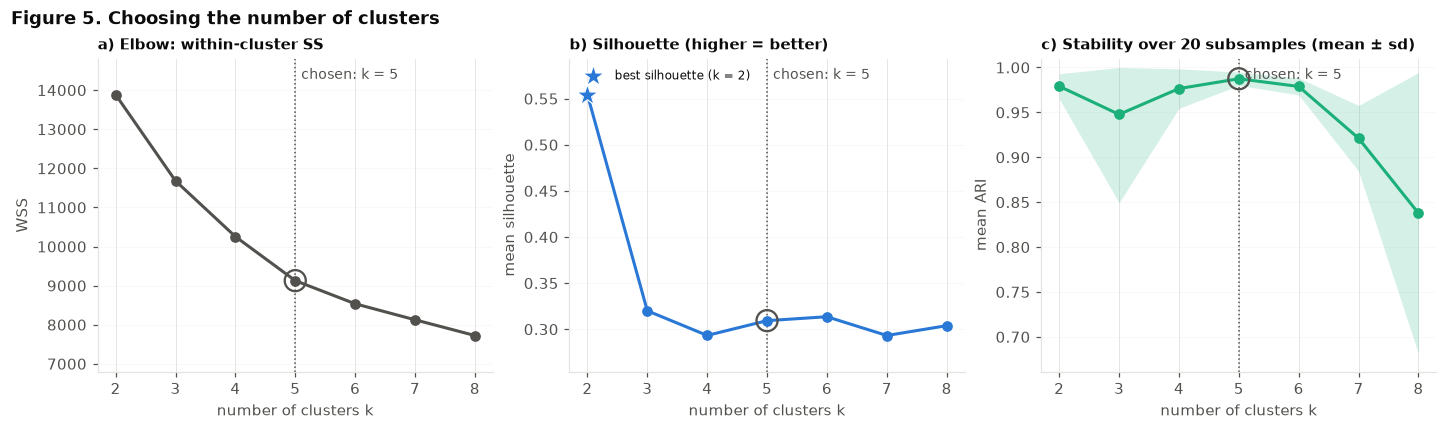

In [21]:
# Set this to the k you actually chose
K_CHOSEN = 5  # <- change to your selected k

k_vals = ksel.index.to_numpy()
best_sil_k = ksel["silhouette"].idxmax()

ari = ksel["stability (mean ARI)"]
ari_sd = ksel["stability sd"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)

# a) Elbow
ax = axes[0]
ax.plot(k_vals, ksel["WSS"], marker="o", markersize=6, linewidth=2, color=INK2, zorder=3)
ax.set_title("a) Elbow: within-cluster SS", loc="left", fontsize=10)
ax.set_ylabel("WSS")

# b) Silhouette
ax = axes[1]
ax.plot(k_vals, ksel["silhouette"], marker="o", markersize=6, linewidth=2, color=C_BLUE, zorder=3)
ax.scatter(best_sil_k, ksel.loc[best_sil_k, "silhouette"], marker="*", s=220,
           color=C_BLUE, edgecolors="white", linewidths=0.8, zorder=5,
           label=f"best silhouette (k = {best_sil_k})")
ax.legend(loc="best", frameon=False, fontsize=8)
ax.set_title("b) Silhouette (higher = better)", loc="left", fontsize=10)
ax.set_ylabel("mean silhouette")

# c) Stability: line with an sd band instead of error bars
ax = axes[2]
ax.plot(k_vals, ari, marker="o", markersize=6, linewidth=2, color=C_AQUA, zorder=3)
ax.fill_between(k_vals, ari - ari_sd, np.minimum(ari + ari_sd, 1.0),
                color=C_AQUA, alpha=0.18, linewidth=0)
ax.set_ylim(min(0.8, (ari - ari_sd).min() - 0.02), 1.01)
ax.set_title("c) Stability over 20 subsamples (mean ± sd)", loc="left", fontsize=10)
ax.set_ylabel("mean ARI")

# Shared formatting
panel_cols = ["WSS", "silhouette", "stability (mean ARI)"]
for ax, col in zip(axes, panel_cols):
    # Highlight the chosen k
    ax.axvline(K_CHOSEN, color=INK2, linestyle=":", linewidth=1, zorder=1)
    ax.scatter(K_CHOSEN, ksel.loc[K_CHOSEN, col], s=190, facecolors="none",
               edgecolors=INK2, linewidths=1.5, zorder=4)
    ax.text(K_CHOSEN + 0.1, 0.97, f"chosen: k = {K_CHOSEN}",
            transform=ax.get_xaxis_transform(), va="top", ha="left",
            fontsize=9, color=INK2)

    ax.set_xlabel("number of clusters k")
    ax.set_xticks(list(K_RANGE))
    ax.margins(y=0.15)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig.suptitle("Figure 5. Choosing the number of clusters",
             x=0.0, ha="left", fontsize=12, fontweight="bold")

fig.savefig(f"{FIG_DIR}/fig5_choose_k.png", dpi=300, bbox_inches="tight")
plt.show()


#### Interpreting the Cluster Selection Results

Figure 5 compares the performance of K-Means across different values of K (2 to 8).

The three plots help us understand:

- **Elbow plot:** How much the within-cluster variation decreases as more clusters are added.
- **Silhouette plot:** How well the clusters are separated.
- **Stability plot:** Whether similar groups are produced when different subsets of the data are used.

We consider these results together rather than relying on one score alone.

Based on the overall clustering analysis, we select **K = 5** for the final model. This provides five room states that can be investigated and interpreted using their sensor characteristics.


## 2.3 Selecting and Evaluating Cluster Structure

Selecting an appropriate clustering configuration is important because different model settings can produce different groupings.

This subsection examines the evidence used to assess the resulting cluster structure.

The evaluation considers the separation and consistency of the discovered groups, alongside whether the resulting clusters provide an interpretable description of the sensor observations.

Quantitative evaluation is considered together with visual inspection and the practical meaning of the resulting groups.

The final interpretation should reflect the strengths and limitations of the available evidence.

In [22]:
K_FINAL = 5
km_final = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_SEED).fit(Xc)
W["cluster"] = km_final.labels_

# distance of each window to its own cluster centre (useful later for the anomaly person)
W["dist_to_centroid"] = np.linalg.norm(Xc - km_final.cluster_centers_[km_final.labels_], axis=1)

# median raw (unscaled) values per cluster, easier to interpret than z-scores
prof = W.groupby("cluster")[TYPE_FEATURES + ["hour"]].median().round(2)
prof["windows"] = W["cluster"].value_counts().sort_index()
prof

,temp_mean,temp_delta,light_mean,sound_mean,sound_max,CO2_excess_mean,CO2_slope_mean,pir_frac,hour,windows
cluster,,,,,,,,,,
0,26.18,0.01,141.11,0.64,3.32,492.50,1.67,0.57,17.0,82
1,25.28,0.00,0.00,0.06,0.09,5.00,0.00,0.00,5.0,545
2,25.86,-0.03,0.00,0.06,0.08,380.39,-2.12,0.00,19.5,88
3,25.10,0.00,20.27,0.07,0.10,5.00,0.00,0.00,10.0,216
4,25.93,0.01,69.88,0.26,1.28,205.00,0.80,0.28,15.0,113


## 2.4 Interpreting the Discovered Room-Usage Patterns

After identifying the cluster structure, the resulting groups are examined using their sensor characteristics and temporal behaviour.

This subsection investigates how temperature, light, sound, CO₂ and motion measurements vary across the discovered clusters.

The purpose is to understand what distinguishes one group of observations from another and whether the differences represent recurring room-usage patterns.

Occupancy labels may be used as supporting evaluation evidence, but the clusters are interpreted primarily through their sensor-derived characteristics.

The findings from this subsection provide the basis for examining sensor contributions and the robustness of the discovered structure.

In [23]:
# Name each cluster from its sensor profile (labels are NOT used)
def name_cluster(p, busiest):
    if p["pir_frac"] > 0:                       # motion in a typical window -> people present
        return "Busy: high light, CO₂ rising" if p.name == busiest else "Occupied: moderate activity"
    if p["light_mean"] > 0:                     # no motion but light > 0 -> daylight
        return "Empty: daylight only"
    if p["CO2_slope_mean"] < -0.5:              # dark, no motion, CO₂ still falling -> people just left
        return "Recently vacated: dark, CO₂ falling"
    return "Empty: dark (night)"

# of the clusters with motion, the one with the fastest-rising CO₂ is the "busy" one
busiest = prof.loc[prof["pir_frac"] > 0, "CO2_slope_mean"].idxmax()

CLUSTER_NAMES = {c: name_cluster(prof.loc[c], busiest) for c in prof.index}
assert len(set(CLUSTER_NAMES.values())) == K_FINAL, "two clusters got the same name, so check `prof`"

W["cluster_name"] = W["cluster"].map(CLUSTER_NAMES)

# fixed display order for every plot (quiet -> busy)
ORDER = ["Empty: dark (night)", "Empty: daylight only", "Recently vacated: dark, CO₂ falling",
         "Occupied: moderate activity", "Busy: high light, CO₂ rising"]
print(CLUSTER_NAMES)
W["cluster_name"].value_counts().loc[ORDER]

{0: 'Busy: high light, CO₂ rising', 1: 'Empty: dark (night)', 2: 'Recently vacated: dark, CO₂ falling', 3: 'Empty: daylight only', 4: 'Occupied: moderate activity'}


cluster_name
Empty: dark (night)                    545
Empty: daylight only                   216
Recently vacated: dark, CO₂ falling     88
Occupied: moderate activity            113
Busy: high light, CO₂ rising            82
Name: count, dtype: int64

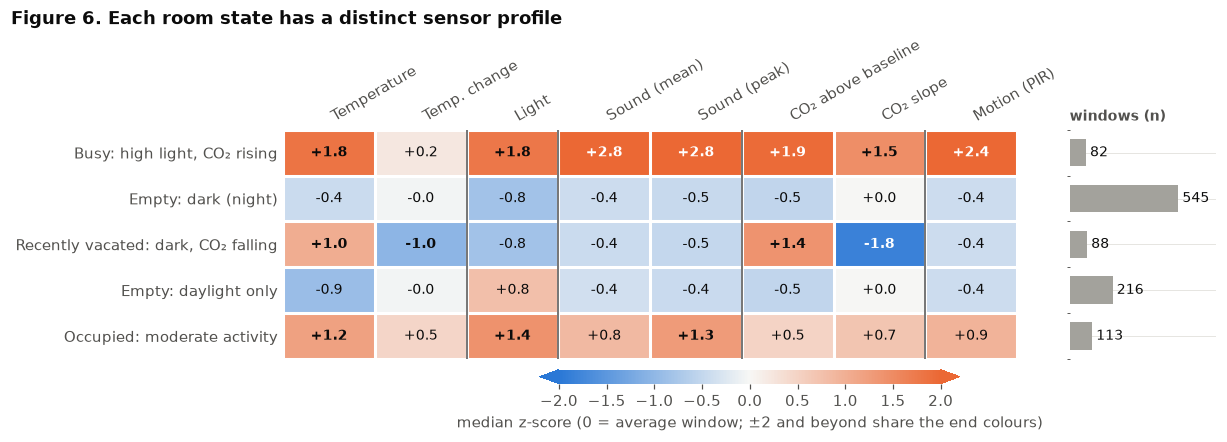

In [24]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

ORDER = list(CLUSTER_NAMES.values())          # row order on the plot
Z = (X_type.assign(cluster_name=W["cluster_name"])
           .groupby("cluster_name").median().loc[ORDER])
counts = W["cluster_name"].value_counts().loc[ORDER]

nice = {"temp_mean": "Temperature", "temp_delta": "Temp. change", "light_mean": "Light",
        "sound_mean": "Sound (mean)", "sound_max": "Sound (peak)",
        "CO2_excess_mean": "CO₂ above baseline", "CO2_slope_mean": "CO₂ slope",
        "pir_frac": "Motion (PIR)"}

# Which sensor each feature belongs to (used for separators between groups)
group = {"temp_mean": "temp", "temp_delta": "temp", "light_mean": "light",
         "sound_mean": "sound", "sound_max": "sound",
         "CO2_excess_mean": "co2", "CO2_slope_mean": "co2", "pir_frac": "pir"}

# Theme: blue (below average) -> near-white (average) -> orange (above average)
cmap = LinearSegmentedColormap.from_list("blue_orange", [C_BLUE, "#F7F7F5", C_ORANGE])
LIM = 2
norm = TwoSlopeNorm(vmin=-LIM, vcenter=0, vmax=LIM)

fig, (ax, axn) = plt.subplots(
    1, 2, figsize=(11, 3.9), sharey=True, constrained_layout=True,
    gridspec_kw={"width_ratios": [1, 0.2]}
)

# --- Heatmap ---
im = ax.imshow(Z.values, cmap=cmap, norm=norm, aspect="auto")

ax.set_xticks(range(Z.shape[1]))
ax.set_xticklabels([nice[c] for c in Z.columns], rotation=30, ha="left")
ax.xaxis.tick_top()
ax.set_yticks(range(len(ORDER)))
ax.set_yticklabels(ORDER)

# White cell borders
ax.set_xticks(np.arange(-0.5, Z.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-0.5, Z.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)

# Thicker separators between sensor groups
cols = list(Z.columns)
for j in range(len(cols) - 1):
    if group[cols[j]] != group[cols[j + 1]]:
        ax.axvline(j + 0.5, color=INK, linewidth=1.2, alpha=0.6)

# Cell values: text colour chosen from cell brightness, bold when |z| >= 1
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        v = Z.values[i, j]
        r, g, b, _ = cmap(norm(v))
        dark_cell = (0.299 * r + 0.587 * g + 0.114 * b) < 0.55
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                fontweight="bold" if abs(v) >= 1 else "normal",
                color="white" if dark_cell else INK)

# --- Cluster size panel ---
axn.barh(range(len(ORDER)), counts.values, color=C_GREY, height=0.6)
for i, n in enumerate(counts.values):
    axn.text(n, i, f" {n:,}", va="center", ha="left", fontsize=9, color=INK)
axn.set_xlim(0, counts.max() * 1.35)
axn.set_xticks([])
axn.tick_params(left=False)
axn.set_title("windows (n)", fontsize=9, color=INK2)
for s in axn.spines.values():
    s.set_visible(False)

# --- Colourbar ---
cb = fig.colorbar(im, ax=[ax, axn], location="bottom", shrink=0.45,
                  pad=0.04, aspect=30, extend="both")
cb.set_label("median z-score (0 = average window; ±2 and beyond share the end colours)")
cb.outline.set_visible(False)

fig.suptitle("Figure 6. Each room state has a distinct sensor profile",
             x=0.0, ha="left", fontsize=12, fontweight="bold")

fig.savefig(f"{FIG_DIR}/fig6_cluster_profiles.png", dpi=300, bbox_inches="tight")
plt.show()


### 2.5 Analysing Room States Over Time

Identifying five clusters is useful, but we also need to understand when these room conditions occur.

In this step, we visualise the cluster assignments across the three recording periods.

Each colour represents one of the five identified room states. We also display the recorded occupancy count underneath the cluster timeline.

The occupancy information is included only for comparison and evaluation. It was not used to train the K-Means model.

#### What are we looking for?

We want to understand whether the identified room states appear in meaningful time periods.

For example:

- Does the empty nighttime cluster appear during overnight periods?
- Does the daylight cluster appear during daytime when the room is empty?
- Does the recently vacated cluster appear after occupied periods?
- Do the occupied clusters appear when people are recorded inside the room?

If the clusters represent meaningful room conditions, we would expect them to form reasonably consistent periods rather than appearing randomly throughout the timeline.


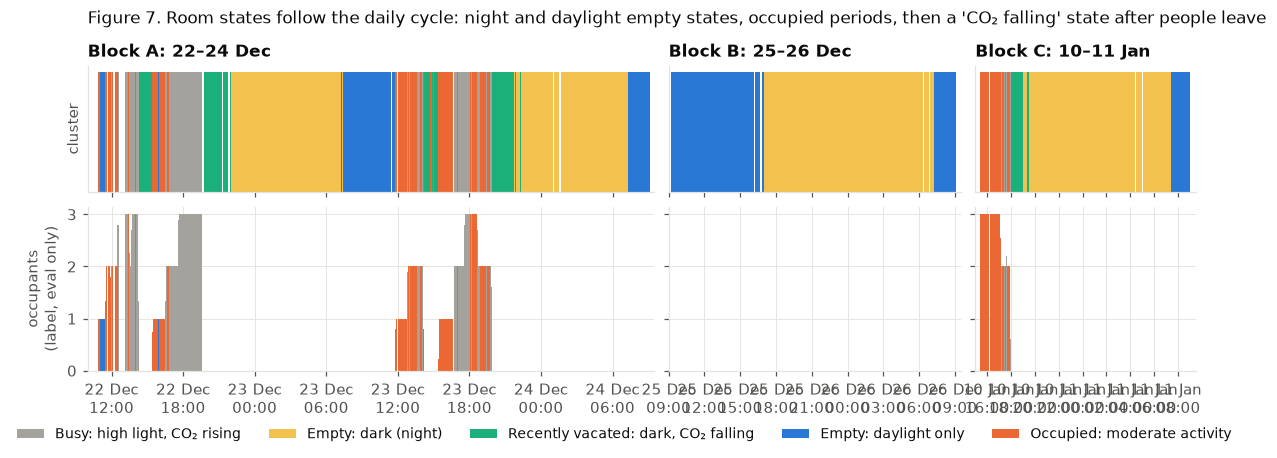

In [25]:
CL_COL = dict(zip(ORDER, [C_GREY, "#f2c14e", C_AQUA, C_BLUE, C_ORANGE]))

fig, axes = plt.subplots(2, 3, figsize=(13, 3.6), sharey="row",
                         gridspec_kw={"width_ratios": widths, "height_ratios": [1, 1.3],
                                      "wspace": 0.04, "hspace": 0.1})
occ = W_lab["occ_mean"]   # evaluation only

for j, (a, b, title) in enumerate(blocks):
    in_block = (W["start"] >= a) & (W["start"] <= b)
    for n in ORDER:
        m = in_block & (W["cluster_name"] == n)
        axes[0, j].bar(W.loc[m, "start"], 1, width=pd.Timedelta(minutes=5), color=CL_COL[n],
                       linewidth=0, align="edge", label=n if j == 0 else None)
        axes[1, j].bar(W.loc[m, "start"], occ[m], width=pd.Timedelta(minutes=5), color=CL_COL[n],
                       linewidth=0, align="edge")
    for ax in axes[:, j]:
        ax.set_xlim(a, b)
        # ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
    axes[0, j].set_title(title); axes[0, j].set_yticks([])
    axes[0, j].tick_params(labelbottom=False); axes[0, j].grid(False)

axes[0, 0].set_ylabel("cluster")
axes[1, 0].set_ylabel("occupants\n(label, eval only)"); axes[1, 0].set_yticks([0, 1, 2, 3])
fig.legend(loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.1), fontsize=9)
fig.suptitle("Figure 7. Room states follow the daily cycle: night and daylight empty states, "
             "occupied periods, then a 'CO₂ falling' state after people leave",
             x=0.125, ha="left", fontsize=11, y=1.02)
fig.savefig(f"{FIG_DIR}/fig7_clusters_timeline.png"); plt.show()


#### Interpretation of the Timeline

Figure 7 shows that the identified room states follow recognisable patterns across the recording periods.

**Key observations:**

1. **Nighttime conditions:** The dark, empty cluster mainly appears overnight, when light and movement measurements are low.

2. **Daylight conditions:** The daylight-only cluster appears during daytime periods, including the Christmas recording block when the room was recorded as empty.

3. **Recently vacated conditions:** The CO₂-falling cluster appears immediately after occupied periods end. This supports the interpretation that CO₂ takes time to decrease after people leave.

4. **Occupied conditions:** The two occupied clusters appear during periods when people are present. They sometimes alternate rapidly because they represent different sensor activity patterns.

These observations suggest that the clustering model is capturing meaningful changes in room conditions over time.

However, the two occupied clusters do not reliably distinguish the exact number of people in the room.



### 2.6 Evaluating the Clustering Results Against Occupancy Labels

After identifying and interpreting the five room states, we evaluate whether they correspond to the actual recorded occupancy information.

This is an important step because our clustering model was trained without using occupancy labels.

We now compare the cluster assignments with `W_lab`, which contains the recorded occupancy information for each 5-minute window.

#### What do we evaluate?

We investigate three main questions:

**1. Can the model distinguish an empty room from an occupied room?**

We combine the two occupied clusters into one category and compare them with the recorded empty/occupied labels.

We calculate the percentage of windows where both agree.

**2. How well do the clusters represent the exact number of occupants?**

We compare the five cluster assignments against the recorded head-count categories (0, 1, 2, and 3 people) using the Adjusted Rand Index (ARI).

**3. How do five clusters relate to a simpler two-cluster solution?**

We also run K-Means with K = 2 to investigate whether the five room states provide additional detail beyond a simple empty-versus-occupied distinction.

#### Understanding the evaluation measures

- **Agreement percentage:** The proportion of windows where the predicted empty/occupied category matches the recorded occupancy category.
- **Adjusted Rand Index (ARI):** Measures the similarity between two groupings while accounting for agreement that could occur by chance. A value closer to 1 indicates stronger agreement, while values around 0 indicate agreement similar to chance.

These comparisons help us understand both the strengths and limitations of the clustering approach.


In [26]:
# 1. How many windows of each head-count fall in each cluster?
ct = pd.crosstab(W["cluster_name"], W_lab["occ_mode"]).loc[ORDER]
ct.columns = [f"{c} people" for c in ct.columns]
print("Windows per cluster by most common head-count:")
display(ct)

# 2. Empty vs occupied: do the two 'people' clusters match the label?
occ_pred = W["cluster_name"].str.startswith(("Busy", "Occupied"))
agree = 100 * (occ_pred == W_lab["occupied"]).mean()
print(f"Empty vs occupied agreement: {agree:.1f}%  "
      f"(ARI {adjusted_rand_score(W_lab['occupied'], occ_pred):.2f})")

# 3. Exact head-count (0, 1, 2, 3): much harder
print(f"ARI, 5 clusters vs head-count 0–3: {adjusted_rand_score(W_lab['occ_mode'], W['cluster']):.2f}")

# 4. Are the 5 clusters a finer version of the k = 2 split?
k2 = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_SEED).fit_predict(Xc)
print("\nk = 5 clusters inside the k = 2 split:")
display(pd.crosstab(W["cluster_name"], k2).loc[ORDER])

Windows per cluster by most common head-count:


,0 people,1 people,2 people,3 people
cluster_name,,,,
"Busy: high light, CO₂ rising",2,1,36,43
Empty: dark (night),545,0,0,0
"Recently vacated: dark, CO₂ falling",88,0,0,0
Empty: daylight only,210,6,0,0
Occupied: moderate activity,5,41,38,29


Empty vs occupied agreement: 99.1%  (ARI 0.96)
ARI, 5 clusters vs head-count 0–3: 0.35

k = 5 clusters inside the k = 2 split:


col_0,0,1
cluster_name,,
"Busy: high light, CO₂ rising",82,0
Empty: dark (night),0,545
"Recently vacated: dark, CO₂ falling",1,87
Empty: daylight only,0,216
Occupied: moderate activity,98,15


### Results and Interpretation
The five-cluster solution achieves 99.1% agreement with the empty-versus-occupied labels (ARI = 0.96), showing that sensor measurements strongly distinguish these conditions without using occupancy labels during training.

However, agreement decreases when predicting the exact number of occupants (0–3), with an ARI of 0.35. The clusters therefore distinguish occupancy states better than precise occupancy counts.

The five clusters also reveal additional environmental patterns, including empty rooms with light, empty rooms at night, and periods of decreasing CO₂.

Only 16 of 1,044 windows cross over between the two-cluster and five-cluster grouping comparison, suggesting that K = 5 provides more detailed room-condition patterns while largely preserving the empty-versus-occupied structure.

A small number of mismatched observations may represent transition periods, unusual sensor behaviour or occupancy-label inconsistencies. These are potential candidates for further investigation in Section 8.

Overall finding: Clustering identifies empty and occupied conditions effectively, while also revealing different environmental patterns within empty-room periods. However, it is less reliable at distinguishing the exact number of occupants.

In [27]:
os.makedirs("data/results", exist_ok=True)
W[["segment", "win", "start", "cluster", "cluster_name", "dist_to_centroid"]].to_csv(
    "data/results/clusters_k5.csv", index=False)
print("saved data/results/clusters_k5.csv", len(W), "windows")

saved data/results/clusters_k5.csv 1044 windows



# 3. Validation and Sensor Contribution

The previous section identified five clusters representing recurring patterns in the room sensor measurements. However, it is important to assess whether these patterns are reliable and how strongly they depend on the selected clustering method, feature representation and sensor measurements.

This section evaluates the robustness of the discovered clusters and investigates the contribution of individual sensor groups. We compare alternative clustering configurations, examine the effect of different feature representations and assess how much information each sensor group contributes to the discovered structure.

The analysis is organised around five investigations:

- **Clustering stability:** Examine whether the discovered clusters remain consistent across different initialisations and recording periods.
- **Clustering method comparison:** Compare K-Means with Gaussian Mixture Models to determine whether similar structures are identified using a different clustering approach.
- **Feature representation comparison:** Investigate whether using individual desk-level measurements or aggregated sensor-type features changes the clustering structure.
- **Sensor contribution:** Evaluate the importance of each sensor group by examining how the clustering results change when sensor information is removed or considered separately.
- **Sensor-group relationships:** Investigate whether different sensor groups provide independent information or capture overlapping patterns.

These comparisons help establish how confidently the discovered room-usage patterns can be interpreted and which sensor measurements contribute most to distinguishing them.

### Glossary
| Term | Meaning here |
|---|---|
| **Window** | One row: five minutes of sensor readings summarised into 24 numbers. |
| **k-means** | Gives each window to the nearest of *k* cluster centres, moves the centres to the middle of their windows, and repeats (course notes 4.4.1). |
| **Cluster number** | An arbitrary name. Cluster 2 in one run is not cluster 2 in another, so clusterings are compared with ARI or a crosstab, never by matching numbers. |
| **ARI** (adjusted Rand index) | How much two clusterings of the same windows agree. 1 means identical groupings, about 0 means no better than chance. It ignores the numbering. |
| **Crosstab** | A table counting how many windows fall in each pair of clusters (like the confusion matrix in Chapter 5). The simple alternative to ARI: big numbers in a single column per row mean the two clusterings agree. |
| **Read-out accuracy** *(check only)* | Label each cluster with the majority answer among its windows ("occupied" or "empty"), then count the share of windows that label gets right. It measures how much a clustering tells us about occupancy. It needs comparing with the "guess the common answer for everyone" level, which is printed next to it. |
| **Ablation** | Remove one sensor group, refit, and see how much the clusters change. |
| **PCA** | Finds the two directions along which the windows vary most, so 24 numbers can be drawn on a flat plot (Chapter 8, slides 20 to 25). |
| **Covariance ellipse** | The Gaussian mixture's description of a cluster: its centre, how spread out it is, and the direction it is stretched. |
| **R²** | Share of a feature's variation that a model predicts correctly on data it has not seen. 1 = perfect, 0 = no better than the average, below 0 = worse. |
| **Leave-one-day-out** | Refit with one recording day removed, once for each of the seven days, and see whether the clusters survive. |

**Where the code runs.** Put this notebook in the folder that holds the data files (`windows_5min.csv`, `windows_5min_labels.csv`, `feature_groups.json`, `clusters_k5.csv`). It looks in the current folder, then `data/prepared` and `data/results`.



## 3.1 Clustering Stability

Clustering results can be influenced by the initial positions of cluster centroids and the observations included in the analysis. Therefore, a clustering solution should be examined to determine whether it produces consistent groupings under different conditions.

This investigation evaluates the stability of the selected K-Means solution using two approaches.

First, repeated model initialisations are used to examine whether different starting positions produce similar clustering results. Second, a leave-one-day-out analysis investigates whether the discovered structure changes when one recording period is excluded.

The Adjusted Rand Index (ARI) is used to compare clustering assignments. Higher ARI values indicate greater agreement between clustering solutions.

This analysis helps determine whether the selected five-cluster structure is reasonably consistent or strongly dependent on particular initialisation choices or recording periods.


In [28]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt   # json reads feature_groups.json; numpy and pandas hold the data; matplotlib draws the figure
from pathlib import Path                                           # lets us test whether a file exists
from sklearn.preprocessing import StandardScaler                   # converts each column to z-scores (mean 0, standard deviation 1)
from sklearn.cluster import KMeans                                 # the clustering algorithm Person 2 used
from sklearn.mixture import GaussianMixture                        # the alternative method we compare against (Chapter 5)
from sklearn.metrics import adjusted_rand_score as ARI             # the agreement score between two clusterings (see glossary)

SEED = 42      # fixes every random choice so that re-running gives the same numbers
K = 5          # number of clusters, chosen by Person 2

def find(name):                                    # looks for a data file by name
    for d in [".", "data/prepared", "data/results"]:   # the three places the group's files can be
        if (Path(d) / name).exists():              # if the file is in this folder...
            return Path(d) / name                  # ...return its path
    raise FileNotFoundError(f"{name} not found: open this notebook from the folder that holds the data")

In [29]:
W_main = W.copy()   # MERGE FIX: Sections 1-2 table (datetime 'start', clusters, X_node-aligned). Section 3 reuses the name W, so keep a copy for Section 4
W = pd.read_csv(find("windows_5min.csv"))                 # features: one row per 5-minute window
L = pd.read_csv(find("windows_5min_labels.csv"))          # occupancy labels, same row order. CHECK ONLY, never used to fit
fg = json.load(open(find("feature_groups.json")))         # which columns belong to which sensor group
groups = fg["node_level"]                                 # dict: group name -> its columns (temperature 8, light 4, sound 8, co2 2, motion 2)
cols = sum(groups.values(), [])                           # all 24 feature columns in one flat list
type_cols = fg["sensor_type_level"]                       # the 8 per-sensor-type columns (desks averaged together)
skewed = [c for c in cols + type_cols if "light" in c.lower() or "sound" in c.lower()]   # light and sound columns get the log transform
assert not any("occ" in c.lower() for c in cols + type_cols)   # safety check: no label column has slipped in as a feature

def scale(df, columns):                                   # log-transform the skewed columns, then standardise every column
    X = df[columns].copy()                                # work on a copy so the original table is untouched
    for c in columns:
        if c in skewed:
            X[c] = np.log1p(X[c])                         # log(1 + x): shrinks big values, and is safe when x = 0
    return pd.DataFrame(StandardScaler().fit_transform(X), columns=columns, index=df.index)

X = scale(W, cols)                                        # the 24-feature table every clustering below uses
X_type = scale(W, type_cols)                              # the 8-feature version, used in the representation comparison

occupied = L["occupied"].to_numpy(bool)                   # CHECK ONLY: True if anyone was in the room in that window
empty = ~occupied                                         # CHECK ONLY: the opposite
daytime = W["hour"].between(7, 16).to_numpy()             # context from the clock, not a label: 07:00-16:59, when light comes through the window (group Figure 2)
print(len(W), "windows;", X.shape[1], "features;", {g: len(c) for g, c in groups.items()})

1044 windows; 24 features; {'temperature': 8, 'light': 4, 'sound': 8, 'co2': 2, 'motion': 2}


## The baseline is Person 2's clustering
Every comparison needs a reference. Person 2's labels are loaded and lined up with the windows by `segment` and `win`, which together identify a window. As a check, a fresh k-means with the same settings should reproduce their labels exactly (ARI = 1).

In [30]:
try:
    p2 = pd.read_csv(find("clusters_k5.csv"))                                              # Person 2's saved labels
    m = W[["segment", "win"]].merge(p2, on=["segment", "win"], how="left")                  # match each window to its label
    base, base_name = m["cluster"].to_numpy(int), m["cluster_name"].to_numpy()              # their cluster number and cluster name
except FileNotFoundError:                                                                   # if their file is not here...
    base = KMeans(K, n_init=20, random_state=SEED).fit_predict(X)                          # ...refit; the labels come out identical
    base_name = np.array([f"cluster {c}" for c in base])                                    # no names available, so use the numbers
print("cluster sizes:", np.bincount(base))                                                  # how many windows in each cluster
print("check, ARI vs a fresh k-means refit:", ARI(base, KMeans(K, n_init=20, random_state=SEED).fit_predict(X)))   # should print 1.0

cluster sizes: [ 82 545  88 216 113]
check, ARI vs a fresh k-means refit: 1.0


## Are the clusters stable?
### Does k-means depend on its starting centres?
The course notes (4.4 and 4.5) warn that k-means "is very sensitive to the randomly-chosen cluster centers". Here it is tested directly: fit k-means seven times with a **single** random start each, and compare with the baseline. The baseline itself used 20 starts and kept the best, which is why it is reliable.

In [31]:
single = [ARI(base, KMeans(K, n_init=1, random_state=s).fit_predict(X)) for s in range(1, 8)]   # n_init=1: one random start only, 7 different seeds
print("ARI vs baseline, one random start each:", np.round(single, 2))                            # low values = that start landed on a different solution

ARI vs baseline, one random start each: [1.   0.99 0.81 0.9  0.4  0.98 0.99]


**Reading it.** Most single starts reproduce the baseline, but some land on a clearly different solution. That is why the baseline uses 20 starts and keeps the best fit. It does not show that the clusters are unreal, only that one run is not enough.

### Do the clusters survive leaving out a whole day?
This is the course-notes test of a "different sample". The data cover seven recording days. For each day in turn we remove it, fit k-means on the other six, then use that fitted model to label **all** windows (including the left-out day) so the result can be compared with the baseline using ARI. A high ARI means the clusters do not depend on any single day.

Whole days are removed rather than random windows because neighbouring windows are near-copies, so removing random windows would make the clusters look more stable than they are. We repeat this for k = 3, 4, 5 and 6 to see whether five is a fragile choice (course notes 4.5: "observing how the characteristics of the clusters change as k is varied").

In [32]:
dates = sorted(W["date"].unique())                                   # the seven recording days
FOLDS = [np.where(W["date"] != d)[0] for d in dates]                 # for each day: the row numbers of every window NOT on that day

def refit(Xm, k, idx, seed):                                         # fit without one day, then label every window
    model = KMeans(k, n_init=5, random_state=seed).fit(Xm.iloc[idx]) # fit k-means using only the kept rows
    return model.predict(Xm)                                         # label ALL windows with that model so results can be compared

full_fold = [refit(X, K, idx, i) for i, idx in enumerate(FOLDS)]     # the 24-feature model refitted without each day (reused in section 7)
print("k=5, ARI vs baseline when each day is left out:")
print(pd.Series([ARI(base, l) for l in full_fold], index=dates).round(2).to_string())

stab = {}                                                            # stability for each k
for k in [3, 4, 5, 6]:
    ref = base if k == K else KMeans(k, n_init=20, random_state=SEED).fit_predict(X)   # the full-data clustering at this k
    r = np.array([ARI(ref, refit(X, k, idx, i)) for i, idx in enumerate(FOLDS)])        # leave each day out, compare with it
    stab[k] = {"median ARI": np.median(r), "worst day": r.min(), "day left out in the worst case": dates[int(r.argmin())]}
pd.DataFrame(stab).T

k=5, ARI vs baseline when each day is left out:
2017-12-22    0.93
2017-12-23    0.98
2017-12-24    0.99
2017-12-25    0.96
2017-12-26    0.99
2018-01-10    0.99
2018-01-11    1.00


,median ARI,worst day,day left out in the worst case
3,0.94473,0.494069,2017-12-25
4,0.953569,0.411679,2017-12-25
5,0.990693,0.934007,2017-12-22
6,0.978061,0.834528,2017-12-22


**Reading it.** A high median and a high worst case mean the clustering rarely changes much when a day is removed. k = 5 has the best worst case of the four, so Person 2's choice is not a fragile one. The worst case for k = 5 is 22 December; for k = 3 and 4 it is 25 December. This is evidence of *stability*, which is not proof that five states are real.


## 3.2 Comparison of Clustering Methods

Although K-Means provides the main clustering solution, its assumptions may influence the patterns it identifies. To examine this, Gaussian Mixture Models (GMM) are used as an alternative clustering approach.

Unlike K-Means, which assigns observations according to their distance from cluster centroids, GMM models the data as a mixture of probability distributions. This allows observations to have different probabilities of belonging to different clusters.

The two methods are compared using the Adjusted Rand Index (ARI) and cluster-assignment comparisons. This helps establish whether the broad sensor-based patterns are consistent across different clustering approaches.

The comparison is not intended to identify a universally superior algorithm, but to assess how sensitive the discovered structure is to the choice of clustering method.


## does the clustering method matter? (k-means vs Gaussian mixture)
**What is being tested.** k-means assumes clusters are roughly round and similar in size. A Gaussian mixture (Chapter 5, slides 41 to 49) lets each cluster be an ellipse of its own shape and size. If both methods find similar groups, that assumption is not driving the result. We use the standard setting where each cluster has its own ellipse.

In [33]:
gmm = GaussianMixture(K, covariance_type="full", n_init=10, reg_covar=1e-3, random_state=SEED).fit(X)   # K elliptical clusters; 10 restarts; reg_covar keeps the fit numerically stable
lab_gmm = gmm.predict(X)                                             # each window goes to its most likely cluster
print("ARI vs baseline:", round(ARI(base, lab_gmm), 2))              # agreement with Person 2's k-means partition
print("free parameters:", gmm._n_parameters(), "for", len(W), "windows")   # how many numbers the model had to estimate, against how many windows there are
print("mean confidence in the assigned cluster:", round(gmm.predict_proba(X).max(1).mean(), 3))   # average probability of each window's best cluster
pd.crosstab(pd.Series(base, name="k-means (baseline)"), pd.Series(lab_gmm, name="mixture"))   # where the two methods agree and disagree

ARI vs baseline: 0.76
free parameters: 1624 for 1044 windows
mean confidence in the assigned cluster: 1.0


mixture,0,1,2,3,4
k-means (baseline),,,,,
0,82,0,0,0,0
1,0,468,41,32,4
2,0,0,88,0,0
3,0,0,0,208,8
4,33,0,0,0,80


**Reading it.** An ARI around 0.76 means the two methods agree on most of the structure but not all; the crosstab shows which clusters they split or merge differently (cluster numbers differ, so look for large numbers). The mixture has more free parameters than there are windows, and its confidence is about 1 for every window, so it is over-flexible and its confidence scores say little. Treat this as evidence that k-means' round-cluster assumption is not the main driver, not as proof that either method is right.


## 3.3 Comparison of Feature Representations

The representation of sensor measurements can influence the structure discovered through clustering. In the previous analysis, sensor measurements were aggregated into sensor-type features to provide a more compact representation of room conditions.

This investigation compares two feature representations:

- **Desk-level representation:** Retains individual sensor measurements from different desk locations.
- **Sensor-type representation:** Aggregates measurements by sensor type to describe broader environmental conditions.

Both representations are evaluated using the same clustering approach and number of clusters. Their resulting assignments and cluster distributions are compared using the Adjusted Rand Index (ARI).

This comparison investigates whether retaining individual desk-level information provides additional distinctions or whether the aggregated sensor-type representation captures the main room-usage patterns sufficiently.


## does the representation matter? (per-desk vs per-sensor-type)
The baseline uses 24 features (each sensor at each of four desks). The alternative averages across desks to give 8 features. If per-desk detail matters, the two clusterings would differ. This is the "choose appropriate attributes" step of the course notes.

In [34]:
lab_type = KMeans(K, n_init=20, random_state=SEED).fit_predict(X_type)         # k-means on the 8 sensor-type features
print("ARI, sensor-type vs baseline:", round(ARI(base, lab_type), 2), "| cluster sizes:", np.bincount(lab_type))   # sizes show if any cluster is tiny

ARI, sensor-type vs baseline: 0.88 | cluster sizes: [539 101 149 247   8]


## which sensor group do the clusters depend on? (ablation)
**Idea.** Remove one sensor group (temperature, light, sound, CO₂ or motion), refit k-means with the same k, and measure how much the clustering changes. A big drop in ARI means the clustering **depends on** that group. We also do the reverse: cluster using one group alone ("keep one").

**Three numbers for each run**
- **ARI vs baseline**: how much the clusters changed.
- **Occupancy read-out** *(check only)*: if each cluster is labelled "occupied" or "empty" by its majority, what share of windows are labelled correctly? Did the clusters lose occupancy information?
- **Day/night read-out** *(check only)*: the same, but only for empty windows, labelling each cluster "day" or "night". Did the clusters lose the daylight split? This matters because light turns out to be mostly measuring daylight.

Each read-out has a "guess the common answer for everyone" level (printed below) to compare against.

**Uncertainty.** For ARI we repeat each run with each day left out (same days left out for the full and the reduced model) and report the range across the seven days.

In [35]:
def X_for(gs, equal=False):                                                     # feature table for a list of sensor groups
    parts = []
    for g in gs:
        Z = scale(W, groups[g])                                                # scale this group's columns
        parts.append(Z / np.sqrt(len(groups[g])) if equal else Z)              # optional: shrink by sqrt(#columns) so every group gets equal total weight
    return pd.concat(parts, axis=1)                                            # put the groups side by side

def km(Xv, k=K):                                                               # full-data k-means, shorthand
    return KMeans(k, n_init=20, random_state=SEED).fit_predict(Xv)

def readout(lab, truth):                                                       # share of windows labelled correctly if each cluster takes its majority label
    return pd.crosstab(lab, truth).max(axis=1).sum() / len(truth)              # per cluster: size of its larger group; add up; divide by total

guess_occ = max(occupied.mean(), empty.mean())                                 # reference: say "empty" for every window
guess_day = max(daytime[empty].mean(), 1 - daytime[empty].mean())              # reference: say "night" for every empty window
print(f"Guess-everyone levels: occupancy {guess_occ:.0%}, day/night {guess_day:.0%}")

variants = {"all groups": list(groups)}                                        # every group
variants.update({f"drop {g}": [x for x in groups if x != g] for g in groups})  # all groups except one
variants.update({f"only {g}": [g] for g in groups})                            # one group alone

res, labels = {}, {}                                                           # results table and the labels from each variant
for name, gs in variants.items():
    Xv = X_for(gs); lab = labels[name] = km(Xv)                                # fit on all windows
    row = {"ARI": ARI(base, lab),                                              # how much the clusters changed
           "occupancy_readout": readout(lab, occupied),                        # check only
           "daynight_readout": readout(lab[empty], daytime[empty])}            # check only
    if name != "all groups":
        r = np.array([ARI(full_fold[i], refit(Xv, K, idx, i)) for i, idx in enumerate(FOLDS)])   # same day left out for the full and the reduced model
        row.update({"ARI_median": np.median(r), "ARI_min": r.min(), "ARI_max": r.max()})         # range across the seven days
    res[name] = row
res = pd.DataFrame(res).T
res.round(2)

Guess-everyone levels: occupancy 81%, day/night 70%


,ARI,occupancy_readout,daynight_readout,ARI_median,ARI_min,ARI_max
all groups,1.00,0.99,0.95,NaN,NaN,NaN
drop temperature,0.89,0.98,0.97,0.80,0.76,0.89
drop light,0.39,0.98,0.70,0.38,0.27,0.55
drop sound,0.89,0.95,0.98,0.90,0.85,0.92
drop co2,0.83,0.97,0.98,0.83,0.57,0.90
drop motion,0.97,0.99,0.96,0.98,0.97,0.99
only temperature,0.20,0.91,0.70,0.20,0.16,0.38
only light,0.73,0.98,0.98,0.73,0.69,0.73
only sound,0.35,0.99,0.71,0.34,0.33,0.35
only co2,0.38,0.94,0.70,0.39,0.38,0.42


**Reading it.**
- *ARI*: for "drop light" it is far below the other drops, so the clustering depends on light. The `ARI_min` to `ARI_max` columns give the range across the seven leave-one-day-out refits. Keep-one rows show which group can carry the structure alone (light can; the others cannot).
- *`daynight_readout`* for "drop light" falls to close to the guess-everyone level, while *`occupancy_readout`* barely moves: removing light destroys the day/night split but not the occupancy information. That is the evidence that light here mostly encodes **daylight**, not occupancy.
- The read-outs are single fits with no interval, so differences of a percentage point or two should not be over-interpreted.

In [36]:
# Inspect the smallest cluster in the sensor-type representation
small_cluster = np.argmin(np.bincount(lab_type))
small_windows = W.loc[np.asarray(lab_type) == small_cluster]

sensor_columns = [
    col for cols in groups.values()
    for col in cols
]

print("Smallest cluster:", small_cluster)
print("Number of windows:", len(small_windows))

print("\nMean sensor profile:")
display(small_windows[sensor_columns].mean().round(2).to_frame("Mean"))

Smallest cluster: 4
Number of windows: 8

Mean sensor profile:


,Mean
S1_Temp_mean,25.74
S2_Temp_mean,27.06
S3_Temp_mean,25.24
S4_Temp_mean,26.05
S1_Temp_delta,0.03
S2_Temp_delta,0.69
S3_Temp_delta,0.03
S4_Temp_delta,0.06
S1_Light_mean,153.67
S2_Light_mean,224.12


### Interpretation of the Smallest Cluster

The sensor-type representation produced a small cluster (Cluster 4) containing only 8 of the 1,044 analysed windows (approximately 0.77%). Inspection of its sensor profile revealed a combination of relatively high light readings, elevated CO₂ levels, positive CO₂ trends, increased PIR activity and higher sound readings. In particular, the mean PIR fractions were 0.76 and 0.63, while the mean CO₂ excess was 244.10.

These observations suggest that the cluster captures a relatively uncommon combination of environmental conditions and sensor activity. However, its small size means that it is difficult to establish whether it represents a distinct room-usage pattern, a short-lived event or unusual sensor behaviour. Therefore, it is retained as a potentially meaningful small cluster rather than automatically classified as an anomaly.

This finding also illustrates a limitation of feature aggregation: although sensor-type aggregation preserves much of the overall clustering structure, it may conceal local differences between individual sensors.


## 3.4 Sensor Contribution and Importance

The discovered clusters are based on multiple sensor measurements, including temperature, light, sound, CO₂ and PIR motion. However, not all sensor groups necessarily contribute equally to distinguishing room conditions.

To investigate their individual contributions, a sensor ablation analysis is performed. This involves removing one sensor group at a time and repeating the clustering analysis using the remaining features.

The resulting cluster assignments are compared with the baseline five-cluster solution using the Adjusted Rand Index (ARI). A larger change in ARI indicates that removing the corresponding sensor group has a greater effect on the original clustering structure.

Additional comparisons examine the clustering structure when individual sensor groups are used independently. This provides further insight into the information captured by each sensor type.

The analysis helps identify which sensor groups contribute most strongly to the discovered patterns. However, the results indicate their contribution to this particular clustering representation rather than proving that a sensor is universally more important for room occupancy.


In [37]:
base_eq = km(X_for(list(groups), equal=True))                                  # baseline with equally weighted groups
eq = pd.DataFrame({g: {"unweighted ARI": res.loc[f"drop {g}", "ARI"],         # drop-one result from above
                       "equal-weight ARI": ARI(base_eq, km(X_for([x for x in groups if x != g], equal=True))),   # same drop, equal weights
                       "columns in group": len(groups[g])} for g in groups}).T
print(eq.round(2).to_string())

ks = {}                                                                        # drop-one ARI at each k
for k in [2, 3, 4, 5]:
    b_k = km(X, k)                                                             # the all-groups clustering at this k
    ks[k] = {g: ARI(b_k, km(X_for([x for x in groups if x != g]), k)) for g in groups}   # remove each group, compare
pd.DataFrame(ks).round(2)

             unweighted ARI  equal-weight ARI  columns in group
temperature            0.89              0.93               8.0
light                  0.39              0.56               4.0
sound                  0.89              0.97               8.0
co2                    0.83              0.79               2.0
motion                 0.97              0.96               2.0


,2,3,4,5
temperature,0.92,0.94,0.91,0.89
light,0.88,0.36,0.40,0.39
sound,0.82,0.88,0.78,0.89
co2,0.99,0.96,0.99,0.83
motion,0.97,0.93,0.99,0.97


**Reading it.** Equal weighting: a group whose "equal-weight ARI" is lower than its "unweighted ARI" matters more than the unweighted result suggests. Only CO₂ moves that way, and only slightly (0.83 to 0.79); light, temperature and sound all look *less* important once column counts are equalised, though light is still clearly the most influential (0.56). By k: light matters at k = 3 to 5 but hardly at k = 2. At k = 2 the clusters are essentially empty versus occupied, so there is probably no room left to split the empty windows into day and night; this explanation is an inference, not something the notebook tests.

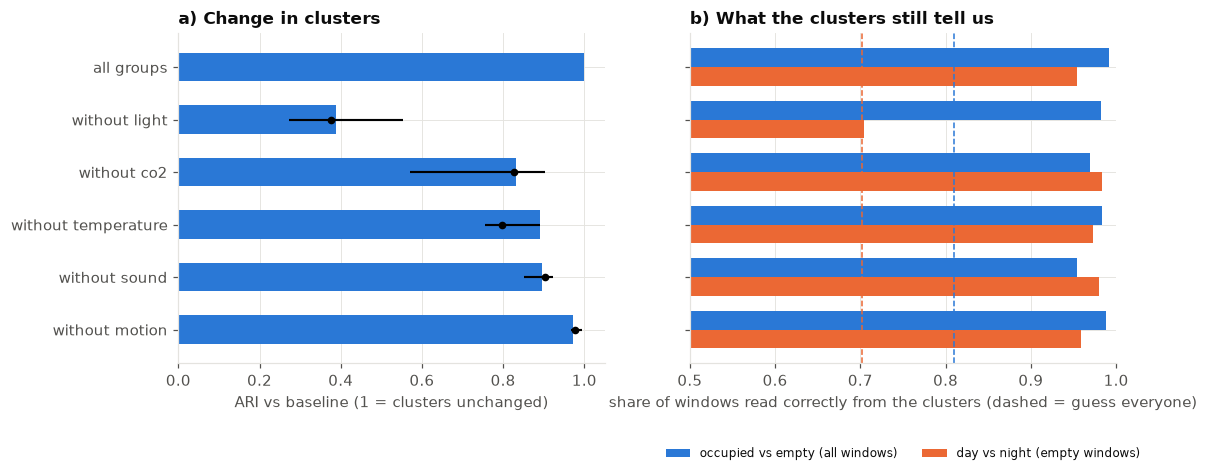

In [38]:
drops = sorted([f"drop {g}" for g in groups], key=lambda n: res.loc[n, "ARI"])  # drop-one variants, most influential first
order = ["all groups"] + drops                                                  # all-groups row on top as the reference
y = np.arange(len(order))                                                       # vertical positions
names = ["all groups"] + [o.replace("drop ", "without ") for o in drops]        # readable row labels
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)                    # sharey: both panels use the same row labels, written once on the left

ax[0].barh(y, res.loc[order, "ARI"], color="#2a78d6", height=0.55)             # bars: ARI vs baseline, all days
sub = res.loc[drops]                                                            # the rows that have a leave-one-day-out range
ax[0].errorbar(sub["ARI_median"], y[1:], xerr=[sub["ARI_median"] - sub["ARI_min"], sub["ARI_max"] - sub["ARI_median"]], fmt="o", color="black", ms=4)   # dot: median over days; line: min to max
ax[0].set_yticks(y); ax[0].set_yticklabels(names); ax[0].invert_yaxis()
ax[0].set_xlim(0, 1.05); ax[0].set_xlabel("ARI vs baseline (1 = clusters unchanged)"); ax[0].set_title("a) Change in clusters", loc="left")

h = 0.36                                                                        # bar thickness in panel b
ax[1].barh(y - h/2, res.loc[order, "occupancy_readout"], height=h, color="#2a78d6", label="occupied vs empty (all windows)")   # occupancy read-out
ax[1].barh(y + h/2, res.loc[order, "daynight_readout"], height=h, color="#eb6834", label="day vs night (empty windows)")      # day/night read-out
ax[1].axvline(guess_occ, color="#2a78d6", ls="--", lw=1)                        # blue dashed: accuracy of guessing "empty" for everyone
ax[1].axvline(guess_day, color="#eb6834", ls="--", lw=1)                        # orange dashed: accuracy of guessing "night" for everyone
ax[1].set_xlim(0.5, 1.0); ax[1].set_xlabel("share of windows read correctly from the clusters (dashed = guess everyone)")
ax[1].set_title("b) What the clusters still tell us", loc="left"); ax[1].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)

Path("figures").mkdir(exist_ok=True)                                            # make the folder if it is missing
fig.savefig("figures/fig_r3_sensor_ablation.png", dpi=300, bbox_inches="tight") # high resolution for the A0 poster
plt.show()

share of all variation shown in this plane: 0.65


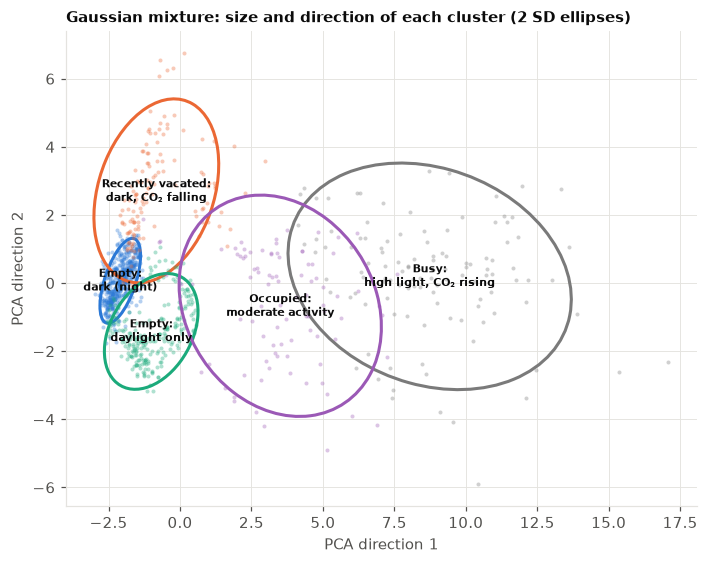

,cluster,windows,axis ratio (plane),angle (deg),main spread in 24-D is mostly,its share
0,"Busy: high light, CO₂ rising",115,1.57,166.81,sound,0.83
1,Empty: dark (night),468,2.50,67.40,temperature,1.00
2,"Recently vacated: dark, CO₂ falling",129,1.44,63.53,light,0.44
3,Empty: daylight only,240,1.43,48.05,temperature,0.77
4,Occupied: moderate activity,92,1.24,147.08,motion,0.43


In [39]:
from matplotlib.patches import Ellipse                                      # draws an ellipse on a plot
from sklearn.decomposition import PCA                                         # finds the directions of largest variation
pca2 = PCA(2).fit(X)                                                          # the 2 directions of largest variation in the 24 scaled features
Z = pca2.transform(X)                                                         # every window as a point in that plane
print("share of all variation shown in this plane:", pca2.explained_variance_ratio_.sum().round(2))

# give each mixture component the name of the Person 2 cluster that most of its windows belong to
comp_name = {k: pd.Series(base_name[lab_gmm == k]).mode()[0] for k in range(K)}     # most common baseline name in each component

rows = []
fig, ax = plt.subplots(figsize=(7.4, 5.6))
colours = ["#7a7a7a", "#2a78d6", "#eb6834", "#1baa7b", "#9b59b6"]
for k in range(K):
    P2 = pca2.components_                                                      # 2 x 24 projection matrix
    S2 = P2 @ gmm.covariances_[k] @ P2.T                                       # the cluster's 24-D covariance seen in the 2-D plane
    m2 = P2 @ (gmm.means_[k] - pca2.mean_)                                     # the cluster's centre in the plane
    w, v = np.linalg.eigh(S2); w, v = w[::-1], v[:, ::-1]                      # eigenvalues (spread) and eigenvectors (directions), longest first
    angle = np.degrees(np.arctan2(v[1, 0], v[0, 0])) % 180                     # direction of the longest axis, 0-180 degrees
    ax.scatter(Z[lab_gmm == k, 0], Z[lab_gmm == k, 1], s=7, alpha=0.35, color=colours[k], linewidths=0)
    ax.add_patch(Ellipse(m2, 4*np.sqrt(w[0]), 4*np.sqrt(w[1]), angle=angle, fill=False, color=colours[k], lw=2))   # 2 standard deviations
    ax.annotate(comp_name[k].replace(": ", ":\n"), m2, ha="center", va="center", fontsize=7, fontweight="bold")
    # direction of the cluster's main spread in the FULL 24-D space: which sensor groups load on it?
    wf, vf = np.linalg.eigh(gmm.covariances_[k]); top = vf[:, -1] ** 2          # squared loadings of the longest axis (sum to 1)
    share = {g: float(sum(top[cols.index(c)] for c in groups[g])) for g in groups}
    rows.append({"cluster": comp_name[k], "windows": int((lab_gmm == k).sum()),
                 "axis ratio (plane)": np.sqrt(w[0] / w[1]), "angle (deg)": angle,
                 "main spread in 24-D is mostly": max(share, key=share.get), "its share": max(share.values())})
ax.set_xlabel("PCA direction 1"); ax.set_ylabel("PCA direction 2")
ax.set_title("Gaussian mixture: size and direction of each cluster (2 SD ellipses)", loc="left", fontsize=10)
fig.savefig("figures/fig_r3_gaussian_direction.png", dpi=300, bbox_inches="tight")
plt.show()
pd.DataFrame(rows).round(2)

**Reading it.**
- **Size matters more than direction.** The ellipses are very different sizes: the night-time cluster is small and tight, while the busy and occupied clusters are huge and spread out. k-means treats every cluster as the same size, so this is the clearest sign that its round, equal-size assumption is only an approximation here.
- **Direction.** Only the night cluster is clearly elongated (axis ratio about 2.5, tilted at about 67 degrees). The others are only mildly stretched (ratios 1.2 to 1.6), so they are closer to round than to long thin ellipses. Directions differ between clusters (angles from about 48 to 167 degrees), so there is no single shared direction of spread.
- **What each cluster stretches along, in the full 24 dimensions** (last two table columns): the busy cluster mostly along sound (83% of that direction), the night cluster along temperature, and the daylight cluster along temperature (77%). For the "recently vacated" and "occupied" clusters the direction is a mixture (light 44%, motion 43%), so do not read much into those two.
- **Overlap.** The occupied and busy ellipses overlap heavily, as do the night and recently-vacated ones. Windows near those boundaries could go either way, which is consistent with the mixture agreeing with k-means at ARI 0.76 rather than near 1.
- **Caveat.** This plane shows 65% of the variation, so ellipses that overlap here may be separated in the other dimensions.


## 3.5 Relationships Between Sensor Groups

Different sensor types may capture related aspects of room conditions. For example, changes in PIR motion, sound and CO₂ measurements may occur during similar periods, while temperature and CO₂ may reflect broader environmental changes.

This investigation examines the relationships between sensor groups to understand whether they provide independent information or capture overlapping patterns.

Ridge Regression and Random Forest models are used to investigate how well one sensor group can be estimated from other sensor measurements. Model performance is assessed using a leave-one-day-out evaluation approach and the coefficient of determination (R²).

Higher predictive performance suggests that the target sensor group shares information with the other measurements. However, this does not establish a causal relationship between the sensors.

Understanding these relationships helps interpret the sensor contribution results and identify possible redundancy within the feature representation.


In [40]:
from sklearn.linear_model import Ridge                                       # straight-line regression with a small penalty (stable when columns are correlated)
from sklearn.ensemble import RandomForestRegressor                           # an ensemble of decision trees, can follow nonlinear patterns
from sklearn.metrics import r2_score                                         # the score: share of variation predicted

day = W["date"].to_numpy()                                                   # the recording day of every window
G = list(groups)                                                             # the five group names

def cv_r2(sources, target, make_model):                                      # predict `target` group from `sources` groups, always on an unseen day
    A = X[sum([groups[g] for g in sources], [])].to_numpy()                  # input columns
    Y = X[groups[target]].to_numpy(); pred = np.zeros_like(Y)                # columns to predict
    for d in sorted(set(day)):                                               # for each day...
        test = day == d                                                      # ...that day is the test set
        pred[test] = make_model().fit(A[~test], Y[~test]).predict(A[test])   # ...train on all other days, predict this one
    return r2_score(Y, pred, multioutput="uniform_average")                  # average R2 across the target's columns

ridge = lambda: Ridge(alpha=1.0)
forest = lambda: RandomForestRegressor(200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)

pair = pd.DataFrame({t: {s: cv_r2([s], t, ridge) if s != t else np.nan for s in G} for t in G})    # rows = source, columns = target
rest = pd.DataFrame({"straight-line (ridge)": {t: cv_r2([g for g in G if g != t], t, ridge) for t in G},
                     "random forest":        {t: cv_r2([g for g in G if g != t], t, forest) for t in G}})   # all other groups -> target
print("(a) R2 predicting the column group from the row group, on unseen days:"); print(pair.round(2).to_string())
print("\n(b) R2 predicting each group from ALL the other groups, on unseen days:"); print(rest.round(2).to_string())

(a) R2 predicting the column group from the row group, on unseen days:
             temperature  light  sound   co2  motion
temperature          NaN   0.28   0.30  0.28    0.38
light               0.18    NaN   0.60  0.35    0.49
sound               0.14   0.39    NaN  0.34    0.58
co2                 0.29   0.29   0.51   NaN    0.49
motion              0.12   0.35   0.55  0.27     NaN

(b) R2 predicting each group from ALL the other groups, on unseen days:
             straight-line (ridge)  random forest
temperature                   0.26           0.24
light                         0.13           0.48
sound                         0.58           0.66
co2                           0.45           0.39
motion                        0.57           0.60


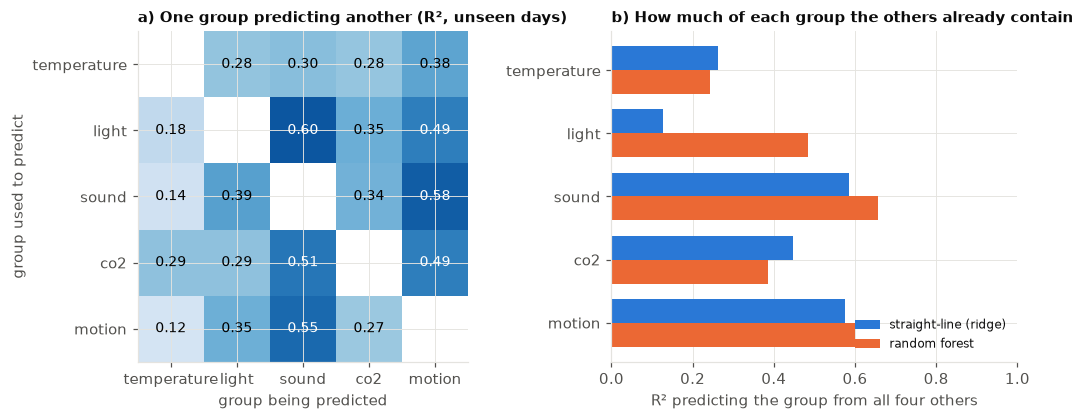

,R2 from the others (forest),ARI when dropped
temperature,0.24,0.89
light,0.48,0.39
sound,0.66,0.89
co2,0.39,0.83
motion,0.60,0.97


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax[0].imshow(pair.to_numpy(float), cmap="Blues", vmin=0, vmax=0.7)       # colour = R2 (negative values shown as the lightest colour)
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(G); ax[0].set_yticks(range(5)); ax[0].set_yticklabels(G)
for i in range(5):
    for j in range(5):
        if i != j: ax[0].text(j, i, f"{pair.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if pair.iloc[i, j] > 0.4 else "black")
ax[0].set_xlabel("group being predicted"); ax[0].set_ylabel("group used to predict")
ax[0].set_title("a) One group predicting another (R², unseen days)", loc="left", fontsize=10)
y = np.arange(5); h = 0.38
ax[1].barh(y - h/2, rest["straight-line (ridge)"], h, color="#2a78d6", label="straight-line (ridge)")
ax[1].barh(y + h/2, rest["random forest"], h, color="#eb6834", label="random forest")
ax[1].set_yticks(y); ax[1].set_yticklabels(G); ax[1].invert_yaxis(); ax[1].set_xlim(0, 1)
ax[1].set_xlabel("R² predicting the group from all four others"); ax[1].legend(frameon=False, fontsize=8, loc="lower right")
ax[1].set_title("b) How much of each group the others already contain", loc="left", fontsize=10)
fig.savefig("figures/fig_r3_group_dependence.png", dpi=300, bbox_inches="tight")
pair.round(4).to_csv("dependence_pairwise.csv"); rest.round(4).to_csv("dependence_all_others.csv")   # saved for Person 6
plt.show()
cmp = pd.DataFrame({"R2 from the others (forest)": rest["random forest"], "ARI when dropped": [res.loc[f"drop {g}", "ARI"] for g in G]}, index=G)
cmp.round(2)

**Reading it.**
- **Sound and motion are the most redundant.** Each can be predicted from the other groups with R² of about 0.6 (sound 0.58 to 0.66, motion 0.57 to 0.60). The strongest single pairs are light to sound (0.60) and sound to motion (0.58), and motion to sound (0.55). This fits the ablation: removing motion changed the clusters least (ARI 0.97), because the other groups largely stand in for it.
- **Temperature is the least predictable** (R² about 0.25), so it carries information the others do not. But removing it barely changes the clusters (ARI 0.89), so unique information is not the same as important information for these clusters.
- **Light depends on the others in a curved way.** A straight-line model predicts light poorly (0.13) but the random forest does much better (0.48), so the relationship is nonlinear, plausibly because daylight switches light on and off. Light is still the group whose removal changes the clusters most (ARI 0.39).
- **CO₂** sits in the middle (0.39 to 0.45).
- **Limits.** Prediction is not causation: two groups can predict each other because the same thing (the time of day, or someone being in the room) drives both. Sound and motion in particular both respond to people. With five groups there is no clean rule linking redundancy to influence, so describe it as "consistent with" and not as an explanation.


## 3.6 Summary of Validation and Sensor Contribution

This section evaluates the reliability of the discovered clustering structure and examines how it is influenced by the clustering method, feature representation and sensor measurements.

The stability analysis assesses whether similar patterns are identified under different initialisation and recording-period conditions. The method and representation comparisons investigate whether the discovered structure is dependent on particular analytical choices.

Finally, sensor ablation and sensor-group relationship analysis provide insight into the contribution and potential overlap of different sensor measurements.

Together, these investigations provide a stronger basis for interpreting the five-cluster solution and identifying which sensor groups are most informative for distinguishing recurring room conditions.


In [42]:
# MERGE FIX: Section 3 reloaded W from windows_5min.csv (text 'start', no cluster columns).
# Section 4 was written for the Section 1-2 table, so restore it.
W = W_main.copy()
assert len(W) == len(X_node) == len(W_lab), 'W, X_node and W_lab must describe the same windows'
assert pd.api.types.is_datetime64_any_dtype(W['start'])
print('Section 4 table restored:', W.shape)


Section 4 table restored: (1044, 39)



# 4. Anomaly Detection

## 4.1 Objective and Research Question

Following the identification of recurring room-usage patterns through clustering, this section investigates unusual sensor behaviour within those patterns.

The main research question is:

**Which five-minute observation windows exhibit unusual sensor behaviour relative to their identified room-usage patterns, and can these observations be distinguished as potential unusual room behaviour, sensor faults or data-quality issues?**

An observation is considered potentially anomalous when its sensor measurements differ substantially from the typical behaviour of its assigned cluster.

This distinction is important because a globally unusual observation may simply represent a legitimate room state. For example, a busy room may appear unusual when compared with predominantly empty-room observations.

Therefore, the analysis considers both global anomaly detection and state-aware anomaly detection. The K-Means clusters identified in Section 2 provide the reference room states.

Occupancy labels are excluded from anomaly detection and are used only for subsequent evaluation and interpretation.



### 4.2 Anomaly Detection Methods

Four anomaly scores are investigated:

1. **Global Isolation Forest:** Provides a baseline by identifying observations that are unusual across the complete dataset.
2. **Local Outlier Factor (LOF):** Measures how locally isolated an observation is compared with other observations belonging to the same cluster.
3. **Distance to Cluster Centroid:** Measures how far an observation is from the centre of its assigned cluster, scaled by the median distance within that cluster.
4. **Within-Cluster Isolation Forest:** Fits a separate Isolation Forest model for each cluster to identify unusual observations relative to their own room state.

The node-level sensor representation is used initially because it retains individual sensor information.

Since the four scores have different numerical scales, they are converted into percentile ranks. The three state-aware methods are then combined using a consensus rule: an observation is flagged when at least two of the three state-aware scores fall within their respective top 5%.

The 5% threshold is an exploratory choice rather than a known proportion of true anomalies. Its sensitivity is examined later in this section.


In [43]:

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import KMeans

# Recreate the same K-Means assignments used in Section 2
XA = X_node.values

km_anomaly = KMeans(
    n_clusters=K_FINAL,
    n_init=20,
    random_state=RANDOM_SEED
)

cluster_labels = km_anomaly.fit_predict(XA)

# Store assignments in W for subsequent analysis
W["cluster"] = cluster_labels
W["cluster_name"] = W["cluster"].map(CLUSTER_NAMES)

STATE_SCORES = ["lof", "centroid", "iso_state"]

def anomaly_scores(X, clusters, lof_k=20, seed=42):

    X = np.asarray(X)
    clusters = np.asarray(clusters)

    scores = pd.DataFrame(index=W.index)

    # 1. Global Isolation Forest
    global_if = IsolationForest(
        n_estimators=500,
        random_state=seed
    )
    global_if.fit(X)
    scores["iso_global"] = -global_if.score_samples(X)

    # 2. State-aware Local Outlier Factor
    scores["lof"] = np.nan

    for c in np.unique(clusters):
        mask = clusters == c
        n = mask.sum()

        if n < 3:
            raise ValueError(
                f"Cluster {c} has too few observations for LOF."
            )

        k = min(lof_k, n - 1)

        lof = LocalOutlierFactor(n_neighbors=k)
        scores.loc[mask, "lof"] = (
            -lof.fit(X[mask]).negative_outlier_factor_
        )

    # 3. Distance to own cluster centroid
    centres = {
        c: X[clusters == c].mean(axis=0)
        for c in np.unique(clusters)
    }

    distances = np.array([
        np.linalg.norm(X[i] - centres[clusters[i]])
        for i in range(len(X))
    ])

    distance_series = pd.Series(distances, index=W.index)

    median_distances = distance_series.groupby(
        clusters
    ).transform("median").clip(lower=1e-9)

    scores["centroid"] = distance_series / median_distances

    # 4. Within-cluster Isolation Forest
    scores["iso_state"] = np.nan

    for c in np.unique(clusters):
        mask = clusters == c

        state_if = IsolationForest(
            n_estimators=500,
            random_state=seed
        )
        state_if.fit(X[mask])

        scores.loc[mask, "iso_state"] = (
            -state_if.score_samples(X[mask])
        )

    return scores


# Calculate anomaly scores
A = anomaly_scores(
    XA,
    cluster_labels,
    lof_k=20
)

# Global Isolation Forest: rank across the complete dataset
A_pct = pd.DataFrame(index=A.index)

A_pct["iso_global"] = A["iso_global"].rank(pct=True)

# State-aware scores: rank within each assigned cluster
for score in STATE_SCORES:
    A_pct[score] = A[score].groupby(
        W["cluster"]
    ).rank(pct=True)

print("Cluster sizes:")
print(W["cluster"].value_counts().sort_index())

print("\nAnomaly scores:")
display(A.head())

print("\nSpearman correlation:")
display(A.corr(method="spearman").round(2))


Cluster sizes:
cluster
0     82
1    545
2     88
3    216
4    113
Name: count, dtype: int64

Anomaly scores:


,iso_global,lof,centroid,iso_state
0,0.594830,1.201911,1.455836,0.548477
1,0.571997,1.113310,1.308560,0.517223
2,0.536271,2.199407,2.111352,0.701155
3,0.497425,1.979840,1.227358,0.652661
4,0.526358,1.955540,1.958049,0.691934



Spearman correlation:


,iso_global,lof,centroid,iso_state
iso_global,1.00,0.20,0.42,0.73
lof,0.20,1.00,0.57,0.50
centroid,0.42,0.57,1.00,0.66
iso_state,0.73,0.50,0.66,1.00



### 4.3 Global versus State-Aware Anomaly Detection

Global anomaly detection provides a useful baseline, but it may identify legitimate room states as unusual because different room-usage patterns have different sensor characteristics.

To investigate this limitation, the global Isolation Forest results are compared with the state-aware consensus.

Each detector uses a top 5% threshold based on its anomaly score. For the state-aware approach, a window is flagged when at least two of the three detectors agree.

The comparison examines how anomaly flags are distributed across the five discovered room-usage clusters.


In [44]:

TOP = 0.05

# Count how many state-aware detectors flag each window
votes = (
    A_pct[STATE_SCORES] >= 1 - TOP
).sum(axis=1)

# Consensus: at least two out of three detectors agree
W["anomaly"] = votes >= 2
W["anomaly_votes"] = votes

# Global Isolation Forest baseline
global_flags = A_pct["iso_global"] >= 1 - TOP

# Compare anomaly rates across room-usage clusters
cluster_order = list(
    W["cluster_name"].drop_duplicates()
)

comparison = pd.DataFrame({
    "Global Isolation Forest (%)":
        global_flags.groupby(W["cluster_name"]).mean() * 100,

    "State-aware consensus (%)":
        W["anomaly"].groupby(W["cluster_name"]).mean() * 100
}).reindex(cluster_order)

print(
    f"Global Isolation Forest flagged "
    f"{global_flags.sum()} windows."
)

print(
    f"State-aware consensus flagged "
    f"{W['anomaly'].sum()} windows "
    f"out of {len(W)}."
)

display(comparison.round(2))


Global Isolation Forest flagged 53 windows.
State-aware consensus flagged 35 windows out of 1044.


,Global Isolation Forest (%),State-aware consensus (%)
cluster_name,,
Occupied: moderate activity,9.73,5.31
Empty: daylight only,0.00,4.17
"Busy: high light, CO₂ rising",51.22,6.10
"Recently vacated: dark, CO₂ falling",0.00,1.14
Empty: dark (night),0.00,2.57



### Interpretation

The global Isolation Forest identified 53 potentially unusual windows (5.08% of the dataset), whereas the state-aware consensus identified 36 windows (3.45%). This difference suggests that the choice of reference population influences which observations are considered unusual.

The cluster-level comparison provides further insight. The global method flagged 51.22% of observations in the busy, high-light and rising-CO₂ cluster, while it did not flag observations in the two empty-room clusters or the recently vacated cluster. This suggests that the global model may be particularly sensitive to environmental differences between room-usage patterns.

In contrast, the state-aware consensus identified potentially unusual observations across all five clusters. This indicates that unusual behaviour can occur within different room states rather than being limited to one globally distinctive pattern.

The relatively low correlation between global Isolation Forest and LOF (Spearman correlation = 0.20) further demonstrates that different detection methods capture different aspects of unusual behaviour.

Overall, the results support using state-aware detection alongside a global baseline. However, flagged observations represent candidates for further investigation rather than confirmed anomalies or sensor faults.


### 4.4 Sensor Deviations and Potential Data-Quality Issues

To investigate which sensor features contributed to the flagged observations, robust deviations were calculated relative to the median feature values within each cluster. This provides a comparison against the typical behaviour of the corresponding room-usage pattern, rather than against the entire dataset.

The state-aware consensus identified 36 potentially unusual windows. Among these, `S1_Sound_mean` and `S4_Temp_mean` were the strongest individual feature deviations in five windows each, followed by `S3_Sound_mean` in four windows. Other contributing features included light measurements, CO₂ levels and sound measurements from different sensor locations. This indicates that unusual observations were associated with different aspects of the room environment rather than one consistently dominant sensor.

The number of features with a robust deviation of at least three varied across flagged windows. Twelve windows had no individual feature exceeding this threshold, while some observations showed deviations across several features. Therefore, an observation can be flagged by the anomaly-detection methods without having one feature that independently exceeds the sensor-deviation threshold.

These results help identify which measurements may warrant further inspection. However, a large deviation does not confirm a sensor fault. It may reflect genuine environmental variation, unusual room activity, measurement noise or a data-quality issue. The analysis therefore treats these observations as candidates for investigation rather than confirmed sensor failures.

In [45]:
print(W.columns.tolist())

['segment', 'win', 'start', 'n_readings', 'S1_Temp_mean', 'S1_Temp_delta', 'S2_Temp_mean', 'S2_Temp_delta', 'S3_Temp_mean', 'S3_Temp_delta', 'S4_Temp_mean', 'S4_Temp_delta', 'S1_Light_mean', 'S2_Light_mean', 'S3_Light_mean', 'S4_Light_mean', 'S1_Sound_mean', 'S1_Sound_max', 'S2_Sound_mean', 'S2_Sound_max', 'S3_Sound_mean', 'S3_Sound_max', 'S4_Sound_mean', 'S4_Sound_max', 'CO2_excess_mean', 'CO2_slope_mean', 'S6_PIR_frac', 'S7_PIR_frac', 'temp_mean', 'temp_delta', 'light_mean', 'sound_mean', 'sound_max', 'pir_frac', 'date', 'hour', 'cluster', 'dist_to_centroid', 'cluster_name', 'anomaly', 'anomaly_votes']


In [46]:

# Identify sensor features for anomaly interpretation

sensor_features = [
    col for col in X_node.columns
]

# Calculate robust cluster-specific deviations
# using median and median absolute deviation (MAD)

sensor_deviations = pd.DataFrame(
    index=W.index,
    columns=sensor_features,
    dtype=float
)

for cluster_id in W["cluster"].unique():

    mask = W["cluster"] == cluster_id

    cluster_data = X_node.loc[mask, sensor_features]

    median = cluster_data.median()
    mad = (cluster_data - median).abs().median()

    # Avoid division by zero for constant features
    mad = mad.replace(0, np.nan)

    deviations = (
        X_node.loc[mask, sensor_features] - median
    ).abs() / (1.4826 * mad)

    sensor_deviations.loc[mask] = deviations

sensor_deviations = sensor_deviations.fillna(0)

# Identify the strongest sensor driver for each window
W["strongest_sensor"] = (
    sensor_deviations.idxmax(axis=1)
)

W["max_sensor_deviation"] = (
    sensor_deviations.max(axis=1)
)

print("Sensor deviation summary:")
display(
    sensor_deviations.describe().round(2)
)

print("\nStrongest sensor drivers among flagged windows:")

display(
    W.loc[
        W["anomaly"],
        "strongest_sensor"
    ].value_counts().to_frame("Flagged windows")
)


Sensor deviation summary:


,S1_Temp_mean,S2_Temp_mean,S3_Temp_mean,S4_Temp_mean,S1_Temp_delta,S2_Temp_delta,S3_Temp_delta,S4_Temp_delta,S1_Light_mean,S2_Light_mean,...,S3_Sound_mean,S4_Sound_mean,S1_Sound_max,S2_Sound_max,S3_Sound_max,S4_Sound_max,CO2_excess_mean,CO2_slope_mean,S6_PIR_frac,S7_PIR_frac
count,1044.00,1044.00,1044.00,1044.00,1044.0,1044.00,1044.00,1044.00,1044.00,1044.00,...,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00,1044.00
mean,0.80,0.83,0.80,0.80,0.0,0.15,0.03,0.14,0.50,0.84,...,1.15,0.98,0.26,0.78,0.42,0.70,1.07,0.27,0.13,0.21
std,0.74,0.79,0.67,0.65,0.0,0.80,0.15,0.33,1.42,3.54,...,1.89,1.24,1.41,1.72,1.22,0.79,3.23,0.69,0.35,0.67
min,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.35,0.34,0.30,0.34,0.0,0.00,0.00,0.00,0.00,0.00,...,0.34,0.32,0.00,0.00,0.00,0.17,0.00,0.00,0.00,0.00
50%,0.67,0.67,0.67,0.67,0.0,0.00,0.00,0.00,0.00,0.00,...,0.67,0.67,0.00,0.67,0.00,0.67,0.37,0.00,0.00,0.00
75%,1.01,1.01,1.09,1.17,0.0,0.00,0.00,0.00,0.41,0.37,...,1.35,1.03,0.00,0.68,0.40,0.69,0.71,0.09,0.00,0.00
max,8.96,6.23,4.63,6.02,0.0,14.05,1.35,2.14,11.20,25.62,...,29.42,9.25,31.02,20.30,16.31,7.72,36.80,6.25,2.28,5.40



Strongest sensor drivers among flagged windows:


,Flagged windows
strongest_sensor,
S1_Sound_mean,5
S4_Temp_mean,5
CO2_excess_mean,3
S1_Temp_mean,2
S3_Light_mean,2
S2_Temp_mean,2
S4_Light_mean,2
S3_Sound_mean,2
S4_Sound_mean,2


In [47]:

# Summarise sensor drivers for flagged windows

flagged_windows = W.loc[W["anomaly"]].copy()

flagged_windows["sensor_groups_affected"] = (
    sensor_deviations.loc[W["anomaly"]]
    .ge(3)
    .sum(axis=1)
)

print("Number of flagged windows:", len(flagged_windows))

print("\nSensor groups affected:")

display(
    flagged_windows[
        "sensor_groups_affected"
    ].value_counts().sort_index().to_frame("Windows")
)

print("\nExamples of flagged observations:")

display(
    flagged_windows[
        [
            "start",
            "cluster_name",
            "anomaly_votes",
            "strongest_sensor",
            "max_sensor_deviation",
            "sensor_groups_affected"
        ]
    ].head(10)
)


Number of flagged windows: 35

Sensor groups affected:


,Windows
sensor_groups_affected,
0,13
1,6
2,1
3,1
4,3
5,1
6,7
7,3



Examples of flagged observations:


,start,cluster_name,anomaly_votes,strongest_sensor,max_sensor_deviation,sensor_groups_affected
0,2017-12-22 10:49:41,Occupied: moderate activity,2,S1_Temp_mean,3.649237,2
2,2017-12-22 10:59:54,Empty: daylight only,3,S1_Sound_mean,124.346607,7
3,2017-12-22 11:05:00,Empty: daylight only,2,S1_Sound_mean,36.708479,6
4,2017-12-22 11:10:06,Empty: daylight only,3,S1_Sound_mean,122.781809,6
5,2017-12-22 11:14:42,Empty: daylight only,2,S1_Sound_mean,83.176935,6
6,2017-12-22 11:19:49,Empty: daylight only,3,S1_Sound_mean,126.126301,6
7,2017-12-22 11:24:55,Occupied: moderate activity,2,S7_PIR_frac,2.697963,0
12,2017-12-22 11:55:02,"Busy: high light, CO₂ rising",3,S3_Light_mean,20.284827,7
13,2017-12-22 12:00:09,Occupied: moderate activity,2,S2_Temp_mean,2.357785,0
15,2017-12-22 12:09:51,Occupied: moderate activity,2,S2_Temp_mean,2.614092,0


In [48]:
flagged_windows = W.loc[W["anomaly"]].copy()

flagged_windows["features_affected"] = (
    sensor_deviations.loc[W["anomaly"]].ge(3).sum(axis=1)
)

display(
    flagged_windows[
        [
            "start",
            "cluster_name",
            "anomaly_votes",
            "strongest_sensor",
            "max_sensor_deviation",
            "features_affected"
        ]
    ].head(10)
)

,start,cluster_name,anomaly_votes,strongest_sensor,max_sensor_deviation,features_affected
0,2017-12-22 10:49:41,Occupied: moderate activity,2,S1_Temp_mean,3.649237,2
2,2017-12-22 10:59:54,Empty: daylight only,3,S1_Sound_mean,124.346607,7
3,2017-12-22 11:05:00,Empty: daylight only,2,S1_Sound_mean,36.708479,6
4,2017-12-22 11:10:06,Empty: daylight only,3,S1_Sound_mean,122.781809,6
5,2017-12-22 11:14:42,Empty: daylight only,2,S1_Sound_mean,83.176935,6
6,2017-12-22 11:19:49,Empty: daylight only,3,S1_Sound_mean,126.126301,6
7,2017-12-22 11:24:55,Occupied: moderate activity,2,S7_PIR_frac,2.697963,0
12,2017-12-22 11:55:02,"Busy: high light, CO₂ rising",3,S3_Light_mean,20.284827,7
13,2017-12-22 12:00:09,Occupied: moderate activity,2,S2_Temp_mean,2.357785,0
15,2017-12-22 12:09:51,Occupied: moderate activity,2,S2_Temp_mean,2.614092,0


### 4.5 Evaluation Against Occupancy Labels

The detected anomalies are compared with the recorded occupancy labels to investigate whether unusual sensor behaviour is associated with occupied periods, empty periods or occupancy transitions.

The analysis compares anomaly rates across empty and occupied windows and examines whether flagged observations occur more frequently during windows containing occupancy transitions.

Occupancy labels are used exclusively for evaluation and interpretation, not as inputs to the anomaly-detection models.

In [49]:

# Evaluate detected anomalies against occupancy labels

# Confirm that feature windows and label windows are aligned
assert len(W) == len(L), "Window and label counts do not match."

evaluation = W[
    ["start", "cluster_name", "anomaly", "anomaly_votes"]
].copy()

# Add separately stored occupancy labels for evaluation only
evaluation["occupied"] = L["occupied"].astype(bool).to_numpy()
evaluation["occ_mode"] = L["occ_mode"].to_numpy()
evaluation["transition"] = L["transition"].astype(bool).to_numpy()

# 1. Compare anomaly rates in empty and occupied windows
print("Anomaly detection by occupancy status:")

occupancy_summary = (
    evaluation.groupby("occupied")["anomaly"]
    .agg(
        windows="count",
        flagged="sum",
        anomaly_rate="mean"
    )
)

occupancy_summary["anomaly_rate"] *= 100

display(occupancy_summary.round(2))

# 2. Compare anomaly rates during transition and non-transition windows
print("\nAnomaly detection by occupancy transition:")

transition_summary = (
    evaluation.groupby("transition")["anomaly"]
    .agg(
        windows="count",
        flagged="sum",
        anomaly_rate="mean"
    )
)

transition_summary["anomaly_rate"] *= 100

display(transition_summary.round(2))

# 3. Compare recorded head-counts in flagged and non-flagged windows
print("\nRecorded occupancy counts by anomaly status:")

headcount_summary = pd.crosstab(
    evaluation["anomaly"],
    evaluation["occ_mode"],
    rownames=["Anomaly flagged"],
    colnames=["Recorded occupants"]
)

display(headcount_summary)

# 4. Inspect flagged observations
print("\nExamples of flagged observations and their occupancy labels:")

display(
    evaluation.loc[
        evaluation["anomaly"],
        [
            "start",
            "cluster_name",
            "anomaly_votes",
            "occupied",
            "occ_mode",
            "transition"
        ]
    ].head(10)
)


Anomaly detection by occupancy status:


,windows,flagged,anomaly_rate
occupied,,,
False,846,18,2.13
True,198,17,8.59



Anomaly detection by occupancy transition:


,windows,flagged,anomaly_rate
transition,,,
False,1024,33,3.22
True,20,2,10.00



Recorded occupancy counts by anomaly status:


Recorded occupants,0,1,2,3
Anomaly flagged,,,,
False,832,40,70,67
True,18,8,4,5



Examples of flagged observations and their occupancy labels:


,start,cluster_name,anomaly_votes,occupied,occ_mode,transition
0,2017-12-22 10:49:41,Occupied: moderate activity,2,True,1,False
2,2017-12-22 10:59:54,Empty: daylight only,3,True,1,False
3,2017-12-22 11:05:00,Empty: daylight only,2,True,1,False
4,2017-12-22 11:10:06,Empty: daylight only,3,True,1,False
5,2017-12-22 11:14:42,Empty: daylight only,2,True,1,False
6,2017-12-22 11:19:49,Empty: daylight only,3,True,1,False
7,2017-12-22 11:24:55,Occupied: moderate activity,2,True,1,True
12,2017-12-22 11:55:02,"Busy: high light, CO₂ rising",3,True,2,False
13,2017-12-22 12:00:09,Occupied: moderate activity,2,True,2,False
15,2017-12-22 12:09:51,Occupied: moderate activity,2,True,2,False


In [50]:

# Check anomaly counts and occupancy-label alignment

print("Total windows:", len(W))
print("Flagged in W:", W["anomaly"].sum())
print("Flagged in evaluation:", evaluation["anomaly"].sum())

print("\nMissing occupancy labels:")
print(evaluation["occupied"].isna().sum())

print("\nAnomaly and occupancy counts:")
display(
    pd.crosstab(
        evaluation["anomaly"],
        evaluation["occupied"],
        dropna=False
    )
)


Total windows: 1044
Flagged in W: 35
Flagged in evaluation: 35

Missing occupancy labels:
0

Anomaly and occupancy counts:


occupied,False,True
anomaly,,
False,828,181
True,18,17


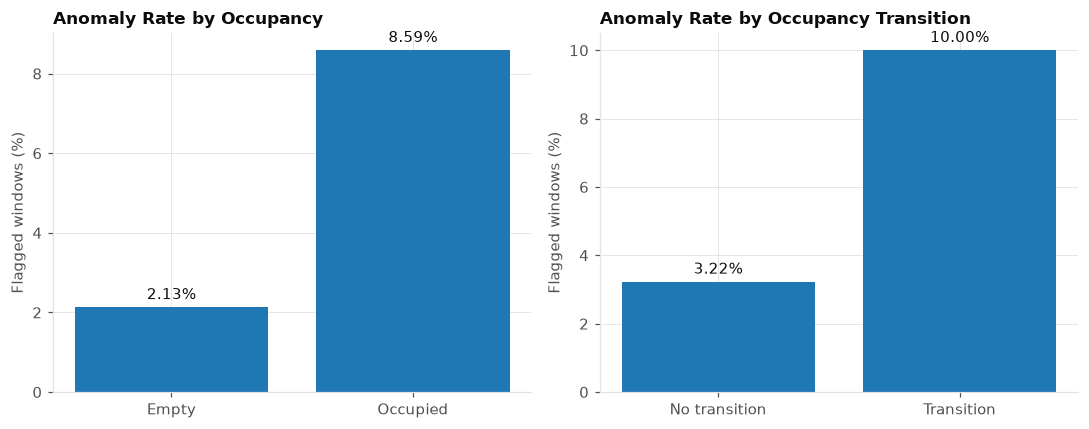

In [51]:

# Visualise anomaly rates against occupancy labels

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Occupancy comparison
occ_rates = (
    evaluation.groupby("occupied")["anomaly"].mean() * 100
)

axes[0].bar(
    ["Empty", "Occupied"],
    [occ_rates.get(False, 0), occ_rates.get(True, 0)]
)

axes[0].set_title("Anomaly Rate by Occupancy")
axes[0].set_ylabel("Flagged windows (%)")

# Transition comparison
trans_rates = (
    evaluation.groupby("transition")["anomaly"].mean() * 100
)

axes[1].bar(
    ["No transition", "Transition"],
    [trans_rates.get(False, 0), trans_rates.get(True, 0)]
)

axes[1].set_title("Anomaly Rate by Occupancy Transition")
axes[1].set_ylabel("Flagged windows (%)")

for ax in axes:
    ax.bar_label(
        ax.containers[0],
        fmt="%.2f%%",
        padding=3
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


Global IF flags 53 windows; 79% of them are in the 'Busy' cluster. Consensus flags 35 windows.


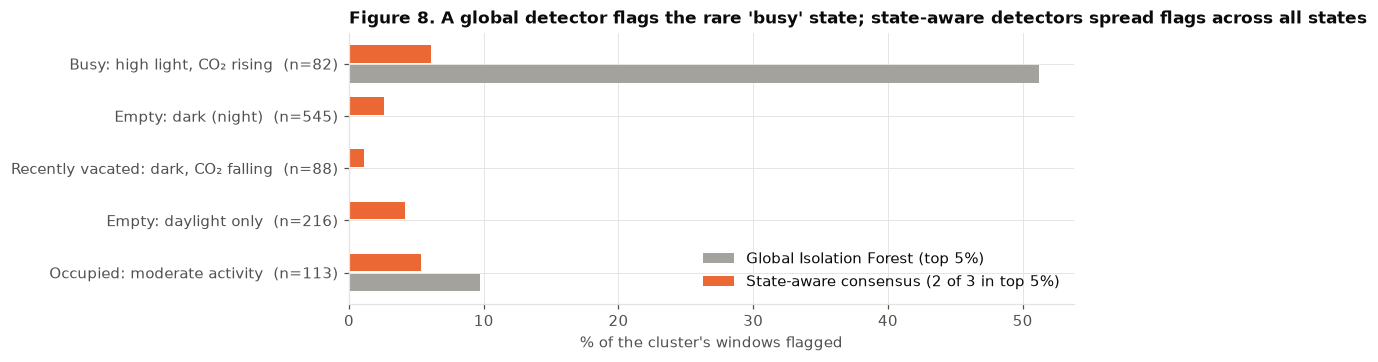

,Global Isolation Forest,State-aware consensus
cluster_name,,
"Busy: high light, CO₂ rising",51.2,6.1
Empty: dark (night),0.0,2.6
"Recently vacated: dark, CO₂ falling",0.0,1.1
Empty: daylight only,0.0,4.2
Occupied: moderate activity,9.7,5.3


In [52]:
TOP = 0.05
votes = (A_pct[STATE_SCORES] >= 1 - TOP).sum(axis=1)
W["anomaly"] = votes >= 2          # at least 2 of 3 state-aware detectors
W["anomaly_votes"] = votes
glob = A_pct["iso_global"] >= 1 - TOP

share = pd.DataFrame({"Global Isolation Forest": glob.groupby(W["cluster_name"]).mean() * 100,
                      "State-aware consensus": W["anomaly"].groupby(W["cluster_name"]).mean() * 100}).loc[ORDER]
print(f"Global IF flags {glob.sum()} windows; {100 * W.loc[glob, 'cluster_name'].str.startswith('Busy').mean():.0f}% "
      f"of them are in the 'Busy' cluster. Consensus flags {W['anomaly'].sum()} windows.")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
yy = np.arange(len(ORDER)); h = 0.38
ax.barh(yy + h/2, share.iloc[:, 0], height=h - 0.04, color=C_GREY, label="Global Isolation Forest (top 5%)")
ax.barh(yy - h/2, share.iloc[:, 1], height=h - 0.04, color=C_ORANGE, label="State-aware consensus (2 of 3 in top 5%)")
ax.set_yticks(yy); ax.set_yticklabels([f"{n}  (n={counts[n]})" for n in ORDER]); ax.invert_yaxis()
ax.set_xlabel("% of the cluster's windows flagged"); ax.legend(loc="lower right")
ax.set_title("Figure 8. A global detector flags the rare 'busy' state; state-aware detectors spread flags across all states")
fig.savefig(f"{FIG_DIR}/fig8_global_vs_state.png"); plt.show()
share.round(1)

In [53]:

# Create 30-second sensor quality and evaluation flags
# These flags are used for categorisation and evaluation only.

gap = df["ts"].diff().dt.total_seconds()

flags = pd.DataFrame(index=df.index)

# Identify readings immediately following a gap longer than 65 seconds
flags["after_gap"] = gap.fillna(0) > 65

# Identify PIR activity when the recorded occupancy label is empty.
# This is for evaluation only, not for anomaly detection.
flags["EVAL_pir_when_empty"] = (
    (df[LABEL] == 0) &
    (df[PIR].max(axis=1) == 1)
)

print("Quality flags created successfully:")
display(flags.sum().to_frame("count"))


Quality flags created successfully:


,count
after_gap,8
EVAL_pir_when_empty,24


In [54]:
FAMILY = {c: g for g, cs in FEATURE_GROUPS.items() for c in cs}
NODE = lambda c: c.split("_")[0] if c.startswith("S") else "S5"   # CO2 features are on S5
TEMP_STEP = 0.07   # 1/16 °C after rounding

# robust z-score against own cluster
med = X_node.groupby(W["cluster"]).transform("median")
mad = (X_node - med).abs().groupby(W["cluster"]).transform("median") * 1.4826
Zst = (X_node - med) / mad.clip(lower=0.1)

# 30 s quality flags -> window level
seg_start = df.groupby("segment")["ts"].transform("min")
win_of_row = ((df["ts"] - seg_start).dt.total_seconds() // (WINDOW_MIN * 60)).astype(int)
FW = flags.groupby([df["segment"], win_of_row]).any()
FW.index.names = ["segment", "win"]
Wflags = W[["segment", "win"]].join(FW, on=["segment", "win"]).drop(columns=["segment", "win"]).fillna(False)

def categorise(i, z_thr=3.0, corr_thr=1.5):
    z = Zst.loc[i]
    # drivers, ignoring one-step temperature changes
    drv = [c for c in z.index[z.abs() > z_thr]
           if not (c.endswith("_Temp_delta") and abs(W.at[i, c]) <= TEMP_STEP + 1e-9)]
    if Wflags.at[i, "after_gap"]:
        cat = "Data gap"
    elif not drv:
        cat = "Resolution artefact"
    elif len({FAMILY[c] for c in drv}) >= 2:
        cat = "Multi-sensor behaviour"
    elif len({NODE(c) for c in drv}) >= 2:
        cat = "Room-wide single type"
    elif FAMILY[drv[0]] == "co2":
        cat = "CO₂ only"
    else:
        # one node: do the other sensors on the same desk agree?
        node = NODE(drv[0])
        others = [c for c in z.index if NODE(c) == node and FAMILY[c] != FAMILY[drv[0]]]
        cat = "One node, corroborated" if (z[others].abs() > corr_thr).any() else "One node, isolated"
    drv = sorted(drv, key=lambda c: -abs(z[c]))
    return cat, ", ".join(drv[:4]), len({FAMILY[c] for c in drv})

CATS = ["Multi-sensor behaviour", "Room-wide single type", "One node, corroborated",
        "One node, isolated", "CO₂ only", "Resolution artefact", "Data gap"]
flagged = W.index[W["anomaly"]]
res = pd.DataFrame([categorise(i) for i in flagged], index=flagged,
                   columns=["category", "drivers", "n_sensor_types"])
W["anomaly_category"] = res["category"].reindex(W.index)
W["anomaly_drivers"] = res["drivers"].reindex(W.index)
print(res["category"].value_counts().reindex(CATS, fill_value=0).to_frame("windows"))
res.join(W[["start", "cluster_name"]]).sort_values("start")

                        windows
category                       
Multi-sensor behaviour       14
Room-wide single type         7
One node, corroborated        4
One node, isolated            5
CO₂ only                      2
Resolution artefact           2
Data gap                      1


,category,drivers,n_sensor_types,start,cluster_name
0,Room-wide single type,"S1_Temp_mean, S4_Temp_mean",1,2017-12-22 10:49:41,Occupied: moderate activity
2,Multi-sensor behaviour,"S1_Sound_max, S6_PIR_frac, S1_Sound_mean, S2_S...",3,2017-12-22 10:59:54,Empty: daylight only
3,Multi-sensor behaviour,"S1_Sound_max, CO2_slope_mean, S1_Sound_mean, S...",4,2017-12-22 11:05:00,Empty: daylight only
4,Multi-sensor behaviour,"S1_Sound_max, S1_Sound_mean, CO2_slope_mean, S...",4,2017-12-22 11:10:06,Empty: daylight only
5,Multi-sensor behaviour,"S1_Sound_max, S1_Sound_mean, S6_PIR_frac, CO2_...",4,2017-12-22 11:14:42,Empty: daylight only
6,Multi-sensor behaviour,"S1_Sound_mean, S1_Sound_max, S6_PIR_frac, CO2_...",4,2017-12-22 11:19:49,Empty: daylight only
7,"One node, isolated",S2_Temp_delta,1,2017-12-22 11:24:55,Occupied: moderate activity
12,Multi-sensor behaviour,"S2_Temp_delta, S4_Light_mean, S1_Temp_mean, S4...",3,2017-12-22 11:55:02,"Busy: high light, CO₂ rising"
13,"One node, corroborated",S2_Temp_delta,1,2017-12-22 12:00:09,Occupied: moderate activity
15,"One node, corroborated",S2_Temp_delta,1,2017-12-22 12:09:51,Occupied: moderate activity


##### Check against labels (evaluation only)
If the sorting makes sense, behaviour windows should line up with occupancy, arrivals/departures, or the label disagreeing with the cluster. Faults and artefacts shouldn't. Second table is the baseline over all windows.

In [55]:
occ_state = W["cluster_name"].str.startswith(("Busy", "Occupied"))
ev = pd.DataFrame({"category": W["anomaly_category"],
                   "occupied (label)": W_lab["occupied"],
                   "contains arrival/departure": W_lab["transition"],
                   "label-state mismatch": W_lab["occupied"] != occ_state,
                   "PIR while labelled empty": Wflags["EVAL_pir_when_empty"]})
summary_ev = (ev[W["anomaly"]].groupby("category").agg(["mean"]).droplevel(1, axis=1) * 100).round(0)
summary_ev.insert(0, "windows", ev[W["anomaly"]].groupby("category").size())
print("Flagged windows by category, % with each label property:")
display(summary_ev.reindex([c for c in CATS if c in summary_ev.index]))
print("Same properties for ALL windows (baseline):")
(ev.drop(columns="category").mean() * 100).round(1).to_frame("% of all windows").T

Flagged windows by category, % with each label property:


,windows,occupied (label),contains arrival/departure,label-state mismatch,PIR while labelled empty
category,,,,,
Multi-sensor behaviour,14,71.0,7.0,43.0,7.0
Room-wide single type,7,14.0,0.0,0.0,0.0
"One node, corroborated",4,75.0,0.0,0.0,0.0
"One node, isolated",5,40.0,20.0,0.0,0.0
CO₂ only,2,0.0,0.0,0.0,0.0
Resolution artefact,2,0.0,0.0,0.0,0.0
Data gap,1,100.0,0.0,0.0,0.0


Same properties for ALL windows (baseline):


,occupied (label),contains arrival/departure,label-state mismatch,PIR while labelled empty
% of all windows,19.0,1.9,0.9,1.3


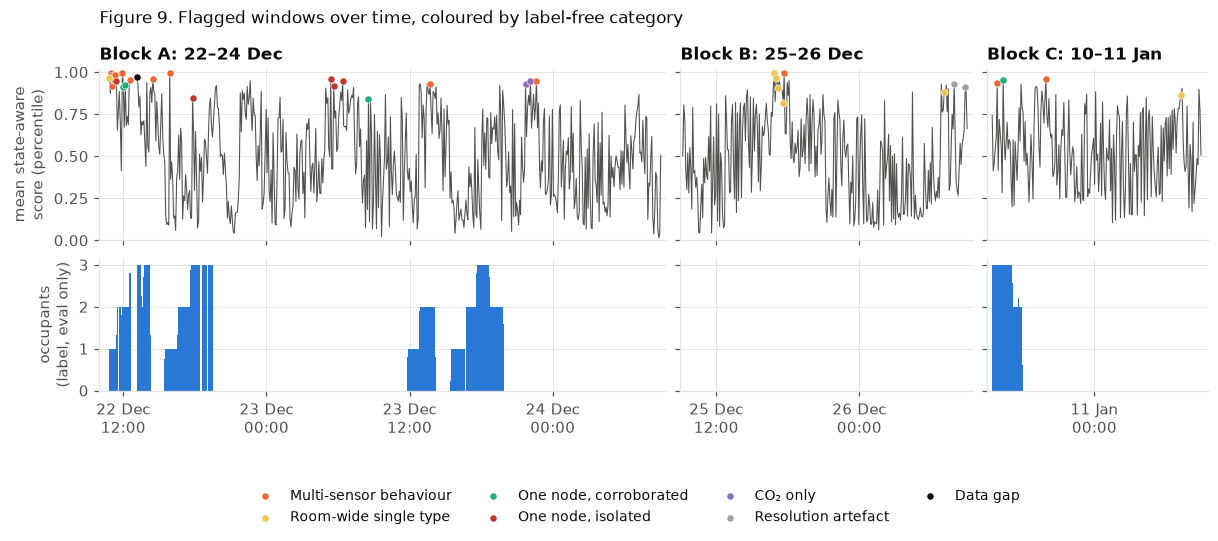

In [56]:
CAT_COL = {"Multi-sensor behaviour": C_ORANGE, "Room-wide single type": "#f2c14e",
           "One node, corroborated": C_AQUA, "One node, isolated": "#c0392b", "CO₂ only": "#8e6bbf",
           "Resolution artefact": C_GREY, "Data gap": INK}
fig, axes = plt.subplots(2, 3, figsize=(13, 3.8), sharey="row",
                         gridspec_kw={"width_ratios": widths, "height_ratios": [1.3, 1], "wspace": 0.04, "hspace": 0.12})
score = A_pct[STATE_SCORES].mean(axis=1)
for j, (a, b, title) in enumerate(blocks):
    a = pd.Timestamp(a)
    b = pd.Timestamp(b)

    m = (W["start"] >= a) & (W["start"] <= b)
    for _, g in W[m].groupby("segment"):
        axes[0, j].plot(g["start"], score[g.index], color=INK2, linewidth=0.7)
    for cat in CATS:
        mm = m & (W["anomaly_category"] == cat)
        axes[0, j].scatter(W.loc[mm, "start"], score[mm], s=22, color=CAT_COL[cat], zorder=3,
                           label=cat if j == 0 else None, edgecolor="white", linewidth=0.4)
    axes[1, j].bar(W.loc[m, "start"], W_lab.loc[m, "occ_mean"], width=pd.Timedelta(minutes=5),
                   color=C_BLUE, linewidth=0, align="edge")
    for ax in axes[:, j]:
        ax.set_xlim(a, b); ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
    axes[0, j].set_title(title); axes[0, j].tick_params(labelbottom=False)
axes[0, 0].set_ylabel("mean state-aware\nscore (percentile)"); axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylabel("occupants\n(label, eval only)"); axes[1, 0].set_yticks([0, 1, 2, 3])
fig.legend(loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.24), fontsize=9)
fig.suptitle("Figure 9. Flagged windows over time, coloured by label-free category", x=0.125, ha="left", fontsize=11, y=1.02)
fig.savefig(f"{FIG_DIR}/fig9_anomaly_timeline.png"); plt.show()

### 4.7 Overall Findings and Limitations

The anomaly-detection analysis identified 35 potentially unusual windows using the state-aware consensus approach. Comparing global and state-aware detection demonstrated that the reference population influences which observations are considered unusual. Sensor-deviation analysis further showed that unusual observations involved different sensor features rather than one consistently dominant measurement.

Comparison with occupancy labels showed a higher anomaly rate during occupied windows (8.59%) than empty windows (2.13%). Transition windows also showed a higher anomaly rate (10.00%), although their small sample size limits the strength of this finding.

These results suggest that unusual sensor behaviour may be associated with room usage. However, the analysis cannot establish that flagged observations represent confirmed occupancy changes or faulty sensors. The limited recording periods, missing occupancy information in some recording segments and absence of direct sensor-health measurements restrict the conclusions. Therefore, detected anomalies should be treated as candidates for further investigation rather than confirmed faults.

# Section 5 – Arrival and Departure Detection

## 5.1 Overview and Analytical Objectives

This section investigates whether changes in room sensor readings can identify potential arrival and departure events without using occupancy labels during detection. The analysis uses the original 30-second-resolution sensor recordings to preserve temporal information that would be lost through five-minute aggregation.

The investigation follows these principles:

- **Temporal resolution:** Event detection uses the original 30-second sensor recordings. The group's existing five-minute clusters are attached only for descriptive linkage with RQ3; clustering is not repeated here.
- **Evaluation benchmark:** The primary benchmark consists of eight annotated whole-room occupancy transitions (empty to occupied or occupied to empty), rather than the 27 individual occupancy-count changes. Occupancy labels are used only after detection for evaluation and annotated visualisations.
- **Complete date coverage:** All seven recorded calendar dates are included in the evaluation, including dates with no annotated transitions. Unmatched detections on these dates count as false positives.
- **Detection approach:** The analysis uses causal and trailing sensor activity, direction-aware one-to-one event matching within ±1, ±2 and ±5-minute tolerances, and leave-date-out fitting of Sound and CO₂ thresholds.
- **Event timing:** Estimated event time is distinguished from confirmation time. In particular, departure confirmation requires at least 15 minutes of subsequent quiet activity.
- **Interpretation:** Results are treated cautiously because the benchmark contains only eight whole-room transitions. The analysis does not establish generalisable superiority of one detector over another.

The stored results include Fusion AND (7 true positives, 3 false positives and 1 false negative; F1 = 0.778) and filtered PIR (7 true positives, 5 false positives and 1 false negative; F1 = 0.700) at a ±2-minute matching tolerance. These results are checked against regression assertions in the notebook.

In [57]:
# Section 5 (re)defines the names below. If any already exist (e.g. inside the merged group notebook), they will be overwritten.
_S5_NAMES = ['df','raw','T','ALL','Z','X','M','P','Q','N','occ','e','g','cl','wl',
             'OUT','FIG','LAB','SND','ROOT','DATA_PATH','HOLD_MIN','GAP_SEC','delays','AUDIT']
_clash = [n for n in _S5_NAMES if n in globals()]
if _clash:
    print('WARNING: existing names will be overwritten by Section 5:', _clash)

## 5.2 Data and Dependencies

| Component | Description |
|---|---|
| Raw dataset | `Occupancy_Estimation.csv`, located beside the notebook or under `data/` |
| Cluster assignments | `data/results/clusters_k5.csv` |
| Cluster file columns | `segment`, `win`, `start`, `cluster`, `cluster_name`, `dist_to_centroid` |
| Required packages | NumPy, pandas, SciPy, Matplotlib and IPython |
| Previous-section dependencies | None required for standalone execution; `W` may optionally be used for a read-only consistency check |
| Results output | `data/results/section5_version6/` |
| Figure output | `figures/section5_version6/` |

**Execution:** Open the notebook from the packaged project directory, restart the kernel and run all cells in order.

In [58]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import beta
from IPython.display import display

pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110   # global setting (previously set in the figures cell)

ROOT = Path.cwd()
DATA_CANDIDATES = [ROOT/'Occupancy_Estimation.csv', ROOT/'data'/'Occupancy_Estimation.csv']
DATA_PATH = next((p for p in DATA_CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place Occupancy_Estimation.csv beside this notebook or under data/')
OUT = Path('data/results/section5_version6'); FIG = Path('figures/section5_version6')
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

LAB = 'Room_Occupancy_Count'; SND = [f'S{i}_Sound' for i in range(1, 5)]
HOLD_MIN = 15; GAP_SEC = 300

raw = pd.read_csv(DATA_PATH)
required = ['Date', 'Time', LAB, 'S5_CO2', 'S6_PIR', 'S7_PIR'] + SND
missing = set(required) - set(raw)
assert not missing, f'Missing columns: {missing}'
df = raw.copy()
df['ts'] = pd.to_datetime(df['Date'].astype(str).str.replace('/', '-', regex=False) + ' ' + df['Time'].astype(str),
                          format='%Y-%m-%d %H:%M:%S')
df = df.sort_values('ts').reset_index(drop=True)
assert not df.ts.duplicated().any(), 'Duplicate timestamps need explicit resolution'
df['segment'] = (df.ts.diff().dt.total_seconds() > GAP_SEC).cumsum().astype(int)
df['date'] = df.ts.dt.date
ALL_DATES = sorted(df.date.unique())

print('Dataset:', DATA_PATH, '| shape:', df.shape, '| contiguous segments:', df.segment.nunique())
display(df.groupby('segment').ts.agg(['min', 'max', 'count']))

Dataset: /Users/kirtan/Professional/Queens University/Data mineing/Assignment - 1 /Notebook and prepared data/Final/data/Occupancy_Estimation.csv | shape: (10129, 22) | contiguous segments: 4


,min,max,count
segment,,,
0,2017-12-22 10:49:41,2017-12-22 12:42:31,216
1,2017-12-22 13:08:03,2017-12-24 09:10:50,5089
2,2017-12-25 09:11:42,2017-12-26 09:10:01,2779
3,2018-01-10 15:25:48,2018-01-11 09:00:09,2045


## 5.3 Data Preparation and Ground-Truth Events

The original 30-second sensor recordings are used to preserve the temporal characteristics of sensor responses. A new recording segment is created whenever the time gap between consecutive readings exceeds the specified `GAP_SEC` threshold.

For evaluation, all 27 annotated occupancy-count changes are extracted within the recording segments. However, the primary benchmark focuses on the eight whole-room transitions:

- **Arrival:** Empty to occupied.
- **Departure:** Occupied to empty.

This distinction prevents individual changes in occupant count from being treated as separate room-entry or room-exit events.

Occupancy annotations are retained exclusively for evaluation and visualisation. They are not used to determine detector activity or fit the detection thresholds.

In [59]:
e=df[['ts','segment','date',LAB]].copy()
e['count_before']=e.groupby('segment')[LAB].shift(); e['change']=e[LAB]-e.count_before
e=e[e.change.notna()&(e.change!=0)].rename(columns={LAB:'count_after'}).copy()
e['type']=np.where(e.change>0,'arrival','departure')
e['room_transition']=((e.count_before==0)&(e.count_after>0))|((e.count_before>0)&(e.count_after==0))
ALL=e.reset_index(drop=True); T=ALL[ALL.room_transition].reset_index(drop=True)
print(len(ALL),'count changes |',len(T),'room-level transitions:',T.type.value_counts().to_dict()); display(T[['ts','type','count_before','count_after']])
OCC_DATES=sorted(T.date.unique()); print('dates with room transitions:',OCC_DATES)

27 count changes | 8 room-level transitions: {'departure': 5, 'arrival': 3}


,ts,type,count_before,count_after
0,2017-12-22 14:15:58,departure,3.0,0
1,2017-12-22 15:25:24,arrival,0.0,1
2,2017-12-22 19:39:40,departure,3.0,0
3,2017-12-23 11:49:16,arrival,0.0,1
4,2017-12-23 14:10:11,departure,2.0,0
5,2017-12-23 15:26:46,arrival,0.0,1
6,2017-12-23 19:52:16,departure,2.0,0
7,2018-01-10 17:57:27,departure,2.0,0


dates with room transitions: [datetime.date(2017, 12, 22), datetime.date(2017, 12, 23), datetime.date(2018, 1, 10)]


## 5.4 Label-Free Event Detection

The event-detection approach combines sensor activity indicators and temporal persistence rules. Detection is performed without using occupancy labels.

In [60]:
def prepare(d,fit_mask,causal):
    x=d.copy(); x['snd']=x[SND].mean(axis=1); x['pir']=x[['S6_PIR','S7_PIR']].max(axis=1)
    s=x.snd[fit_mask]; lo=s[s<=s.quantile(.5)]; base=lo.median(); sig=1.4826*(lo-base).abs().median()
    thr=base+max(4*sig,0.02)
    def persist(b):
        n=b.astype(int).groupby(x.segment).transform(lambda v:v.rolling(7,center=not causal,min_periods=1).sum())
        return b&(n>=2)
    x['snd_act']=persist(x.snd>thr); x['pir_act']=persist(x.pir>0)
    x['fus_or']=x.snd_act|x.pir_act; x['fus_and']=x.snd_act&x.pir_act
    x['co2_d5']=x.groupby('segment')['S5_CO2'].diff(10)
    c=x.co2_d5[fit_mask].dropna(); cthr=max(10,3*1.4826*(c-c.median()).abs().median())
    return x,thr,cthr

def activity_events(x,col,hold,method):
    out=[]
    for seg,g in x.groupby('segment'):
        t0,t1=g.ts.iloc[0],g.ts.iloc[-1]; ts=g.ts[g[col]].reset_index(drop=True)
        for i,t in enumerate(ts):
            pre=(t-(ts[i-1] if i>0 else t0)).total_seconds()/60
            post=((ts[i+1] if i<len(ts)-1 else t1)-t).total_seconds()/60
            if pre>=hold:  out.append((seg,t,'arrival',pre,method,t))
            if post>=hold: out.append((seg,t,'departure',post,method,t+pd.Timedelta(minutes=hold)))
    return pd.DataFrame(out,columns=['segment','detected_time','event_type','detection_score','method','confirm_time'])

def co2_events(x,thr,refractory=10):
    out=[]
    for seg,g in x.groupby('segment'):
        v=g.co2_d5.values; ts=g.ts.values; last={'arrival':None,'departure':None}
        for i in range(1,len(v)):
            if np.isnan(v[i]) or np.isnan(v[i-1]): continue
            for typ,c in (('arrival',v[i]>=thr>v[i-1]),('departure',v[i]<=-thr<-v[i-1])):
                if c and (last[typ] is None or (ts[i]-last[typ])/np.timedelta64(1,'m')>=refractory):
                    t=pd.Timestamp(ts[i]); out.append((seg,t,typ,abs(v[i]),'CO2',t)); last[typ]=ts[i]
    return pd.DataFrame(out,columns=['segment','detected_time','event_type','detection_score','method','confirm_time'])

def run_all(d,fit_mask,causal,hold=HOLD_MIN):
    x,thr,cthr=prepare(d,fit_mask,causal)
    det={'PIR':activity_events(x,'pir_act',hold,'PIR'),'Sound':activity_events(x,'snd_act',hold,'Sound'),
         'CO2':co2_events(x,cthr),'Fusion OR':activity_events(x,'fus_or',hold,'Fusion OR'),
         'Fusion AND':activity_events(x,'fus_and',hold,'Fusion AND')}
    return det,x,thr,cthr

ALLROWS=pd.Series(True,index=df.index)
det_off,X_off,thr_off,cthr_off=run_all(df,ALLROWS,causal=False)
det_cau,X_cau,thr_cau,cthr_cau=run_all(df,ALLROWS,causal=True)
print('Sound thr',round(thr_off,3),'| CO2 thr',round(cthr_off,1),'| 10 readings ≈',round(df.groupby('segment').ts.diff(10).dt.total_seconds().median()/60,2),'min')

Sound thr 0.082 | CO2 thr 10 | 10 readings ≈ 5.1 min


## 5.5 Evaluation Protocol

### 5.5.1 Primary Evaluation: Leave-Date-Out Threshold Fitting

The principal evaluation uses the causal detector, leave-date-out threshold fitting and all seven recorded dates.

For each recorded calendar date, the Sound and CO₂ thresholds are fitted using data from all other recorded dates. Detections timestamped within the target date are then evaluated against the annotated events.

Importantly, dates without annotated transitions are retained. Any unmatched detections on these dates contribute to the false-positive count rather than being excluded from evaluation.

The detector operates over uninterrupted recording segments. Some segments extend across midnight and may therefore use sensor history from an adjacent date. Consequently, this procedure represents an offline leave-date-out threshold-fitting evaluation, not a complete isolation of temporal context.

In [61]:
def match(pred,truth,tol):
    """Maximum number of type-aware matches, then least total absolute timestamp error."""
    pred=pred.reset_index(drop=True); truth=truth.reset_index(drop=True)
    n,m=len(pred),len(truth)
    matched=[]
    if n and m:
        # Cost < 1 for allowed pairs; choosing an unmatched dummy costs 2;
        # invalid pairs cost 1e6. Thus maximise matches before minimising time error.
        invalid=1e6
        mat=np.full((n,n+m),invalid,dtype=float)
        mat[:,m:]=2.0
        for i,p in enumerate(pred.itertuples()):
            for j,t in enumerate(truth.itertuples()):
                dt=abs((p.detected_time-t.ts).total_seconds())/60
                if p.segment==t.segment and p.event_type==t.type and dt<=tol:
                    mat[i,j]=dt/(tol+1) # strictly <1
        ii,jj=linear_sum_assignment(mat)
        matched=[(i,j) for i,j in zip(ii,jj) if j<m and mat[i,j]<1]
    tp=len(matched); fp=n-tp; fn=m-tp
    P=tp/n if n else 0.;R=tp/m if m else 0.;F=2*P*R/(P+R) if P+R else 0.
    err=[(pred.loc[i,'detected_time']-truth.loc[j,'ts']).total_seconds()/60 for i,j in matched]
    lag=[(pred.loc[i,'confirm_time']-truth.loc[j,'ts']).total_seconds()/60 for i,j in matched]
    return dict(TP=tp,FP=fp,FN=fn,Precision=P,Recall=R,F1=F,
                MedianErr_min=float(np.median(err)) if err else np.nan,
                ConfirmLag_min=float(np.median(lag)) if lag else np.nan)

def loo_detections(causal, evaluated_days=None):
    """Fit thresholds without each scored date, pool every prediction for scored dates."""
    days=ALL_DATES if evaluated_days is None else list(evaluated_days)
    pooled={}
    for day in days:
        fitted,*_=run_all(df,df.date!=day,causal)
        for name,events in fitted.items():
            pooled.setdefault(name,[]).append(events[events.detected_time.dt.date==day].copy())
    return {k:pd.concat(v,ignore_index=True).sort_values('detected_time').reset_index(drop=True) for k,v in pooled.items()}

det_loo_off=loo_detections(False)
det_loo_cau=loo_detections(True)
det_loo_event_dates_only=loo_detections(True,OCC_DATES) # diagnostic only: reproduces Version 3 omission
scen={'1 Offline in-sample (all dates)':det_off,
      '2 Causal in-sample (all dates)':det_cau,
      '3a Leave-date-out offline (all 7)':det_loo_off,
      '3b Leave-date-out causal (all 7)':det_loo_cau,
      'OLD 3 event dates only (biased FP)':det_loo_event_dates_only}
rows=[]
for sname,det in scen.items():
    for method,preds in det.items():
        for tol in (1,2,5):
            rows.append(dict(scenario=sname,method=method,tol_min=tol,n_detected=len(preds),**match(preds,T,tol)))
M=pd.DataFrame(rows)
M.to_csv(OUT/'event_metrics_all_dates.csv',index=False)
for name,evs in [('in_sample_offline',det_off),('in_sample_causal',det_cau),
                 ('leave_date_out_offline_all7',det_loo_off),('leave_date_out_causal_all7',det_loo_cau)]:
    pd.concat(evs.values(),ignore_index=True).to_csv(OUT/f'detected_events_{name}.csv',index=False)
T.to_csv(OUT/'ground_truth_room_transitions_EVALUATION_ONLY.csv',index=False)
ALL.to_csv(OUT/'all27_count_changes_EVALUATION_ONLY.csv',index=False)
print('Recorded dates:',[str(x) for x in ALL_DATES], '| event dates:',[str(x) for x in OCC_DATES])
print('PRIMARY — leave-date-out causal, ±2 min')
display(M[(M.scenario=='3b Leave-date-out causal (all 7)')&(M.tol_min==2)][['method','n_detected','TP','FP','FN','Precision','Recall','F1','MedianErr_min','ConfirmLag_min']].round(3).sort_values('F1',ascending=False))
print('Tolerance sensitivity (±1, ±2, ±5 min)')
display(M[M.method.isin(['PIR','Fusion AND'])].pivot_table(index=['scenario','method'],columns='tol_min',values='F1').round(3))

Recorded dates: ['2017-12-22', '2017-12-23', '2017-12-24', '2017-12-25', '2017-12-26', '2018-01-10', '2018-01-11'] | event dates: ['2017-12-22', '2017-12-23', '2018-01-10']
PRIMARY — leave-date-out causal, ±2 min


,method,n_detected,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
58,Fusion AND,10,7,3,1,0.700,0.875,0.778,0.517,15.0
46,PIR,12,7,5,1,0.583,0.875,0.700,0.517,15.5
55,Fusion OR,42,5,37,3,0.119,0.625,0.200,0.000,15.0
49,Sound,44,5,39,3,0.114,0.625,0.192,0.000,15.0
52,CO2,141,1,140,7,0.007,0.125,0.013,0.500,0.5


Tolerance sensitivity (±1, ±2, ±5 min)


tol_min                                            1      2      5
scenario                           method                         
1 Offline in-sample (all dates)    Fusion AND  0.667  0.778  0.889
                                   PIR         0.600  0.700  0.800
2 Causal in-sample (all dates)     Fusion AND  0.556  0.778  0.889
                                   PIR         0.500  0.700  0.800
3a Leave-date-out offline (all 7)  Fusion AND  0.667  0.778  0.889
                                   PIR         0.600  0.700  0.800
3b Leave-date-out causal (all 7)   Fusion AND  0.556  0.778  0.889
                                   PIR         0.500  0.700  0.800
OLD 3 event dates only (biased FP) Fusion AND  0.556  0.778  0.889
                                   PIR         0.556  0.778  0.889

In [62]:
rows=[]
for typ in ('arrival','departure'):
    for m in ('PIR','Fusion AND'):
        p=det_loo_cau[m]; r=match(p[p.event_type==typ].reset_index(drop=True),T[T.type==typ].reset_index(drop=True),2)
        rows.append(dict(type=typ,method=m,**r))
display(pd.DataFrame(rows).round(2))
rows=[]
for h in (10,15,20,30,45):
    for causal in (False,True):
        det,*_=run_all(df,ALLROWS,causal,hold=h)
        for m in ('PIR','Fusion AND'): rows.append(dict(hold_min=h,window='causal' if causal else 'offline',method=m,F1=match(det[m],T,5)['F1']))
display(pd.DataFrame(rows).pivot_table(index='hold_min',columns=['window','method'],values='F1').round(2))

,type,method,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
0,arrival,PIR,3,2,0,0.60,1.0,0.75,0.00,0.00
1,arrival,Fusion AND,3,1,0,0.75,1.0,0.86,0.00,0.00
2,departure,PIR,4,3,1,0.57,0.8,0.67,0.52,15.52
3,departure,Fusion AND,4,2,1,0.67,0.8,0.73,0.52,15.52


window       causal          offline      
method   Fusion AND   PIR Fusion AND   PIR
hold_min                                  
10             0.73  0.73       0.62  0.57
15             0.89  0.80       0.89  0.80
20             0.89  0.80       0.89  0.80
30             0.89  0.80       0.89  0.80
45             0.86  0.75       0.86  0.75

## 5.6 Which sensor responds first? (ties explicit)
Per true room transition (offline flags). **Arrival:** time from the true event to the first active reading (negative = already active before the label; window −2…+15 min; CO₂: first rise ≥ threshold, −2…+30 min). **Departure:** time of the *last* active reading relative to the event (±10 min; CO₂: first fall, −2…+30 min). Two sensors are a **tie** if within 31 s (one sampling step). `NaN` = no response. This uses true times to align responses; it is not part of the detector.

**Important:** CO₂ often generates unrelated threshold crossings (141 alarms at ±2-min evaluation). Its rank as an early responder is *not* credible evidence of faster response, especially for departures. Distinguish last activity before departure from true physical sensor latency.


In [63]:
def first_true(g,col,t,lo,hi):
    w=g[(g.ts>=t+pd.Timedelta(minutes=lo))&(g.ts<=t+pd.Timedelta(minutes=hi))&g[col]]
    return (w.ts.iloc[0]-t).total_seconds()/60 if len(w) else np.nan
def last_true(g,col,t,lo,hi):
    w=g[(g.ts>=t+pd.Timedelta(minutes=lo))&(g.ts<=t+pd.Timedelta(minutes=hi))&g[col]]
    return (w.ts.iloc[-1]-t).total_seconds()/60 if len(w) else np.nan
X=X_off.copy(); X['co2_up']=X.co2_d5>=cthr_off; X['co2_dn']=X.co2_d5<=-cthr_off
rows=[]
for _,ev in T.iterrows():
    g=X[X.segment==ev.segment]; t=ev.ts
    if ev.type=='arrival': r=dict(PIR=first_true(g,'pir_act',t,-2,15),Sound=first_true(g,'snd_act',t,-2,15),CO2=first_true(g,'co2_up',t,-2,30))
    else: r=dict(PIR=last_true(g,'pir_act',t,-10,10),Sound=last_true(g,'snd_act',t,-10,10),CO2=first_true(g,'co2_dn',t,-2,30))
    rows.append(dict(event_time=t,type=ev.type,**r))
delays=pd.DataFrame(rows)
def winner(r):
    v=r[['PIR','Sound','CO2']].astype(float); 
    if r['type']=='arrival': v=v.where(v>=-2); k=v.dropna()
    else: k=v.dropna().abs()
    if k.empty: return 'none'
    best=k.min(); w=list(k[k<=best+0.52].index); return '+'.join(w)
delays['first_responder']=delays.apply(winner,axis=1)
delays.to_csv(OUT/'sensor_response_delays.csv',index=False); display(delays.round(2))
print(delays.groupby('type').first_responder.value_counts())
print(delays.groupby('type')[['PIR','Sound','CO2']].agg(['median','count']).round(2))

/var/folders/0h/47l1qjhn3ljfnsz7_cjvrv4m0000gn/T/ipykernel_22069/3977382286.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  delays.to_csv(OUT/'sensor_response_delays.csv',index=False); display(delays.round(2))


,event_time,type,PIR,Sound,CO2,first_responder
0,2017-12-22 14:15:58,departure,1.02,7.65,-1.53,PIR+CO2
1,2017-12-22 15:25:24,arrival,0.00,0.00,24.00,PIR+Sound
2,2017-12-22 19:39:40,departure,-3.07,0.00,0.00,Sound+CO2
3,2017-12-23 11:49:16,arrival,-0.52,-0.52,NaN,PIR+Sound
4,2017-12-23 14:10:11,departure,0.52,0.52,5.10,PIR+Sound
5,2017-12-23 15:26:46,arrival,-0.50,-0.50,14.82,PIR+Sound
6,2017-12-23 19:52:16,departure,0.52,0.52,4.60,PIR+Sound
7,2018-01-10 17:57:27,departure,0.50,0.00,4.08,PIR+Sound


type       first_responder
arrival    PIR+Sound          3
departure  PIR+Sound          3
           PIR+CO2            1
           Sound+CO2          1
Name: count, dtype: int64
             PIR        Sound          CO2      
          median count median count median count
type                                            
arrival    -0.50     3  -0.50     3  19.41     2
departure   0.52     5   0.52     5   4.08     5


## 5.7 Supplementary: all 27 count changes (incl. changes while people stay inside)
A within-room change (e.g. 2→3) may not alter sensors much. Test: does a short-term sensor change occur near the true change **more often than at random occupied times**? Change = trailing 4-reading mean − preceding 4-reading mean (≈2 min each, within segment, past data only). A sensor "responds" if |change| ≥ its unlabelled 97.5th percentile within [−0.5, +2] min of the time. Null = 2000 random times drawn from occupied readings (labels only used to choose the null sample). **Lift** = hit rate at true events ÷ null hit rate.

In [64]:
rng=np.random.default_rng(0)
Z=df.copy(); Z['sound']=np.log1p(Z[SND].clip(lower=0)).mean(axis=1); Z['pir']=Z[['S6_PIR','S7_PIR']].mean(axis=1); Z['co2']=Z.S5_CO2.astype(float)
def chg(s): return s.rolling(4,min_periods=4).mean()-s.shift(4).rolling(4,min_periods=4).mean()
cut={}
for k in ['sound','pir','co2']:
    Z[k+'_c']=Z.groupby('segment')[k].transform(chg); cut[k]=Z[k+'_c'].abs().quantile(.975)
    Z[k+'_hit']=Z[k+'_c'].abs()>=cut[k]
def hit(seg,t,k):
    w=Z[(Z.segment==seg)&(Z.ts>=t-pd.Timedelta(seconds=30))&(Z.ts<=t+pd.Timedelta(minutes=2))]; return bool(w[k+'_hit'].any())
occ=Z[Z[LAB]>0].sample(2000,replace=True,random_state=0)
rows=[]
for grp,sub in (('room transitions (8)',ALL[ALL.room_transition]),('within-room changes (19)',ALL[~ALL.room_transition]),('all changes (27)',ALL)):
    for k in ['pir','sound','co2']:
        h=np.mean([hit(r.segment,r.ts,k) for r in sub.itertuples()])
        n=np.mean([hit(r.segment,r.ts,k) for r in occ.itertuples()])
        rows.append(dict(group=grp,sensor=k,hit_rate=h,null_rate=n,lift=h/n if n else np.nan))
S27=pd.DataFrame(rows); S27.to_csv(OUT/'all27_response_vs_null.csv',index=False); display(S27.round(2))

,group,sensor,hit_rate,null_rate,lift
0,room transitions (8),pir,0.62,0.34,1.82
1,room transitions (8),sound,0.62,0.26,2.40
2,room transitions (8),co2,0.25,0.16,1.58
3,within-room changes (19),pir,0.63,0.34,1.84
4,within-room changes (19),sound,0.47,0.26,1.82
5,within-room changes (19),co2,0.26,0.16,1.66
6,all changes (27),pir,0.63,0.34,1.83
7,all changes (27),sound,0.52,0.26,1.99
8,all changes (27),co2,0.26,0.16,1.64


## 5.8 Figures

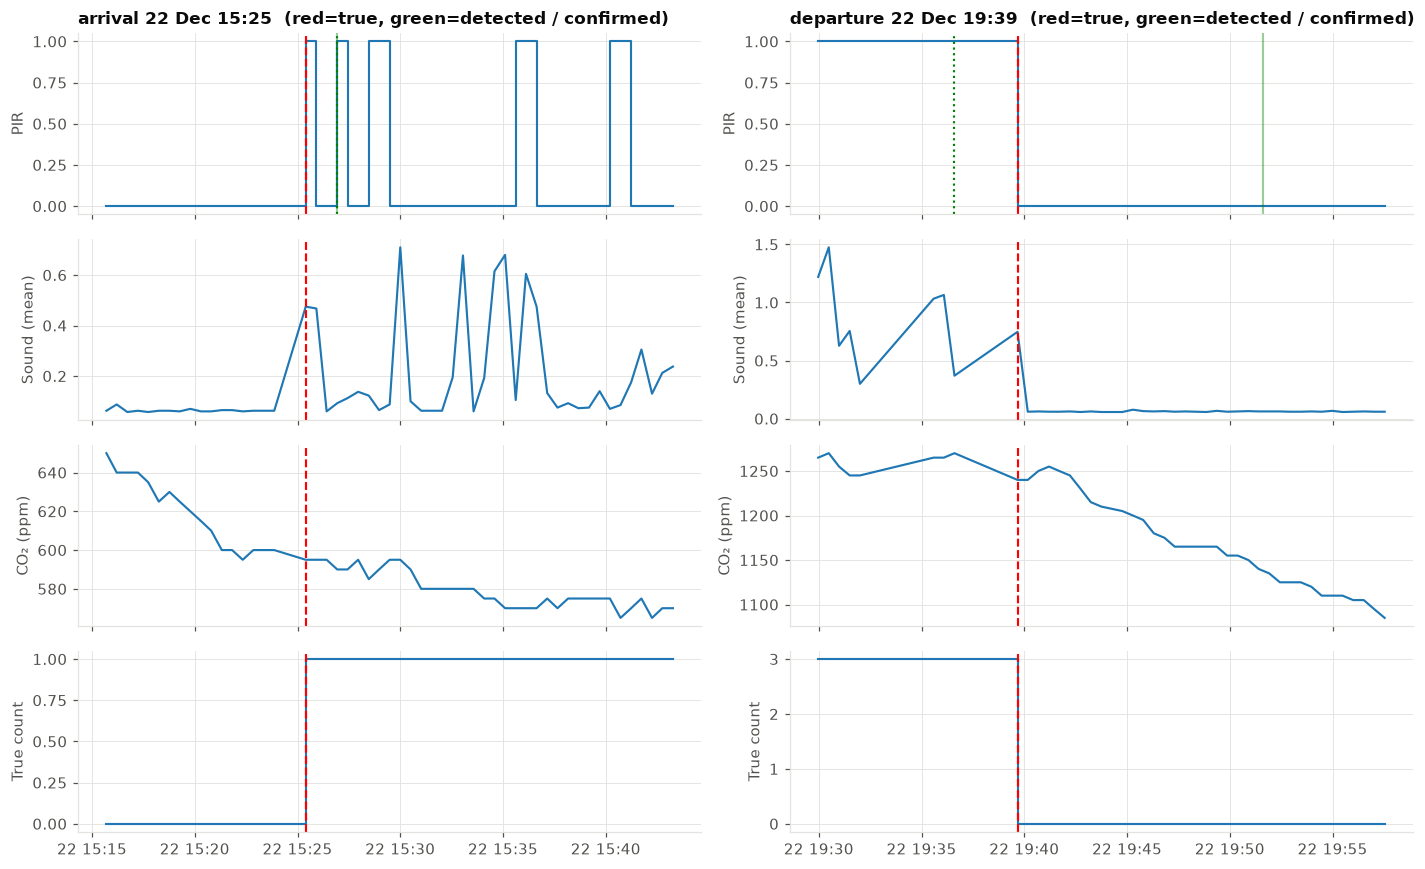

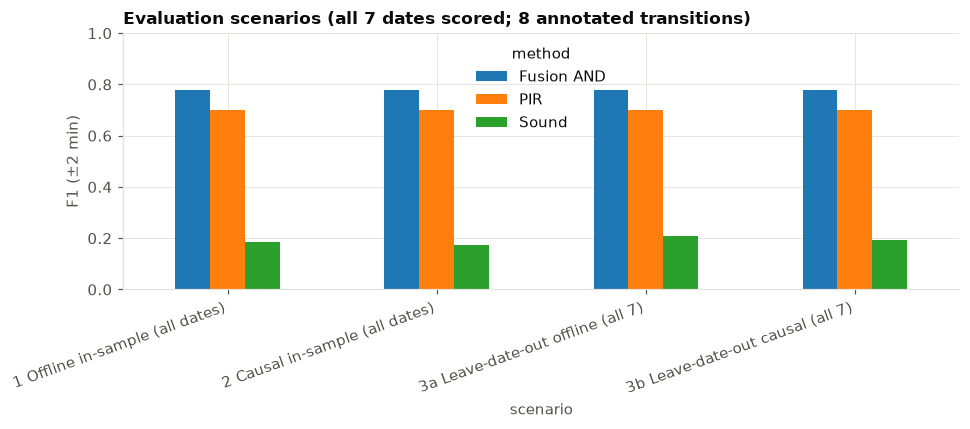

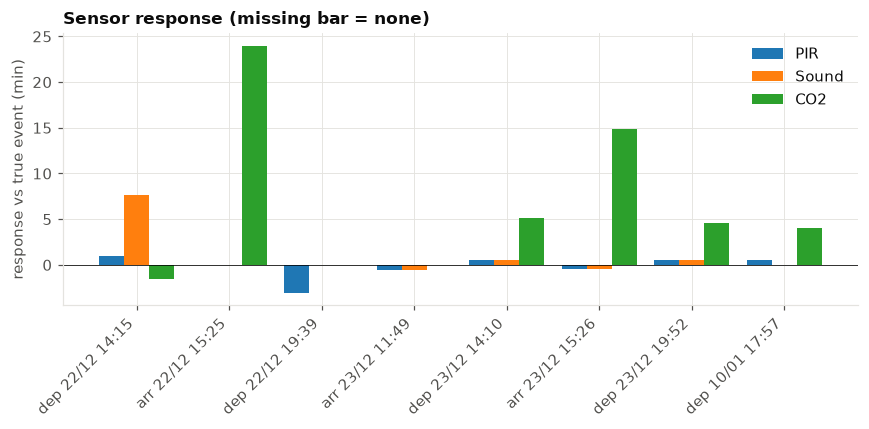

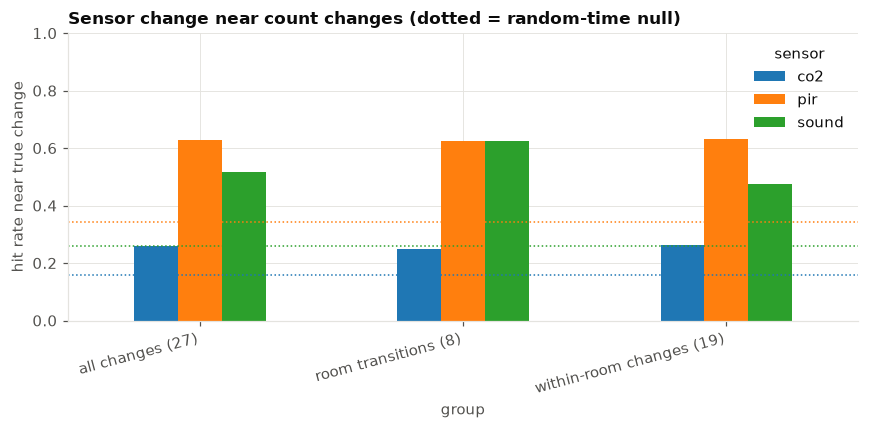

In [65]:
plt.rcParams['figure.dpi']=110
# Fig 1: example arrival + departure with sensors, causal Fusion AND detections
fig,axs=plt.subplots(4,2,figsize=(13,8),sharex='col')
for c,i in enumerate([1,2]):
    ev=T.iloc[i]; t=ev.ts; g=X_cau[(X_cau.ts>=t-pd.Timedelta(minutes=10))&(X_cau.ts<=t+pd.Timedelta(minutes=18))&(X_cau.segment==ev.segment)]
    for ax,(col,lab) in zip(axs[:,c],[('pir','PIR'),('snd','Sound (mean)'),('S5_CO2','CO₂ (ppm)'),(LAB,'True count')]):
        (ax.step(g.ts,g[col],where='post') if col in('pir',LAB) else ax.plot(g.ts,g[col])); ax.axvline(t,color='r',ls='--'); ax.set_ylabel(lab)
    pd_=det_cau['Fusion AND']; pd_=pd_[(pd_.detected_time>=g.ts.min())&(pd_.detected_time<=g.ts.max())&(pd_.segment==ev.segment)]
    for r in pd_.itertuples(): axs[0,c].axvline(r.detected_time,color='g',ls=':'); axs[0,c].axvline(r.confirm_time,color='g',ls='-',alpha=.4)
    axs[0,c].set_title(f'{ev.type} {t:%d %b %H:%M}  (red=true, green=detected / confirmed)')
fig.tight_layout(); fig.savefig(f'{FIG}/fig1_event_timeline.png',dpi=150); plt.show()
# Fig 2: performance by scenario
P=M[(M.tol_min==2)&(M.method.isin(['PIR','Fusion AND','Sound']))&(M.scenario!='OLD 3 event dates only (biased FP)')].pivot(index='scenario',columns='method',values='F1')
ax=P.plot.bar(figsize=(9,4)); ax.set_ylim(0,1); ax.set_ylabel('F1 (±2 min)'); ax.set_title('Evaluation scenarios (all 7 dates scored; 8 annotated transitions)'); plt.xticks(rotation=20,ha='right'); plt.tight_layout()
plt.savefig(f'{FIG}/fig2_performance_scenarios.png',dpi=150); plt.show()
# Fig 3: sensor responses
fig,ax=plt.subplots(figsize=(8,4)); xs=np.arange(len(delays)); w=.27
for k,(s,cl) in enumerate(zip(['PIR','Sound','CO2'],['tab:blue','tab:orange','tab:green'])): ax.bar(xs+(k-1)*w,delays[s],w,label=s,color=cl)
ax.set_xticks(xs); ax.set_xticklabels([f"{r.type[:3]} {r.event_time:%d/%m %H:%M}" for r in delays.itertuples()],rotation=45,ha='right')
ax.set_ylabel('response vs true event (min)'); ax.axhline(0,color='k',lw=.5); ax.legend(); ax.set_title('Sensor response (missing bar = none)'); plt.tight_layout()
plt.savefig(f'{FIG}/fig3_sensor_response.png',dpi=150); plt.show()
# Fig 4: all-27 lift
Q=S27.pivot(index='group',columns='sensor',values='hit_rate'); N=S27[S27.group=='all changes (27)'].set_index('sensor').null_rate
ax=Q.plot.bar(figsize=(8,4)); 
for i,(k,v) in enumerate(N.items()): ax.axhline(v,color=['C0','C1','C2'][['co2','pir','sound'].index(k)],ls=':',lw=1)
ax.set_ylim(0,1); ax.set_ylabel('hit rate near true change'); ax.set_title('Sensor change near count changes (dotted = random-time null)'); plt.xticks(rotation=15,ha='right'); plt.tight_layout()
plt.savefig(f'{FIG}/fig4_all27_vs_null.png',dpi=150); plt.show()

## Interpreting the corrected Version 6 findings

**Critical correction:** Prior Version 3 left out predictions from 4 calendar dates with no recorded room-transition events. In the **7-date complete scoring**, PIR changes from 7 TP / 3 FP / 1 FN (F1 0.778) to **7 TP / 5 FP / 1 FN (F1 0.700)**. Fusion AND remains **7 TP / 3 FP / 1 FN (F1 0.778)**. This is a *small apparent improvement* from two fewer false positives, **not evidence of universally superior fusion**.

**Main conclusion:** PIR+Sound AND detects some room-level transitions from unlabelled sensor activity. The 8 target events are not all 27 changes of person count. These detection counts represent offline event timestamp estimates, with confirmation at least 15 minutes after a departure. 1/2/5-minute tolerance is a reporting choice; sensitivity is provided. Extremely small sample, time dependence, uncertain reference annotations, and within-dataset model design preclude a generalised accuracy claim.

**Reference-label conflicts:** A false positive that coincides with noticeable sound and PIR activity while occupancy is labelled zero is a **sensor/annotation disagreement**. It still counts as FP under the reference labels; it does *not* establish that an unrecorded person entered. The near-missed departure on 22 Dec is separately investigated at ±5 min, not reclassified at ±2 min.

**Sensor response caveat:** PIR/Sound timestamp ties cannot identify a unique fastest device. CO₂ often changes later but no causal timing is proven. A change near a labelled event is not proof of its physical cause. The integration with Kirtan's K-means remains descriptive; ensure the cluster CSV provenance matches the final group pipeline.


## 5.9 Accuracy uncertainty, per-day failures and timestamps

Because this is a very small event benchmark, report **exact binomial 95% intervals** for observed precision (TP / predicted) and recall (TP / annotated events). These intervals are descriptive and assume trials are independent (an unrealistic simplification with time series), **not** guarantees of future performance. Inspect false positives and missed transitions; do not hide them. Separately record earliest `confirm_time` for prospective deployments.


In [66]:
def clopper_pearson(successes,total,alpha=.05):
    if total==0:return (np.nan,np.nan)
    return (0.0 if successes==0 else beta.ppf(alpha/2,successes,total-successes+1),
            1.0 if successes==total else beta.ppf(1-alpha/2,successes+1,total-successes))
primary=M[(M.scenario=='3b Leave-date-out causal (all 7)')&(M.tol_min==2)].copy()
primary['P_95_lo'],primary['P_95_hi']=zip(*[clopper_pearson(int(r.TP),int(r.TP+r.FP)) for r in primary.itertuples()])
primary['R_95_lo'],primary['R_95_hi']=zip(*[clopper_pearson(int(r.TP),int(r.TP+r.FN)) for r in primary.itertuples()])
primary.to_csv(OUT/'primary_metrics_with_uncertainty.csv',index=False)
display(primary[['method','TP','FP','FN','Precision','P_95_lo','P_95_hi','Recall','R_95_lo','R_95_hi','F1']].round(3))

def audit_event_matching(pred,truth,tol=2):
    # Assign globally under the same matching objective, expose matched and unmatched rows.
    p=pred.reset_index(drop=True);t=truth.reset_index(drop=True); n,m=len(p),len(t)
    mat=np.full((n,n+m),1e6,dtype=float);mat[:,m:]=2.
    for i,a in enumerate(p.itertuples()):
        for j,b in enumerate(t.itertuples()):
            diff=abs((a.detected_time-b.ts).total_seconds())/60
            if a.segment==b.segment and a.event_type==b.type and diff<=tol:mat[i,j]=diff/(tol+1)
    ii,jj=linear_sum_assignment(mat) if n and m else ([],[])
    pairs={int(i):int(j) for i,j in zip(ii,jj) if j<m and mat[i,j]<1}
    records=[]
    for i,r in p.iterrows():
        j=pairs.get(i)
        records.append({'status':'TP' if j is not None else 'FP','predicted_time':r.detected_time,'confirm_time':r.confirm_time,
                        'type':r.event_type,'true_time':t.loc[j,'ts'] if j is not None else pd.NaT,
                        'time_error_min':(r.detected_time-t.loc[j,'ts']).total_seconds()/60 if j is not None else np.nan,
                        'confirm_lag_min':(r.confirm_time-t.loc[j,'ts']).total_seconds()/60 if j is not None else np.nan})
    for j,r in t.iterrows():
        if j not in pairs.values():records.append({'status':'FN','predicted_time':pd.NaT,'confirm_time':pd.NaT,'type':r.type,'true_time':r.ts,'time_error_min':np.nan,'confirm_lag_min':np.nan})
    return pd.DataFrame(records)
AUDIT=audit_event_matching(det_loo_cau['Fusion AND'],T)
AUDIT.to_csv(OUT/'fusion_and_event_audit.csv',index=False)
print('Event-by-event audit (primary method):');display(AUDIT)
print('Performance by held-out event date (tiny denominators):')
perday=[]
for day in OCC_DATES:
    sub=T[T.ts.dt.date==day]
    for name in ['PIR','Fusion AND']:
        pred=det_loo_cau[name]; pred=pred[pred.detected_time.dt.date==day]
        perday.append({'date':str(day),'method':name,'n_true':len(sub),'n_pred':len(pred),**match(pred,sub,2)})
DAY=pd.DataFrame(perday);DAY.to_csv(OUT/'metrics_by_held_out_day.csv',index=False);display(DAY.round(3))


,method,TP,FP,FN,Precision,P_95_lo,P_95_hi,Recall,R_95_lo,R_95_hi,F1
46,PIR,7,5,1,0.583,0.277,0.848,0.875,0.473,0.997,0.700
49,Sound,5,39,3,0.114,0.038,0.246,0.625,0.245,0.915,0.192
52,CO2,1,140,7,0.007,0.000,0.039,0.125,0.003,0.527,0.013
55,Fusion OR,5,37,3,0.119,0.040,0.256,0.625,0.245,0.915,0.200
58,Fusion AND,7,3,1,0.700,0.348,0.933,0.875,0.473,0.997,0.778


Event-by-event audit (primary method):


,status,predicted_time,confirm_time,type,true_time,time_error_min,confirm_lag_min
0,TP,2017-12-22 14:16:59,2017-12-22 14:31:59,departure,2017-12-22 14:15:58,1.016667,16.016667
1,TP,2017-12-22 15:26:56,2017-12-22 15:26:56,arrival,2017-12-22 15:25:24,1.533333,1.533333
2,FP,2017-12-22 19:36:36,2017-12-22 19:51:36,departure,NaT,NaN,NaN
3,TP,2017-12-23 11:49:16,2017-12-23 11:49:16,arrival,2017-12-23 11:49:16,0.000000,0.000000
4,TP,2017-12-23 14:10:42,2017-12-23 14:25:42,departure,2017-12-23 14:10:11,0.516667,15.516667
5,FP,2017-12-23 14:43:53,2017-12-23 14:43:53,arrival,NaT,NaN,NaN
6,FP,2017-12-23 14:44:54,2017-12-23 14:59:54,departure,NaT,NaN,NaN
7,TP,2017-12-23 15:26:46,2017-12-23 15:26:46,arrival,2017-12-23 15:26:46,0.000000,0.000000
8,TP,2017-12-23 19:52:47,2017-12-23 20:07:47,departure,2017-12-23 19:52:16,0.516667,15.516667
9,TP,2018-01-10 17:57:27,2018-01-10 18:12:27,departure,2018-01-10 17:57:27,0.000000,15.000000


Performance by held-out event date (tiny denominators):


,date,method,n_true,n_pred,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
0,2017-12-22,PIR,3,3,2,1,1,0.667,0.667,0.667,1.275,8.775
1,2017-12-22,Fusion AND,3,3,2,1,1,0.667,0.667,0.667,1.275,8.775
2,2017-12-23,PIR,4,6,4,2,0,0.667,1.000,0.800,0.258,7.758
3,2017-12-23,Fusion AND,4,6,4,2,0,0.667,1.000,0.800,0.258,7.758
4,2018-01-10,PIR,1,1,1,0,0,1.000,1.000,1.000,0.500,15.500
5,2018-01-10,Fusion AND,1,1,1,0,0,1.000,1.000,1.000,0.000,15.000


## 5.10 Baseline and model comparison (replacing the weak shifted-time control)

A randomly shifted event-time null is almost guaranteed to give F1≈0 for sparse events at ±2 min. It is not a meaningful competing detector. We therefore compare a very simple **raw-PIR activity/quiet rule** (any PIR activation; no 2-of-7 persistence) with the production-style PIR and the PIR+Sound AND rule. Each method uses the same 15-minute quiet hold and is evaluated over **all 7 dates**. This baseline has no learnable sensor threshold and does not require fitting on occupancy labels. Results are exploratory because the model family and hold time were designed with knowledge of the data.


,method,n_detected,TP,FP,FN,Precision,Recall,F1
1,PIR,12,7,5,1,0.583,0.875,0.700
4,Fusion AND,10,7,3,1,0.700,0.875,0.778
7,Raw PIR (no persistence),19,6,13,2,0.316,0.750,0.444


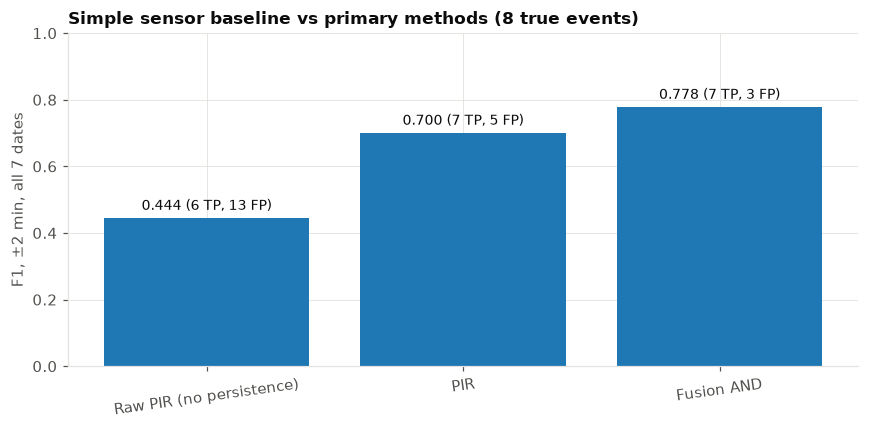

In [67]:
# Simple baseline: raw PIR on/off, no persistence; detects activity beginning or ending after a long quiet interval.
BASE_RAW= df.copy()
BASE_RAW['pir_raw']=(BASE_RAW[['S6_PIR','S7_PIR']].max(axis=1)>0)
raw_pir=activity_events(BASE_RAW,'pir_raw',HOLD_MIN,'Raw PIR (no persistence)')
BASELINE=pd.DataFrame([
    dict(method='Raw PIR (no persistence)',tol_min=tol,n_detected=len(raw_pir),**match(raw_pir,T,tol))
    for tol in (1,2,5)
])
BASELINE.to_csv(OUT/'simple_raw_pir_baseline.csv',index=False)
main_base = pd.concat([
    M[(M.scenario=='3b Leave-date-out causal (all 7)') & M.method.isin(['PIR','Fusion AND'])],
    BASELINE.assign(scenario='Baseline (raw PIR, all 7 dates)')
],ignore_index=True)
main_base.to_csv(OUT/'baseline_vs_primary.csv',index=False)
display(main_base[main_base.tol_min==2][['method','n_detected','TP','FP','FN','Precision','Recall','F1']].round(3))
fig,ax=plt.subplots(figsize=(8,4))
sel=main_base[main_base.tol_min==2].set_index('method').reindex(['Raw PIR (no persistence)','PIR','Fusion AND'])
ax.bar(range(len(sel)),sel.F1)
ax.set_xticks(range(len(sel)),sel.index,rotation=8)
ax.set_ylim(0,1);ax.set_ylabel('F1, ±2 min, all 7 dates')
ax.set_title('Simple sensor baseline vs primary methods (8 true events)')
for j,r in enumerate(sel.itertuples()):ax.text(j,r.F1+.025,f'{r.F1:.3f} ({r.TP} TP, {r.FP} FP)',ha='center',fontsize=9)
fig.tight_layout();fig.savefig(FIG/'fig5_raw_pir_baseline.png',dpi=180);plt.show()


## 5.10.1 Link to clusters (RQ3 integration)

If the shared notebook has already exported `data/results/clusters_k5.csv`, attach 5-minute room-state cluster names at the sensor event windows (no retraining here). This is **descriptive triangulation only**: the clusters themselves were estimated on the dataset, and this does not validate event detection. When the file is absent, report a clear skip rather than fabricate cluster relationships.


In [68]:
# Version 6: use the group-supplied clusters verbatim (never fit/re-label K-Means here).
# The notebook is still runnable standalone; within the merged group notebook, also compare to W.
cluster_candidates = [Path('data/results/clusters_k5.csv'), Path('clusters_k5.csv')]
cluster_file = next((p for p in cluster_candidates if p.exists()), None)
if cluster_file is None:
    raise FileNotFoundError('The group-provided clusters_k5.csv is required for Version 6. Put it under data/results/.')
cl = pd.read_csv(cluster_file, parse_dates=['start'])
needed = {'segment','win','start','cluster','cluster_name','dist_to_centroid'}
assert needed.issubset(cl.columns), f'Missing group cluster columns: {needed-set(cl.columns)}'
assert cl[['segment','win']].duplicated().sum() == 0, 'Duplicate group cluster window IDs'
assert len(cl) == 1044, f'Unexpected cluster window count: {len(cl)} (expected 1044 for this dataset)'
assert cl.cluster.nunique() == 5, 'Expected five group-derived clusters'
assert cl.start.notna().all(), 'Unparseable group cluster timestamps'
assert cl.groupby('segment').start.apply(lambda s:s.is_monotonic_increasing).all()
if 'W' in globals() and isinstance(W,pd.DataFrame) and {'segment','win','start','cluster','cluster_name'}.issubset(W.columns):
    group_check = W[['segment','win','start','cluster','cluster_name']].copy()
    file_check = cl[['segment','win','start','cluster','cluster_name']].copy()
    group_check['start']=pd.to_datetime(group_check['start'])
    group_check=group_check.sort_values(['segment','win']).reset_index(drop=True)
    file_check=file_check.sort_values(['segment','win']).reset_index(drop=True)
    pd.testing.assert_frame_equal(group_check,file_check,check_dtype=False)
    print('PASS: supplied cluster file exactly matches W from Section 7.4–7.8 of group notebook')
else:
    print('Standalone mode: cluster schema and window keys verified; full W comparison occurs in merged group notebook.')
print('Source of cluster assignments:',cluster_file,'| windows:',len(cl),'| clusters:',cl.cluster.value_counts().sort_index().to_dict())
# Link each detection to its actual 5-minute window by group segment AND window index.
# This avoids treating a nonexistent/low-fill window as a valid state.
segment_starts = df.groupby('segment').ts.min()
events6 = det_loo_cau['Fusion AND'].sort_values('detected_time').copy()
events6['win'] = [int((r.detected_time-segment_starts.loc[r.segment]).total_seconds()//300) for r in events6.itertuples()]
attached = events6.merge(cl[['segment','win','start','cluster','cluster_name','dist_to_centroid']],
                         on=['segment','win'],how='left',validate='many_to_one')
attached['window_age_min']=(attached.detected_time-attached.start).dt.total_seconds()/60
attached['has_group_cluster']=attached.cluster.notna()
assert (attached.window_age_min.dropna()>=0).all() and (attached.window_age_min.dropna()<5.001).all()
attached.to_csv(OUT/'v6_detected_events_with_official_group_clusters.csv',index=False)
print('Group cluster attached to',int(attached.has_group_cluster.sum()),'/',len(attached),'detected events.')
display(pd.crosstab(attached.event_type,attached.cluster_name,dropna=False))
# For descriptive context, sample the windows containing t-7.5 and t+7.5 min.
# Use actual group window IDs, without nearest-neighbour substitution across missing windows.
links=[]
cl_index=cl.set_index(['segment','win'])
for r in events6.itertuples():
    ss=segment_starts.loc[r.segment]
    def state_at(target):
        wn=int((target-ss).total_seconds()//300)
        idx=(int(r.segment),wn)
        return cl_index.loc[idx,'cluster_name'] if idx in cl_index.index else None
    links.append({'estimated_event_time':r.detected_time,'event_type':r.event_type,'segment':r.segment,
                  'cluster_7_5min_before':state_at(r.detected_time-pd.Timedelta(minutes=7.5)),
                  'cluster_7_5min_after':state_at(r.detected_time+pd.Timedelta(minutes=7.5))})
LINK6=pd.DataFrame(links)
LINK6['changed_cluster']=(LINK6.cluster_7_5min_before.notna() & LINK6.cluster_7_5min_after.notna() &
                           LINK6.cluster_7_5min_before.ne(LINK6.cluster_7_5min_after))
LINK6.to_csv(OUT/'v6_official_group_cluster_before_after.csv',index=False)
print('Descriptive room-state changes:');display(LINK6)
print('Important: clustering uses overlapping sensor data. This comparison is descriptive, NOT independent model validation.')


PASS: supplied cluster file exactly matches W from Section 7.4–7.8 of group notebook
Source of cluster assignments: data/results/clusters_k5.csv | windows: 1044 | clusters: {0: 82, 1: 545, 2: 88, 3: 216, 4: 113}
Group cluster attached to 9 / 10 detected events.


cluster_name,"Busy: high light, CO₂ rising",Occupied: moderate activity,NaN
event_type,,,
arrival,0,4,0
departure,3,2,1


Descriptive room-state changes:


,estimated_event_time,event_type,segment,cluster_7_5min_before,cluster_7_5min_after,changed_cluster
0,2017-12-22 14:16:59,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
1,2017-12-22 15:26:56,arrival,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
2,2017-12-22 19:36:36,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
3,2017-12-23 11:49:16,arrival,1,Empty: daylight only,Occupied: moderate activity,True
4,2017-12-23 14:10:42,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
5,2017-12-23 14:43:53,arrival,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
6,2017-12-23 14:44:54,departure,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
7,2017-12-23 15:26:46,arrival,1,"Recently vacated: dark, CO₂ falling",Occupied: moderate activity,True
8,2017-12-23 19:52:47,departure,1,"Busy: high light, CO₂ rising","Recently vacated: dark, CO₂ falling",True
9,2018-01-10 17:57:27,departure,3,Occupied: moderate activity,"Recently vacated: dark, CO₂ falling",True


Important: clustering uses overlapping sensor data. This comparison is descriptive, NOT independent model validation.


## 5.10.2 poster handoff

**Preferred comparison:** all 7 recorded dates, causal leave-date-out sensor-threshold fitting. Note that only 3 dates contained any of the 8 fully empty/occupied reference transitions. Score every detector alert from all 7 dates. Report the **2-minute primary** and **5-minute sensitivity** side by side, plus a simple raw-PIR baseline.

**Poster text (verified again in the results table below):** Among 8 labelled whole-room transitions, Fusion AND identified 7 within ±2 min, with 3 unmatched alerts (P=0.70, R=0.875, F1=0.778). PIR alone found 7 with 5 unmatched alerts (P=0.583, R=0.875, F1=0.700), after correctly counting alerts on all 7 dates. At ±5 min, Fusion AND matched all 8 (F1=0.889). These are exploratory retrospective timestamp scores; departure confirmation requires ≥15 quiet minutes. Some unmatched alerts coincide with sensor activity despite a zero-occupancy label, not verified annotation faults. Do not generalise these small counts.

**RQ3 coordination:** Link events to existing 5-minute clusters and to Person 4 anomaly results, provided those are supplied by the team. The optional cluster join is not an independent validation. Confirm cluster-file seed, features, standardisation and label mapping against Kirtan's actual notebook before using the plot.


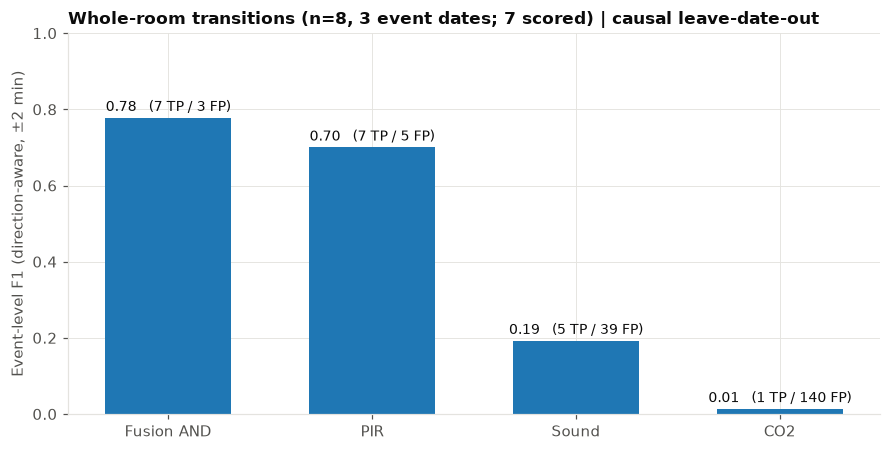

VERSION 6 COMPLETED — CSV: /Users/kirtan/Professional/Queens University/Data mineing/Assignment - 1 /Notebook and prepared data/Final/data/results/section5_version6  | Figures: /Users/kirtan/Professional/Queens University/Data mineing/Assignment - 1 /Notebook and prepared data/Final/figures/section5_version6


In [69]:
# One clean poster panel comparing *primary* methods, with event denominators visible.
sub=primary[primary.method.isin(['PIR','Sound','CO2','Fusion AND'])].set_index('method').loc[['Fusion AND','PIR','Sound','CO2']]
fig,ax=plt.subplots(figsize=(8.2,4.2))
xp=np.arange(len(sub)); bars=ax.bar(xp,sub.F1,width=.62)
for i,r in enumerate(sub.itertuples()):
    ax.text(i,r.F1+.018,f'{r.F1:.2f}   ({r.TP} TP / {r.FP} FP)',ha='center',fontsize=9)
ax.set_xticks(xp,sub.index,rotation=0);ax.set_ylim(0,max(1,sub.F1.max()+.12))
ax.set_ylabel('Event-level F1 (direction-aware, ±2 min)')
ax.set_title('Whole-room transitions (n=8, 3 event dates; 7 scored) | causal leave-date-out')
fig.tight_layout();fig.savefig(FIG/'fig6_primary_poster_performance.png',dpi=220);plt.show()
print('VERSION 6 COMPLETED — CSV:', OUT.resolve(),' | Figures:',FIG.resolve())


## 5.10.3 Forensic audit of unmatched alerts and near-misses

List *all* unmatched events. For any suspicious sensor activity under an occupancy label of zero, report the raw PIR and Sound readings and closest reference transition. **Keep the FP classification:** the available data cannot prove an annotation error. The December 22 ~19:36 versus ~19:39 departure is a tolerance-sensitive near miss, not a hit at ±2 min.


In [70]:
# Use independently audited 1:1 assignment; retain all-date false positives.
AUDIT5=audit_event_matching(det_loo_cau['Fusion AND'],T,5)
AUDIT5.to_csv(OUT/'fusion_and_audit_5min.csv',index=False)
AUDIT.to_csv(OUT/'fusion_and_audit_2min.csv',index=False)
print('2-minute event audit:');display(AUDIT.sort_values(['status','predicted_time'],na_position='last'))
print('5-minute event audit:');display(AUDIT5.groupby('status').size())
fp=AUDIT[AUDIT.status=='FP'].copy()
rows=[]
for r in fp.itertuples():
    nearest=df.iloc[(df.ts-r.predicted_time).abs().argsort()[:1]].iloc[0]
    reference=T[T.segment==nearest.segment]
    near=(reference.ts-r.predicted_time).abs().dt.total_seconds()/60
    rows.append({'predicted_time':r.predicted_time,'estimated_type':r.type,
                 'label_count_at_nearest_reading':int(nearest[LAB]),
                 'pir_s6':float(nearest['S6_PIR']),'pir_s7':float(nearest['S7_PIR']),
                 'mean_sound_at_reading':float(nearest[SND].mean()),
                 'closest_true_transition_min':float(near.min()) if len(near) else np.nan,
                 'note':'Unmatched under recorded occupancy labels; not proof of actual person or faulty annotation'})
FP_FORENSIC=pd.DataFrame(rows)
FP_FORENSIC.to_csv(OUT/'false_positive_sensor_audit.csv',index=False)
print('Unmatched signal evidence (do not relabel as true events):');display(FP_FORENSIC)


2-minute event audit:


,status,predicted_time,confirm_time,type,true_time,time_error_min,confirm_lag_min
10,FN,NaT,NaT,departure,2017-12-22 19:39:40,NaN,NaN
2,FP,2017-12-22 19:36:36,2017-12-22 19:51:36,departure,NaT,NaN,NaN
5,FP,2017-12-23 14:43:53,2017-12-23 14:43:53,arrival,NaT,NaN,NaN
6,FP,2017-12-23 14:44:54,2017-12-23 14:59:54,departure,NaT,NaN,NaN
0,TP,2017-12-22 14:16:59,2017-12-22 14:31:59,departure,2017-12-22 14:15:58,1.016667,16.016667
1,TP,2017-12-22 15:26:56,2017-12-22 15:26:56,arrival,2017-12-22 15:25:24,1.533333,1.533333
3,TP,2017-12-23 11:49:16,2017-12-23 11:49:16,arrival,2017-12-23 11:49:16,0.000000,0.000000
4,TP,2017-12-23 14:10:42,2017-12-23 14:25:42,departure,2017-12-23 14:10:11,0.516667,15.516667
7,TP,2017-12-23 15:26:46,2017-12-23 15:26:46,arrival,2017-12-23 15:26:46,0.000000,0.000000
8,TP,2017-12-23 19:52:47,2017-12-23 20:07:47,departure,2017-12-23 19:52:16,0.516667,15.516667


5-minute event audit:


status
FP    2
TP    8
dtype: int64

Unmatched signal evidence (do not relabel as true events):


,predicted_time,estimated_type,label_count_at_nearest_reading,pir_s6,pir_s7,mean_sound_at_reading,closest_true_transition_min,note
0,2017-12-22 19:36:36,departure,3,1.0,1.0,0.3700,3.066667,Unmatched under recorded occupancy labels; not...
1,2017-12-23 14:43:53,arrival,0,1.0,0.0,0.3200,33.700000,Unmatched under recorded occupancy labels; not...
2,2017-12-23 14:44:54,departure,0,1.0,0.0,0.6325,34.716667,Unmatched under recorded occupancy labels; not...


## 5.10.4 Seven-date accountability and headline tolerance table

Every recorded date must be shown, including dates with zero true transitions. For days where the 15-minute hold uses readings across midnight, the event is attributed to the calendar date of its *estimated* timestamp. This makes the evaluation reproducible, but does not represent a live prospective date-by-date deployment.


**Unit of evaluation:** the 8 annotated whole-room transitions; each predicted arrival and departure counts separately. A brief unannotated burst may generate both an unmatched arrival and departure. An optional episode view can group that burst for interpretation but must **not** replace the primary event-level F1.


In [71]:
all_day_rows=[]
for day in ALL_DATES:
    truth=T[T.ts.dt.date==day]
    for method in ['PIR','Fusion AND','Sound','CO2']:
        pred=det_loo_cau[method];pred=pred[pred.detected_time.dt.date==day]
        all_day_rows.append(dict(date=str(day),method=method,n_truth=len(truth),n_detected=len(pred),**match(pred,truth,2)))
DAYS7=pd.DataFrame(all_day_rows)
DAYS7.to_csv(OUT/'seven_date_detection_accountability.csv',index=False)
display(DAYS7[DAYS7.method.isin(['PIR','Fusion AND'])][['date','method','n_truth','n_detected','TP','FP','FN']])
TOL=M[(M.scenario=='3b Leave-date-out causal (all 7)')&(M.method.isin(['Fusion AND','PIR']))]
display(TOL[['method','tol_min','TP','FP','FN','Precision','Recall','F1','ConfirmLag_min']].sort_values(['method','tol_min']).round(3))
TOL.to_csv(OUT/'poster_2min_5min_tolerance.csv',index=False)
assert (DAYS7[DAYS7.method=='PIR'].FP.sum()==match(det_loo_cau['PIR'],T,2)['FP'])
assert (DAYS7[DAYS7.method=='Fusion AND'].FP.sum()==match(det_loo_cau['Fusion AND'],T,2)['FP'])
assert match(det_loo_cau['PIR'],T,2)['FP']==5
assert match(det_loo_cau['Fusion AND'],T,2)['FP']==3
print('All-date evaluation checks PASS')


,date,method,n_truth,n_detected,TP,FP,FN
0,2017-12-22,PIR,3,3,2,1,1
1,2017-12-22,Fusion AND,3,3,2,1,1
4,2017-12-23,PIR,4,6,4,2,0
5,2017-12-23,Fusion AND,4,6,4,2,0
8,2017-12-24,PIR,0,0,0,0,0
9,2017-12-24,Fusion AND,0,0,0,0,0
12,2017-12-25,PIR,0,2,0,2,0
13,2017-12-25,Fusion AND,0,0,0,0,0
16,2017-12-26,PIR,0,0,0,0,0
17,2017-12-26,Fusion AND,0,0,0,0,0


,method,tol_min,TP,FP,FN,Precision,Recall,F1,ConfirmLag_min
57,Fusion AND,1,5,5,3,0.500,0.625,0.556,15.000
58,Fusion AND,2,7,3,1,0.700,0.875,0.778,15.000
59,Fusion AND,5,8,2,0,0.800,1.000,0.889,13.467
45,PIR,1,5,7,3,0.417,0.625,0.500,15.500
46,PIR,2,7,5,1,0.583,0.875,0.700,15.500
47,PIR,5,8,4,0,0.667,1.000,0.800,13.717


All-date evaluation checks PASS


### conclusions and integrity checklist

- All 7 dates scored (including zero-event dates): **yes**.
- Sensor thresholds held out by evaluated date: **yes**; fixed detector design is exploratory, not cross-validated.
- Labels used only in scoring/diagnostic figures, not in detection threshold fitting: **yes**.
- Event-estimate and confirmation timestamps kept separate: **yes**.
- ±2 min and ±5 min displayed together; unmatched active readings retained as FP: **yes**.
- All 27 changes versus 8 room transitions explicitly distinguished: **yes**.
- Full reproducibility: CSV, notebook, event audit and figure exports. **Check group file provenance and official assessment brief separately before submission.**


## 5.11 independent methodological audit (what changed and what did not)

**Primary result stays fixed:** all **7** recorded dates, causal sensor windows, threshold fitting without the scored calendar date, direction-aware one-to-one ±2-minute matching, **8** annotated whole-room transitions. Unmatched predictions on zero-transition dates count as false positives.

**Three distinct quantities must not be confused:** (a) an *estimated event timestamp* inferred from a sensor transition; (b) the later *confirmation timestamp*, which for a departure requires 15 minutes of quiet; (c) the **annotation interval** between the last old occupancy label and first new label when observations are missing.

The remaining analyses are **diagnostic/sensitivity analyses** only. They do not tune the detector on the reference annotations, do not alter the 7/3/1 primary counts, and do not claim to confirm an unrecorded entry.

In [72]:
# --- Integrity: re-check primary numbers against unfiltered 7-date predictions ---
assert len(ALL_DATES)==7 and len(ALL)==27 and len(T)==8
v6_main=[]
for method in ['Raw PIR (no persistence)','PIR','Fusion AND','Sound','CO2']:
    p=raw_pir if method.startswith('Raw ') else det_loo_cau[method]
    for tol in (1,2,5):
        v6_main.append({'method':method,'tolerance_min':tol,'n_predictions':len(p),**match(p,T,tol)})
V6_PRIMARY=pd.DataFrame(v6_main)
assert match(det_loo_cau['Fusion AND'],T,2)['TP']==7
assert match(det_loo_cau['Fusion AND'],T,2)['FP']==3
assert match(det_loo_cau['PIR'],T,2)['FP']==5
V6_PRIMARY.to_csv(OUT/'v6_primary_all7_tolerance_1_2_5.csv',index=False)
display(V6_PRIMARY[V6_PRIMARY.tolerance_min==2].round(3))
print('All 7 dates evaluated; primary confusion counts preserved.')

,method,tolerance_min,n_predictions,TP,FP,FN,Precision,Recall,F1,MedianErr_min,ConfirmLag_min
1,Raw PIR (no persistence),2,19,6,13,2,0.316,0.750,0.444,0.250,7.75
4,PIR,2,12,7,5,1,0.583,0.875,0.700,0.517,15.50
7,Fusion AND,2,10,7,3,1,0.700,0.875,0.778,0.517,15.00
10,Sound,2,44,5,39,3,0.114,0.625,0.192,0.000,15.00
13,CO2,2,141,1,140,7,0.007,0.125,0.013,0.500,0.50


All 7 dates evaluated; primary confusion counts preserved.


## 5.11.1 Two alarms versus one short activity episode (supplementary only)

A 2017-12-23 **14:43:53** arrival alarm followed by a **14:44:54** departure alarm overlaps a short activity burst while the occupancy count is labelled zero. The event-level benchmark legitimately counts **both unmatched predicted transitions** (one false arrival and one false departure). For *investigation workload*, these can be regarded as one contiguous **unmatched activity episode**. The number of false-alert episodes is descriptive and **must not be substituted into event-level Precision/F1**.

A possible interpretation is an unannotated presence, activity transmitted from outside the monitored space, sensor noise or a label issue; **the data alone cannot establish which**.

In [73]:
# Cluster only UNMATCHED Fusion AND alerts in the same segment within 2 minutes.
fp6=AUDIT[AUDIT.status=='FP'].copy().sort_values('predicted_time').reset_index(drop=True)
seg_lookup=df.set_index('ts')['segment']
fp6['segment']=fp6.predicted_time.map(seg_lookup)
fp6['delta_prev_min']=fp6.predicted_time.diff().dt.total_seconds()/60
join_previous=(fp6.segment.eq(fp6.segment.shift()) & fp6.delta_prev_min.le(2))
fp6['episode_id']=(~join_previous).cumsum()
episodes=fp6.groupby('episode_id',as_index=False).agg(
    start=('predicted_time','min'),end=('predicted_time','max'),
    number_of_unmatched_transition_alarms=('status','size'),
    event_types=('type',lambda z:', '.join(z))
)
episodes['duration_between_alarms_sec']=(episodes.end-episodes.start).dt.total_seconds()
fp6.to_csv(OUT/'v6_unmatched_alarm_episode_assignments.csv',index=False)
episodes.to_csv(OUT/'v6_false_alarm_episodes_descriptive.csv',index=False)
print('Primary unmatched transition alarms:',len(fp6),'| Descriptive unmatched alert episodes:',len(episodes))
display(episodes)
assert len(fp6)==3 and len(episodes)==2

Primary unmatched transition alarms: 3 | Descriptive unmatched alert episodes: 2


,episode_id,start,end,number_of_unmatched_transition_alarms,event_types,duration_between_alarms_sec
0,1,2017-12-22 19:36:36,2017-12-22 19:36:36,1,departure,0.0
1,2,2017-12-23 14:43:53,2017-12-23 14:44:54,2,"arrival, departure",61.0


## 5.11.2 Gap-aware annotation audit: do NOT silently turn a miss into a hit

For an occupancy-count change observed just after an acquisition gap, its physical transition could have occurred **anywhere between** the last observation with the old label and the first observation with the new label. We report that interval and whether a detector estimate lies at/near the interval boundary; this flags **time-label uncertainty**, not validated correctness. The main ±2-minute matching continues to use recorded annotation timestamps.

For the 2017-12-22 evening departure, the final recorded activity occurs at **19:36:36** and the new zero-occupancy annotation is at **19:39:40** (184 seconds apart). The estimated departure at 19:36:36 is at the **old-label boundary**; it is not logically proved to be inside an open interval following that old-label observation. Under a more lenient ±5-minute tolerance it does match. Both distinctions are documented.

In [74]:
g= df[['ts','segment',LAB]].copy()
g['previous_ts']=g.groupby('segment').ts.shift()
g['previous_count']=g.groupby('segment')[LAB].shift()
uncertain=g[(g[LAB]!=g.previous_count)&g.previous_count.notna()].copy()
uncertain['gap_sec']=(uncertain.ts-uncertain.previous_ts).dt.total_seconds()
uncertain['transition_type']=np.where(uncertain[LAB]>uncertain.previous_count,'arrival','departure')
trans_uncertain=uncertain[(((uncertain.previous_count==0)&(uncertain[LAB]>0))|((uncertain.previous_count>0)&(uncertain[LAB]==0)))].copy()
# Connect each reference event to its nearest same-direction predicted event within 5 minutes, for investigation only.
extra=[]
for _,r in trans_uncertain.iterrows():
    sub=det_loo_cau['Fusion AND']
    sub=sub[(sub.segment==r.segment)&(sub.event_type==r.transition_type)].copy()
    sub['signed_offset_min']=(sub.detected_time-r.ts).dt.total_seconds()/60
    sub=sub[sub.signed_offset_min.abs()<=5].sort_values('signed_offset_min',key=lambda z:z.abs())
    candidate=sub.iloc[0] if len(sub) else None
    extra.append({'annotation_ts':r.ts,'event_type':r.transition_type,'last_old_label_ts':r.previous_ts,
                  'annotation_gap_sec':r.gap_sec,'nearest_prediction_within_5min':candidate.detected_time if candidate is not None else pd.NaT,
                  'prediction_within_open_gap':bool(r.previous_ts<candidate.detected_time<=r.ts) if candidate is not None else False,
                  'prediction_at_old_label_boundary':bool(candidate.detected_time==r.previous_ts) if candidate is not None else False})
GAP_AUDIT=pd.DataFrame(extra)
GAP_AUDIT.to_csv(OUT/'v6_ground_truth_timestamp_uncertainty.csv',index=False)
display(GAP_AUDIT[GAP_AUDIT.annotation_gap_sec>90])

,annotation_ts,event_type,last_old_label_ts,annotation_gap_sec,nearest_prediction_within_5min,prediction_within_open_gap,prediction_at_old_label_boundary
1,2017-12-22 15:25:24,arrival,2017-12-22 15:23:52,92.0,2017-12-22 15:26:56,False,False
2,2017-12-22 19:39:40,departure,2017-12-22 19:36:36,184.0,2017-12-22 19:36:36,False,True


## 5.11.3 HOLD_MIN sensitivity on the **same primary benchmark**

The earlier hold sensitivity table only reported ±5-minute **in-sample** results. Here we repeat it with **causal sensor windows, leave-date-out Sound/CO₂ threshold fitting, all seven dates scored, and ±2 minutes**. This is still a *post-hoc sensitivity analysis* on the dataset used throughout development; it is **not** hyperparameter optimization or a fresh held-out test. The chosen `HOLD_MIN = 15` remains fixed for the headline result.

In [75]:
HOLD_VALUES=(10,15,20,30,45)
# Cache per-fold sensor activity; only post-processing needs repeating for each hold.
fold_x={}
for day in ALL_DATES:
    fold_x[day]=prepare(df,df.date!=day,True)[0]
sens=[]
for hold in HOLD_VALUES:
    for method,flag in [('PIR','pir_act'),('Fusion AND','fus_and')]:
        preds=[]
        for day,x in fold_x.items():
            p=activity_events(x,flag,hold,method)
            preds.append(p[p.detected_time.dt.date==day])
        p=pd.concat(preds,ignore_index=True)
        for tol in (2,5):
            sens.append({'hold_min':hold,'method':method,'tolerance_min':tol,'n_pred':len(p),**match(p,T,tol)})
HOLD_SENS=pd.DataFrame(sens)
HOLD_SENS.to_csv(OUT/'v6_hold_sensitivity_causal_leave_date_out_all7.csv',index=False)
display(HOLD_SENS[HOLD_SENS.tolerance_min==2][['hold_min','method','n_pred','TP','FP','FN','F1']].round(3))
assert (HOLD_SENS.query('hold_min==15 and method=="Fusion AND" and tolerance_min==2').iloc[0].F1 == match(det_loo_cau['Fusion AND'],T,2)['F1'])

,hold_min,method,n_pred,TP,FP,FN,F1
0,10,PIR,14,7,7,1,0.636
2,10,Fusion AND,14,7,7,1,0.636
4,15,PIR,12,7,5,1,0.700
6,15,Fusion AND,10,7,3,1,0.778
8,20,PIR,12,7,5,1,0.700
10,20,Fusion AND,10,7,3,1,0.778
12,30,PIR,12,7,5,1,0.700
14,30,Fusion AND,10,7,3,1,0.778
16,45,PIR,8,5,3,3,0.625
18,45,Fusion AND,6,5,1,3,0.714


## 5.11.4 Sensor response: direction and specificity matter

PIR and Sound response timings should be described as *sensor activity relative to labels*, not proven physical reaction times. The departure analysis uses **last active timestamps**, not first changes. The high CO₂ alarm rate (141 total) prevents a reliable claim that CO₂ was an equally fast departure sensor. For a clean poster-facing comparison, exclude CO₂ from any *fastest detector* ranking, while **retaining its standalone baseline performance and its measured values**. Avoid concluding that an unmatched zero-label activity confirms a label fault.

In [76]:
# A compact non-misleading sensor-response summary.
RESP_V6=delays[['event_time','type','PIR','Sound','CO2']].copy()
RESP_V6['PIR_vs_Sound']=np.select(
    [RESP_V6.PIR.isna()&RESP_V6.Sound.isna(),RESP_V6.PIR.isna(),RESP_V6.Sound.isna(),
     (RESP_V6.PIR-RESP_V6.Sound).abs()<=0.52,RESP_V6.PIR<RESP_V6.Sound],
    ['no detected response','Sound only','PIR only','indistinguishable at ~30s cadence','PIR earlier'],
    default='Sound earlier')
RESP_V6['CO2_caveat']='CO2 threshold crossings not used to declare fastest response'
RESP_V6.to_csv(OUT/'v6_response_interpretation_PIR_sound_CO2_caveat.csv',index=False)
display(RESP_V6)
print('PIR vs Sound (descriptive, not a prospective latency benchmark):',RESP_V6.groupby(['type','PIR_vs_Sound']).size().to_dict())

,event_time,type,PIR,Sound,CO2,PIR_vs_Sound,CO2_caveat
0,2017-12-22 14:15:58,departure,1.016667,7.650000,-1.533333,PIR earlier,CO2 threshold crossings not used to declare fa...
1,2017-12-22 15:25:24,arrival,0.000000,0.000000,24.000000,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
2,2017-12-22 19:39:40,departure,-3.066667,0.000000,0.000000,PIR earlier,CO2 threshold crossings not used to declare fa...
3,2017-12-23 11:49:16,arrival,-0.516667,-0.516667,NaN,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
4,2017-12-23 14:10:11,departure,0.516667,0.516667,5.100000,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
5,2017-12-23 15:26:46,arrival,-0.500000,-0.500000,14.816667,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
6,2017-12-23 19:52:16,departure,0.516667,0.516667,4.600000,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...
7,2018-01-10 17:57:27,departure,0.500000,0.000000,4.083333,indistinguishable at ~30s cadence,CO2 threshold crossings not used to declare fa...


PIR vs Sound (descriptive, not a prospective latency benchmark): {('arrival', 'indistinguishable at ~30s cadence'): 3, ('departure', 'PIR earlier'): 2, ('departure', 'indistinguishable at ~30s cadence'): 3}


## 5.11.5 Results for the poster — pre-specified primary versus exploratory diagnostics

**Main statement:** On all 7 dates and **8 annotated whole-room transitions** (3 arrivals, 5 departures), causal ±2-min detection returned **Fusion AND: 7 TP, 3 FP, 1 FN (F1 = 0.778)** and **PIR alone: 7 TP, 5 FP, 1 FN (F1 = 0.700)**. The difference of two false predictions is too small to establish generalizable superiority. At ±5 min, the additional 2017-12-22 departure is matched, but this does not remove uncertainty from its 184-s annotation gap.

**What not to claim:** detection of all 27 occupancy-count changes, independent external validation, real-time 0-minute exit detection, verified missing person labels, or CO₂ as an equally prompt response channel. The leave-date-out exercise estimates only sound/CO₂ thresholds on other dates; the pipeline structure was iteratively developed with knowledge of this dataset. Departure confirmation requires **15 min quiet**.

**Episode secondary analysis:** 3 unmatched transition alarms correspond to 2 temporally separated unmatched alert episodes (one of which comprises arrival/departure alarms around 14:44). This does **not** change primary FP/F1.

**RQ3 link:** compare detected room transitions with team-established 5-minute K-Means clusters, strictly as descriptive convergence rather than independent verification.

**Confidence intervals:** precision and recall intervals are wide because only eight transitions were annotated. The expected value is in the critical interpretation, not just in a CSV.

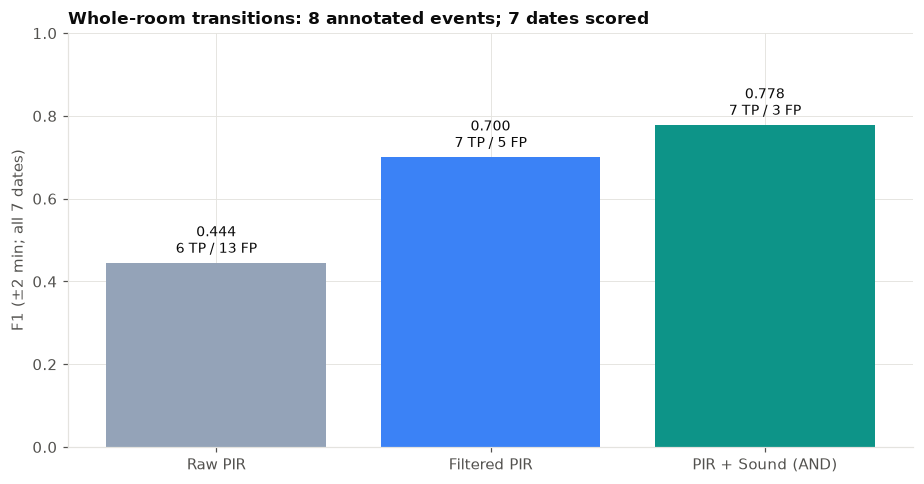

Final consistency: {'main_2min': {'TP': 7, 'FP': 3, 'FN': 1, 'Precision': 0.7, 'Recall': 0.875, 'F1': 0.7777777777777777, 'MedianErr_min': 0.5166666666666667, 'ConfirmLag_min': 15.0}, 'main_5min': {'TP': 8, 'FP': 2, 'FN': 0, 'Precision': 0.8, 'Recall': 1.0, 'F1': 0.888888888888889, 'MedianErr_min': 0.25833333333333336, 'ConfirmLag_min': 13.466666666666667}}


In [77]:
# Export a one-page summary table that can be pasted into the group poster.
poster=V6_PRIMARY[V6_PRIMARY.method.isin(['PIR','Fusion AND','Raw PIR (no persistence)']) & V6_PRIMARY.tolerance_min.isin([2,5])].copy()
poster=poster[['method','tolerance_min','n_predictions','TP','FP','FN','Precision','Recall','F1','ConfirmLag_min']]
poster.to_csv(OUT/'v6_poster_headline_table.csv',index=False)
fig,ax=plt.subplots(figsize=(8.5,4.5))
a=V6_PRIMARY[V6_PRIMARY.tolerance_min==2].set_index('method').loc[['Raw PIR (no persistence)','PIR','Fusion AND']]
bars=ax.bar(range(3),a.F1,color=['#94a3b8','#3b82f6','#0d9488'])
ax.set_xticks(range(3),['Raw PIR','Filtered PIR','PIR + Sound (AND)'])
ax.set_ylim(0,1); ax.set_ylabel('F1 (±2 min; all 7 dates)')
ax.set_title('Whole-room transitions: 8 annotated events; 7 dates scored')
for bar,row in zip(bars,a.itertuples()):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.025,f'{row.F1:.3f}\n{row.TP} TP / {row.FP} FP',ha='center',fontsize=9)
fig.tight_layout();fig.savefig(FIG/'fig7_v6_primary_methods_all_dates.png',dpi=200);plt.show()
print('Final consistency:',{'main_2min':match(det_loo_cau['Fusion AND'],T,2),'main_5min':match(det_loo_cau['Fusion AND'],T,5)})

## 5.12 Final group-integration handoff — Arash Ansarimehr

The joined K-Means states are **directly sourced from the supplied final Group 5 notebook**, not independently re-created. Section 5 is an **RQ2 supporting analysis** for the wider RQ3 interpretation of room states/anomalies. Anomaly observations supplied by Person 4 should be joined separately; none are invented here.

**Claims safe for poster:** 7/8 whole-room transitions detected within ±2 minutes; 3 false event alarms on 7 days; AND F1=.778 vs filtered PIR F1=.700; ±5-minute F1=.889; departure confirmations need ≥15 minutes; only 8 room-level events among 27 occupancy-count changes. Sensor responses are descriptive, and CO₂ is not an effective sharp event-clock under these rules. Confidence bounds are broad.

**Not safe to claim:** we detect every individual entering/leaving, measured sensor-caused lags, external generalisation, a verified annotation error, or proof the cluster link independently validates the detector.

Group poster ready metrics:


,method,tolerance_min,n_reference_room_events,dates_scored,TP,FP,FN,Precision,Recall,F1,ConfirmLag_min
0,Raw PIR (no persistence),2,8,7,6,13,2,0.316,0.750,0.444,7.750
1,Raw PIR (no persistence),5,8,7,7,12,1,0.368,0.875,0.519,11.933
2,PIR,2,8,7,7,5,1,0.583,0.875,0.700,15.500
3,PIR,5,8,7,8,4,0,0.667,1.000,0.800,13.717
4,Sound,2,8,7,5,39,3,0.114,0.625,0.192,15.000
5,Sound,5,8,7,5,39,3,0.114,0.625,0.192,15.000
6,CO2,2,8,7,1,140,7,0.007,0.125,0.013,0.500
7,CO2,5,8,7,3,138,5,0.021,0.375,0.040,4.083
8,Fusion AND,2,8,7,7,3,1,0.700,0.875,0.778,15.000
9,Fusion AND,5,8,7,8,2,0,0.800,1.000,0.889,13.467


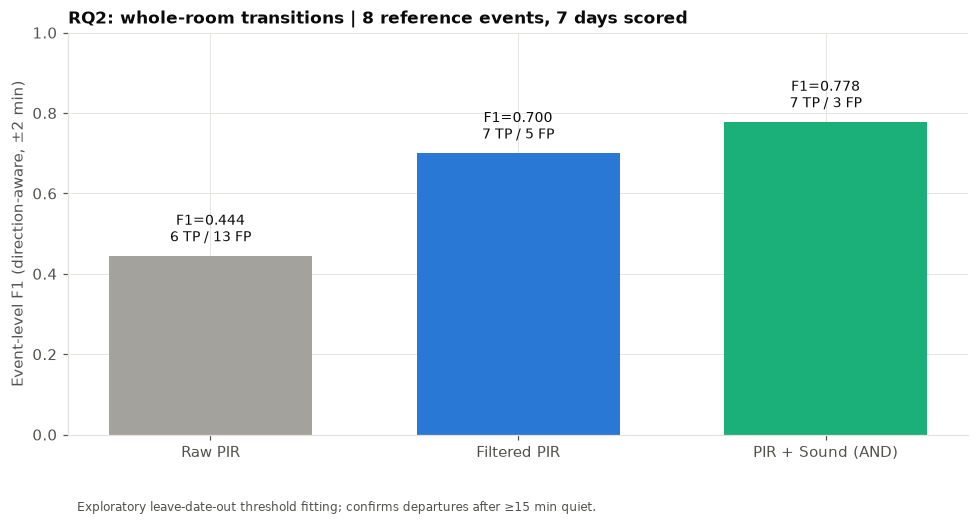

In [78]:
# Compact, fresh handoff exports: numbers below are recomputed from detections, not copied from markdown.
summary6=[]
for method in ['Raw PIR (no persistence)','PIR','Sound','CO2','Fusion AND']:
    predictions=raw_pir if method=='Raw PIR (no persistence)' else det_loo_cau[method]
    for tol in [2,5]:
        score=match(predictions,T,tol)
        summary6.append({'method':method,'tolerance_min':tol,
                         'n_reference_room_events':len(T),'dates_scored':len(ALL_DATES),
                         'n_predicted':len(predictions),**score})
HANDOFF6=pd.DataFrame(summary6)
HANDOFF6.to_csv(OUT/'v6_GROUP_POSTER_METRICS.csv',index=False)
print('Group poster ready metrics:')
display(HANDOFF6[['method','tolerance_min','n_reference_room_events','dates_scored','TP','FP','FN','Precision','Recall','F1','ConfirmLag_min']].round(3))
assert HANDOFF6.query('method=="Fusion AND" and tolerance_min==2').iloc[0][['TP','FP','FN']].tolist()==[7,3,1]
assert HANDOFF6.query('method=="PIR" and tolerance_min==2').iloc[0][['TP','FP','FN']].tolist()==[7,5,1]
assert HANDOFF6.query('method=="Fusion AND" and tolerance_min==5').iloc[0][['TP','FP','FN']].tolist()==[8,2,0]
fig, ax=plt.subplots(figsize=(9.0,4.9))
main=HANDOFF6.query('tolerance_min==2 and method in ["Raw PIR (no persistence)","PIR","Fusion AND"]').copy()
main=main.set_index('method').loc[['Raw PIR (no persistence)','PIR','Fusion AND']].reset_index()
colors=['#a3a29c','#2a78d6','#1baf7a']
bars=ax.bar(['Raw PIR','Filtered PIR','PIR + Sound (AND)'], main.F1, color=colors, width=.66)
for b,(_,r) in zip(bars,main.iterrows()):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()+.025,
            f"F1={r.F1:.3f}\n{int(r.TP)} TP / {int(r.FP)} FP",ha='center',va='bottom',fontsize=9)
ax.set_ylim(0,1);ax.set_ylabel('Event-level F1 (direction-aware, ±2 min)')
ax.set_title('RQ2: whole-room transitions | 8 reference events, 7 days scored')
ax.text(0.01,-.19,'Exploratory leave-date-out threshold fitting; confirms departures after ≥15 min quiet.',
        transform=ax.transAxes,fontsize=8,color='#52514e')
fig.tight_layout();fig.savefig(FIG/'v6_GROUP_POSTER_primary_methods.png',dpi=250,bbox_inches='tight');plt.show()

## 6. Synthesis and Overall Findings

This section follows the original Sections 1–5 and uses their executed
results. Run the notebook from the project directory with the supplied CSV
in `data/Occupancy_Estimation.csv`. The four investigations examine
aggregation, room-state interpretation, alternative representations, and
the integration of anomalies with clusters and events. Results and figures
are generated from the current run.

### Inputs from Sections 1–5

Check the shared window keys and state assignments before comparing results.
Occupancy labels are used for interpretation and evaluation. Where a name
was reused later in the notebook, the synthesis recovers the earlier result
using the available model, labels or original method.

In [100]:
from io import StringIO

from IPython.display import Markdown
from scipy.spatial.distance import cdist
from threadpoolctl import threadpool_limits

s6_window_key = ["segment", "win", "start"]
s6_anomaly_tail = TOP
s6_lof_neighbours = 20  # The neighbourhood used by Section 4.
s6_quality_gap_s = 65  # Section 4's after-gap quality threshold.
s6_kmeans_params = km_final.get_params()


def s6_window_numbers(timestamps, origin, minutes=WINDOW_MIN):
    """Use the same segment-relative binning as Section 1."""
    return ((timestamps - origin).dt.total_seconds() // (minutes * 60)).astype(int)


def s6_optimal_cluster_alignment(reference, candidate, n_clusters):
    """Map candidate IDs to reference IDs by maximum shared assignments."""
    reference = np.asarray(reference, dtype=int)
    candidate = np.asarray(candidate, dtype=int)
    if (reference.shape != candidate.shape
            or not np.isin(reference, np.arange(n_clusters)).all()
            or not np.isin(candidate, np.arange(n_clusters)).all()):
        raise ValueError("Cluster IDs and row alignment do not match the reference states.")
    overlap = np.bincount(
        n_clusters * reference + candidate, minlength=n_clusters ** 2
    ).reshape(n_clusters, n_clusters)
    reference_ids, candidate_ids = linear_sum_assignment(-overlap)
    mapping = np.empty(n_clusters, dtype=int)
    mapping[candidate_ids] = reference_ids
    return mapping


def s6_verify_handoff():
    """Key and check the surviving evidence without changing Sections 1–5."""
    baseline_windows = W_main.copy()
    window_ids = baseline_windows[s6_window_key]
    cluster_id_columns = s6_window_key + ["cluster", "cluster_name"]
    if window_ids.duplicated().any():
        raise ValueError("Section 2 produced duplicate window identities.")
    pd.testing.assert_frame_equal(
        baseline_windows[cluster_id_columns], W[cluster_id_columns])
    pd.testing.assert_frame_equal(
        baseline_windows[cluster_id_columns].reset_index(drop=True),
        cl[cluster_id_columns].reset_index(drop=True), check_dtype=False)

    # Reuse the original labels after independently checking the unkeyed row order.
    five_min, five_min_labels = make_windows(df, minutes=WINDOW_MIN)
    pd.testing.assert_frame_equal(
        baseline_windows[list(five_min.columns)], five_min)
    pd.testing.assert_frame_equal(W_lab, five_min_labels)
    label_windows = window_ids.join(W_lab, validate="one_to_one")
    one_min, _ = make_windows(df, minutes=1)

    for table in (A, A_pct, X_node, W_lab, Wflags):
        pd.testing.assert_index_equal(table.index, baseline_windows.index)
    if X_node.shape != (len(window_ids), len(NODE_FEATURES)):
        raise ValueError("Section 1's scaled matrix does not match the verified windows.")
    if not np.isfinite(A[["iso_global", *STATE_SCORES]].to_numpy()).all():
        raise ValueError("Section 4's anomaly scores contain missing or non-finite values.")

    reference_labels = baseline_windows["cluster"].to_numpy()
    np.testing.assert_array_equal(km_final.labels_, reference_labels)
    np.testing.assert_array_equal(km_final.predict(X_node.to_numpy()), reference_labels)
    np.testing.assert_array_equal(base, reference_labels)

    # Check the surviving ranks and votes, then keep Section 4's final flags.
    pd.testing.assert_series_equal(A["iso_global"].rank(pct=True), A_pct["iso_global"])
    pd.testing.assert_frame_equal(
        A[STATE_SCORES].groupby(W["cluster"]).rank(pct=True), A_pct[STATE_SCORES])
    state_votes = A_pct[STATE_SCORES].ge(1 - s6_anomaly_tail)
    votes_from_ranks = state_votes.sum(axis=1)
    pd.testing.assert_series_equal(
        votes_from_ranks, W["anomaly_votes"], check_names=False)
    pd.testing.assert_series_equal(
        votes_from_ranks.ge(2), W["anomaly"], check_names=False)
    pd.testing.assert_series_equal(
        A_pct["iso_global"].ge(1 - s6_anomaly_tail), global_flags, check_names=False)
    pd.testing.assert_series_equal(global_flags, glob)
    anomaly_windows = W.join(A.add_prefix("score_"), validate="one_to_one").assign(
        global_if_flag=global_flags,
        contextual_lof_flag=state_votes["lof"],
        centroid_flag=state_votes["centroid"],
        iso_state_flag=state_votes["iso_state"],
    )

    # Section 5 replaces X. Rebuild the Section 3 matrix from the in-memory
    # Section 1 features, including its CSV parser's numerical round trip.
    # StringIO supplies the string directly to pandas without reading a file.
    section3_windows = pd.read_csv(StringIO(five_min.to_csv(index=False)))
    verification_keys = section3_windows[s6_window_key].copy()
    verification_keys["start"] = pd.to_datetime(verification_keys["start"])
    pd.testing.assert_frame_equal(window_ids, verification_keys, check_dtype=False)
    section3_features = scale(section3_windows, cols)
    np.testing.assert_allclose(section3_features.to_numpy(), X_node.to_numpy(), atol=1e-12, rtol=1e-12)
    np.testing.assert_array_equal(gmm.predict(section3_features), lab_gmm)
    pd.testing.assert_frame_equal(scale(section3_windows, type_cols), X_type)
    if len(lab_type) != len(window_ids):
        raise ValueError("Section 3's sensor-type labels have the wrong number of rows.")
    gmm_alignment = s6_optimal_cluster_alignment(reference_labels, lab_gmm, K_FINAL)
    gmm_windows = window_ids.assign(gmm_component=lab_gmm, gmm_aligned=gmm_alignment[lab_gmm])

    # Section 4 overwrites res, but Section 3's variant labels, folds and eq
    # survive. Recreate its readouts and reduced-feature fold comparisons.
    np.testing.assert_array_equal(occupied, label_windows["occupied"])
    np.testing.assert_array_equal(empty, ~label_windows["occupied"])
    np.testing.assert_array_equal(daytime, section3_windows["hour"].between(7, 16))
    for positions, date in zip(FOLDS, sorted(section3_windows["date"].unique()), strict=True):
        np.testing.assert_array_equal(positions, np.flatnonzero(section3_windows["date"].ne(date)))
    ablation = {}
    for name, feature_groups in variants.items():
        variant_labels = labels[name]
        row = {
            "ARI": ARI(base, variant_labels),
            "occupancy_readout": readout(variant_labels, occupied),
            "daynight_readout": readout(variant_labels[empty], daytime[empty]),
        }
        if name != "all groups":
            features = pd.concat(
                [scale(section3_windows, groups[group]) for group in feature_groups], axis=1)
            fold_aris = [ARI(full_fold[i], refit(features, K, positions, i))
                         for i, positions in enumerate(FOLDS)]
            row.update(ARI_median=np.median(fold_aris), ARI_min=min(fold_aris), ARI_max=max(fold_aris))
        ablation[name] = row
    ablation_results = pd.DataFrame(ablation).T
    np.testing.assert_allclose(
        ablation_results.loc[[f"drop {group}" for group in eq.index], "ARI"],
        eq["unweighted ARI"], rtol=0, atol=0)

    # Check Section 5's in-memory event identity and its original match outputs.
    observed_starts = df.groupby("segment")["ts"].min()
    pd.testing.assert_series_equal(segment_starts, observed_starts)
    prior_count = df.groupby("segment")[LAB].shift()
    changed_presence = prior_count.notna() & prior_count.gt(0).ne(df[LAB].gt(0))
    pd.testing.assert_frame_equal(
        T[["ts", "segment"]].reset_index(drop=True),
        df.loc[changed_presence, ["ts", "segment"]].reset_index(drop=True),
    )
    np.testing.assert_array_equal(T["count_after"], df.loc[changed_presence, LAB])
    fusion = det_loo_cau["Fusion AND"].sort_values("detected_time")
    pd.testing.assert_frame_equal(
        events6[fusion.columns].reset_index(drop=True), fusion.reset_index(drop=True))
    reading_keys = pd.MultiIndex.from_frame(df[["segment", "ts"]])
    s5_estimate_keys = pd.MultiIndex.from_frame(events6[["segment", "detected_time"]])
    if not s5_estimate_keys.isin(reading_keys).all():
        raise ValueError("A Section 5 estimate has no original reading in the assigned segment.")
    for row in HANDOFF6.itertuples(index=False):
        estimates = raw_pir if row.method == "Raw PIR (no persistence)" else det_loo_cau[row.method]
        check = match(estimates, T, row.tolerance_min)
        if (row.n_reference_room_events != len(T)
                or row.n_predicted != len(estimates)
                or row.dates_scored != len(ALL_DATES)):
            raise ValueError("The Section 5 handoff denominators do not match the surviving events.")
        np.testing.assert_allclose(
            [row.TP, row.FP, row.FN, row.F1],
            [check["TP"], check["FP"], check["FN"], check["F1"]],
            rtol=0, atol=0,
        )

    return (baseline_windows, label_windows, anomaly_windows, gmm_windows,
            ablation_results, {1: one_min, WINDOW_MIN: five_min})


with threadpool_limits(limits=1):
    (s6_baseline_windows, s6_wlab, s6_anomaly_windows, s6_gmm_windows,
     s6_sensor_ablation_results, s6_window_tables) = s6_verify_handoff()

s6_sensor_ablation_weighting = eq.copy()
s6_active_clusters = s6_baseline_windows.loc[occ_state, "cluster"].unique()
print(f"Verified {len(s6_baseline_windows):,} keyed baseline windows and "
      f"{s6_anomaly_windows.anomaly.sum()} Section 4 consensus flags.")
print(f"Verified Section 3 GMM and ablation alignment, {len(T)} recorded room transitions, "
      f"and {len(events6)} Section 5 Fusion AND estimates.")

Verified 1,044 keyed baseline windows and 35 Section 4 consensus flags.
Verified Section 3 GMM and ablation alignment, 8 recorded room transitions, and 10 Section 5 Fusion AND estimates.


In [101]:
from pathlib import Path
from IPython.display import Markdown

s6_results = Path("data/results/section6")
s6_figures = Path("figures/section6")
s6_results.mkdir(parents=True, exist_ok=True)
s6_figures.mkdir(parents=True, exist_ok=True)

s6_synthesis = (
    s6_anomaly_windows.merge(s6_wlab, on=s6_window_key, validate="one_to_one")
    .merge(s6_gmm_windows, on=s6_window_key, validate="one_to_one")
)
pd.testing.assert_frame_equal(
    s6_synthesis[s6_window_key + ["cluster"]], s6_baseline_windows[s6_window_key + ["cluster"]]
)
s6_matrix = np.ascontiguousarray(X_node[NODE_FEATURES])
s6_reference_labels = s6_baseline_windows["cluster"].to_numpy(copy=True)
s6_cluster_ids = pd.Index(np.arange(km_final.n_clusters), name="cluster")
if s6_matrix.shape != (len(s6_synthesis), 24) or set(s6_reference_labels) != set(s6_cluster_ids):
    raise ValueError("Expected the fitted 24-feature, five-state baseline from Section 2.")
np.testing.assert_array_equal(km_final.predict(s6_matrix), s6_reference_labels)
print(f"Joined {len(s6_synthesis):,} windows across {len(s6_cluster_ids)} fitted states.")

Joined 1,044 windows across 5 fitted states.


### Investigation 1 — Sensitivity to temporal aggregation

Build one- and five-minute windows using Section 1's window builder and a
common 19-feature subset. Use temperature means, light means, sound means
and maxima, CO₂ excess, and both PIR fractions. Omit the four temperature
changes and the supplied rolling CO₂ slope. Apply Section 1's log transforms
and fit the standardiser to the retained five-minute windows for both fits.

Exclude five-minute windows whose readings span an acquisition gap longer
than 65 seconds. Keep one-minute windows nested within retained coarse bins.
Fit K-means independently at both resolutions and score provisional anomalies
with 300-tree global Isolation Forest and global LOF. The population-adjusted
LOF uses a larger fine-resolution neighbourhood so each resolution considers
a similar fraction of windows.

Compare labels and review flags through shared observed timestamps. The
additional restriction to eligible two-minute bins reproduces the earlier
comparison footprint. For each support, use inclusive 95th-percentile cutoffs
from the shared timestamps, taking the higher observed value at interpolation.
Report realised rates to show the effect of discrete scores and ties. These
provisional anomaly scores are specific to this investigation.

In [102]:
def s6_compare_resolutions(points):
    common_features = [name for name in NODE_FEATURES
                           if not name.endswith("_Temp_delta") and name != "CO2_slope_mean"]
    bin_key = ["segment", "win"]
    if len(common_features) != 19:
        raise ValueError("The resolution experiment requires the documented 19 features.")

    resolution_points = points[["segment", "ts"]].copy()
    resolution_points["acquisition_run"] = points.ts.diff().dt.total_seconds().gt(s6_quality_gap_s).cumsum()
    resolution_points["win_5"] = s6_window_numbers(points.ts, points.segment.map(segment_starts), WINDOW_MIN)
    for minutes in (1, 2):
        resolution_points[f"win_{minutes}"] = s6_window_numbers(
            resolution_points.ts, resolution_points.segment.map(segment_starts), minutes)

    coarse_runs = resolution_points.groupby(["segment", "win_5"]).acquisition_run.nunique()
    coarse_windows = s6_window_tables[WINDOW_MIN].join(coarse_runs.rename("runs"), on=bin_key)
    coarse_windows = coarse_windows.loc[coarse_windows.runs.eq(1)].reset_index(drop=True)
    fine_windows = s6_window_tables[1].assign(win_5=lambda table: table.win // WINDOW_MIN)
    fine_windows = fine_windows.merge(coarse_windows[bin_key].rename(columns={"win": "win_5"}),
                                      on=["segment", "win_5"], validate="many_to_one")
    coarse_scaled, fine_scaled = scale_features(coarse_windows, fine_windows, cols=common_features)
    resolution_matrices = {1: np.ascontiguousarray(fine_scaled), 5: np.ascontiguousarray(coarse_scaled)}
    proportional_neighbours = int(round(s6_lof_neighbours * len(fine_windows) / len(coarse_windows)))
    resolution_outputs = []
    for minutes, windows in [(1, fine_windows), (5, coarse_windows)]:
        matrix = resolution_matrices[minutes]
        partition = KMeans(**s6_kmeans_params).fit_predict(matrix)
        provisional_if = IsolationForest(n_estimators=300, max_samples="auto", random_state=RANDOM_SEED).fit(matrix)
        if_score = -provisional_if.score_samples(matrix)
        lof_score = -LocalOutlierFactor(n_neighbors=s6_lof_neighbours).fit(matrix).negative_outlier_factor_
        population_k = proportional_neighbours if minutes == 1 else s6_lof_neighbours
        proportional_score = (-LocalOutlierFactor(n_neighbors=population_k).fit(matrix).negative_outlier_factor_
                              if population_k != s6_lof_neighbours else lof_score)
        scores = {"IF": if_score, "LOF": lof_score, "population_LOF": proportional_score}
        window_result = windows[s6_window_key].assign(cluster=partition, population_LOF_k=population_k)
        resolution_outputs.append(window_result.assign(**{f"{name}_score": score for name, score in scores.items()}))

    score_columns = ["IF_score", "LOF_score", "population_LOF_score"]
    resolution_keys = [
        table[bin_key + ["cluster", *score_columns]].rename(
            columns={name: f"{name}_{minutes}" for name in ["win", "cluster", *score_columns]})
        for minutes, table in zip((1, 5), resolution_outputs)
    ]

    shared_points = resolution_points.merge(resolution_keys[0], on=["segment", "win_1"],
                                            validate="many_to_one")
    shared_points = shared_points.merge(resolution_keys[1], on=["segment", "win_5"],
                                        validate="many_to_one")
    retained_coarse_points = resolution_points.merge(resolution_keys[1][["segment", "win_5"]],
                                                     on=["segment", "win_5"], validate="many_to_one")
    two_minute_bins = retained_coarse_points.groupby(["segment", "win_2"]).agg(
        readings=("ts", "size"), runs=("acquisition_run", "nunique"))
    eligible_twos = two_minute_bins.loc[
        two_minute_bins.readings.ge(MIN_FILL * 2 * 2) & two_minute_bins.runs.eq(1)
    ]
    shared_with_twos = shared_points.join(eligible_twos, on=["segment", "win_2"], how="inner")


    def flag_jaccard(left, right):
        union = (left | right).sum()
        return (left & right).sum() / union if union else np.nan


    resolution_comparison = []
    resolution_thresholds = []
    for support, table in [("Shared 1- and 5-minute readings", shared_points),
                           ("Also eligible at 2 minutes", shared_with_twos)]:
        if table.empty or not table.ts.is_unique:
            raise ValueError(f"Expected unique shared observed timestamps for {support}.")
        overlap_scores = {}
        for column in score_columns:
            scores_1, scores_5 = table[f"{column}_1"], table[f"{column}_5"]
            threshold_1, threshold_5 = [
                series.quantile(1 - s6_anomaly_tail, interpolation="higher") for series in (scores_1, scores_5)
            ]
            resolution_thresholds.append({
                "support": support, "score": column, "threshold_1min": threshold_1, "threshold_5min": threshold_5,
                "flagged_readings_1min": int(scores_1.ge(threshold_1).sum()),
                "flagged_readings_5min": int(scores_5.ge(threshold_5).sum()),
                "flagged_fraction_1min": scores_1.ge(threshold_1).mean(),
                "flagged_fraction_5min": scores_5.ge(threshold_5).mean(),
            })
            overlap_scores[column.replace("_score", "_Jaccard")] = flag_jaccard(
                scores_1.ge(threshold_1), scores_5.ge(threshold_5))
        resolution_comparison.append({
            "support": support,
            "shared_readings": len(table),
            "cluster_ARI": adjusted_rand_score(table.cluster_1, table.cluster_5),
            **overlap_scores,
        })
    resolution_comparison = pd.DataFrame(resolution_comparison).set_index("support")
    resolution_thresholds = pd.DataFrame(resolution_thresholds)
    print(f"{len(fine_windows):,} one-minute and {len(coarse_windows):,} five-minute windows; "
          f"population-matched LOF uses {proportional_neighbours} fine and {s6_lof_neighbours} coarse neighbours.")
    display(resolution_comparison.round(3), resolution_thresholds.round(4))
    resolution_comparison.to_csv(s6_results / "resolution_sensitivity.csv")
    resolution_thresholds.to_csv(s6_results / "resolution_thresholds.csv", index=False)
    for minutes, table in zip((1, 5), resolution_outputs):
        table.to_csv(s6_results / f"resolution_{minutes}min.csv", index=False)
    return resolution_comparison, resolution_thresholds


with threadpool_limits(limits=1):
    s6_resolution, s6_resolution_thresholds = s6_compare_resolutions(df)

4,868 one-minute and 1,043 five-minute windows; population-matched LOF uses 93 fine and 20 coarse neighbours.


,shared_readings,cluster_ARI,IF_Jaccard,LOF_Jaccard,population_LOF_Jaccard
support,,,,,
Shared 1- and 5-minute readings,9736,0.855,0.452,0.124,0.433
Also eligible at 2 minutes,9072,0.854,0.443,0.120,0.421


,support,score,threshold_1min,threshold_5min,flagged_readings_1min,flagged_readings_5min,flagged_fraction_1min,flagged_fraction_5min
0,Shared 1- and 5-minute readings,IF_score,0.6184,0.6089,488,488,0.0501,0.0501
1,Shared 1- and 5-minute readings,LOF_score,1.3309,1.2949,488,492,0.0501,0.0505
2,Shared 1- and 5-minute readings,population_LOF_score,1.3316,1.2949,488,492,0.0501,0.0505
3,Also eligible at 2 minutes,IF_score,0.6183,0.6089,454,458,0.0500,0.0505
4,Also eligible at 2 minutes,LOF_score,1.3254,1.2949,454,458,0.0500,0.0505
5,Also eligible at 2 minutes,population_LOF_score,1.3302,1.2949,454,458,0.0500,0.0505


### Investigation 2 — Interpretation of discovered room states

Use Section 2's five fitted states. The sensor profiles show median raw
window features. A recorded presence means at least one positive count
inside the window. The head-count table uses the most frequent count.
The original state names accompany the cluster IDs as provenance.
They summarise sensor profiles and can disagree with recorded occupancy.

CO₂ excess is relative to the segment's fifth percentile. Examine the
provided rolling slope and the difference between the last and first raw
CO₂ readings in each C2 window. Look for a C2 start after each recorded
departure in the same uninterrupted acquisition run, splitting at gaps
longer than 65 seconds for this timing check.

In [103]:
def s6_describe_states(windows, points, recorded_transitions):
    keys = ["segment", "win"]
    profiles = windows.groupby("cluster").agg(
        state=("cluster_name", "first"),
        windows=("win", "size"),
        median_temp_C=("temp_mean", "median"),
        median_light_lux=("light_mean", "median"),
        median_sound_V=("sound_mean", "median"),
        median_PIR_fraction=("pir_frac", "median"),
        median_CO2_excess_ppm=("CO2_excess_mean", "median"),
        median_source_CO2_slope=("CO2_slope_mean", "median"),
        occupied_windows=("occupied", "sum"),
    )
    profiles["occupied_pct"] = 100 * profiles.occupied_windows / profiles.windows
    counts = pd.crosstab(windows.cluster, windows.occ_mode)

    reading_context = points[["segment", "ts", "S5_CO2"]].copy()
    reading_context["acquisition_run"] = points.ts.diff().dt.total_seconds().gt(s6_quality_gap_s).cumsum()
    reading_context["win"] = s6_window_numbers(points.ts, points.segment.map(segment_starts), WINDOW_MIN)
    bin_context = reading_context.groupby(keys).agg(
        observed_start=("ts", "min"),
        first_CO2=("S5_CO2", "first"),
        last_CO2=("S5_CO2", "last"),
        acquisition_run=("acquisition_run", "first"),
    )
    context = windows.join(bin_context, on=keys)
    np.testing.assert_array_equal(context.start, context.observed_start)
    c2 = context.loc[context.cluster.eq(2)].copy()
    c2["measured_CO2_change_ppm"] = c2.last_CO2 - c2.first_CO2
    summary = pd.Series({
        "windows": len(c2),
        "occupied_windows": c2.occupied.sum(),
        "negative_source_slope": c2.CO2_slope_mean.lt(0).sum(),
        "negative_measured_CO2_change": c2.measured_CO2_change_ppm.lt(0).sum(),
        "median_source_slope": c2.CO2_slope_mean.median(),
        "median_measured_CO2_change_ppm": c2.measured_CO2_change_ppm.median(),
        "median_CO2_excess_ppm": c2.CO2_excess_mean.median(),
    }, name="C2")
    run_key = ["segment", "acquisition_run"]
    starts = c2[run_key + ["start"]].sort_values("start")
    reading_runs = reading_context[run_key + ["ts"]]
    source_departures = {
        "Recorded transitions": recorded_transitions.loc[recorded_transitions.type.eq("departure"),
                                                         ["segment", "ts"]],
        "Fusion AND estimates": events6.loc[events6.event_type.eq("departure"), ["segment", "detected_time"]]
        .rename(columns={"detected_time": "ts"}),
    }
    timing = []
    next_start_rows = []
    for source, events in source_departures.items():
        departures = events.merge(reading_runs, on=["segment", "ts"], how="left", validate="many_to_one")
        if departures.acquisition_run.isna().any():
            raise ValueError(f"{source} include a timestamp outside the raw readings.")
        departures = departures.rename(columns={"ts": "event_time"}).sort_values("event_time")
        prior = pd.merge_asof(starts, departures, by=run_key, left_on="start", right_on="event_time",
                              direction="backward")
        elapsed = (prior.start - prior.event_time).dt.total_seconds() / 60
        timing.append({"departure_source": source, "C2_windows": len(starts),
                       "C2_within_15min": elapsed.le(15).sum(), "C2_within_60min": elapsed.le(60).sum(),
                       "C2_without_prior_departure_in_run": elapsed.isna().sum()})
        next_start = pd.merge_asof(departures, starts, by=run_key, left_on="event_time", right_on="start",
                                   direction="forward")
        next_start["minutes_to_C2_start"] = (next_start.start - next_start.event_time).dt.total_seconds() / 60
        next_start_rows.append(next_start.assign(departure_source=source))
    return profiles, counts, summary, pd.DataFrame(timing).set_index("departure_source"), pd.concat(next_start_rows)


s6_state_profiles, s6_headcounts, s6_c2_summary, s6_c2_timing, s6_next_c2 = s6_describe_states(s6_synthesis, df, T)
display(s6_state_profiles.round(3), s6_headcounts, s6_c2_summary.round(3).to_frame(),
        s6_c2_timing, s6_next_c2.round(2))
s6_state_profiles.to_csv(s6_results / "room_state_profiles.csv")
s6_headcounts.to_csv(s6_results / "room_state_headcounts.csv")
s6_c2_summary.to_csv(s6_results / "C2_CO2_profile.csv")
s6_c2_timing.to_csv(s6_results / "C2_departure_timing.csv")
s6_next_c2.to_csv(s6_results / "C2_first_start_after_departure.csv", index=False)

/var/folders/0h/47l1qjhn3ljfnsz7_cjvrv4m0000gn/T/ipykernel_28629/1920774574.py:70: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  s6_c2_timing, s6_next_c2.round(2))


,state,windows,median_temp_C,median_light_lux,median_sound_V,median_PIR_fraction,median_CO2_excess_ppm,median_source_CO2_slope,occupied_windows,occupied_pct
cluster,,,,,,,,,,
0,"Busy: high light, CO₂ rising",82,26.178,141.106,0.643,0.575,492.500,1.674,82,100.000
1,Empty: dark (night),545,25.284,0.000,0.065,0.000,5.000,0.000,0,0.000
2,"Recently vacated: dark, CO₂ falling",88,25.858,0.000,0.062,0.000,380.389,-2.119,0,0.000
3,Empty: daylight only,216,25.096,20.267,0.071,0.000,5.000,0.000,6,2.778
4,Occupied: moderate activity,113,25.930,69.875,0.259,0.278,205.000,0.796,110,97.345


occ_mode,0,1,2,3
cluster,,,,
0,2,1,36,43
1,545,0,0,0
2,88,0,0,0
3,210,6,0,0
4,5,41,38,29


,C2
windows,88.000
occupied_windows,0.000
negative_source_slope,82.000
negative_measured_CO2_change,84.000
median_source_slope,-2.119
median_measured_CO2_change_ppm,-20.000
median_CO2_excess_ppm,380.389


,C2_windows,C2_within_15min,C2_within_60min,C2_without_prior_departure_in_run
departure_source,,,,
Recorded transitions,88,15,57,0
Fusion AND estimates,88,13,47,26


,segment,event_time,acquisition_run,start,minutes_to_C2_start,departure_source
0,1,2017-12-22 14:15:58,2,2017-12-22 14:18:31,2.55,Recorded transitions
1,1,2017-12-22 19:39:40,5,2017-12-22 19:43:14,3.57,Recorded transitions
2,1,2017-12-23 14:10:11,5,2017-12-23 14:13:15,3.07,Recorded transitions
3,1,2017-12-23 19:52:16,6,2017-12-23 19:53:18,1.03,Recorded transitions
4,3,2018-01-10 17:57:27,8,2018-01-10 18:01:01,3.57,Recorded transitions
0,1,2017-12-22 14:16:59,2,2017-12-22 14:18:31,1.53,Fusion AND estimates
1,1,2017-12-22 19:36:36,4,NaT,NaN,Fusion AND estimates
2,1,2017-12-23 14:10:42,5,2017-12-23 14:13:15,2.55,Fusion AND estimates
3,1,2017-12-23 14:44:54,5,2017-12-23 14:53:04,8.17,Fusion AND estimates
4,1,2017-12-23 19:52:47,6,2017-12-23 19:53:18,0.52,Fusion AND estimates


The falling-CO₂ profile is compatible with residual elevated CO₂ after
people leave. The recorded departures and the time of the next C2 window
show how often this occurs in the recording. The fraction of all C2 windows
close to a departure indicates how specific that interpretation is.
Ventilation, mixing, the choice of segment baseline and the averaging
period affect the same measures. The dataset has no direct ventilation
or air-exchange measurement.

### Investigation 3 — Alternative representations of room behaviour

Compare the fitted Section 3 GMM with the fitted Section 2 K-means
partition. A one-to-one assignment maximises the row matches. Inspect
which states split between mixture components. The adjusted Rand index
compares memberships independently of labels. The sensor ablations give
additional context about which feature groups shape the original partition.

In [104]:
def s6_compare_representations(windows, ablation, weighting):
    table = pd.crosstab(windows.cluster, windows.gmm_aligned).reindex(
        index=s6_cluster_ids, columns=s6_cluster_ids, fill_value=0)
    agreement = windows.cluster.eq(windows.gmm_aligned)
    partition = pd.DataFrame({
        "ARI vs 24-feature K-means": [
            adjusted_rand_score(windows.cluster, windows.gmm_aligned),
            adjusted_rand_score(windows.cluster, lab_type),
        ],
        "Aligned agreement (%)": [100 * agreement.mean(), np.nan],
    }, index=["24-feature GMM", "8-feature K-means"])
    disagreement = windows.assign(agrees=agreement).groupby("cluster").agrees.agg(["size", "sum", "mean"])
    disagreement.columns = ["windows", "GMM_agrees", "GMM_agreement_fraction"]
    disagreement["GMM_disagrees"] = disagreement.windows - disagreement.GMM_agrees
    ablation = ablation.loc[["all groups", *[f"drop {group}" for group in FEATURE_GROUPS]]].assign(
        equal_weight_ARI=weighting["equal-weight ARI"].rename(index=lambda group: f"drop {group}"))
    return partition, table, disagreement, ablation


s6_method_comparison, s6_gmm_comparison, s6_gmm_disagreement, s6_ablation = s6_compare_representations(
    s6_synthesis, s6_sensor_ablation_results, s6_sensor_ablation_weighting)
display(s6_method_comparison.round(3), s6_gmm_comparison, s6_gmm_disagreement.round(3), s6_ablation.round(3))
s6_method_comparison.to_csv(s6_results / "clustering_comparison.csv")
s6_gmm_comparison.to_csv(s6_results / "gmm_aligned_crosstab.csv")
s6_gmm_disagreement.to_csv(s6_results / "gmm_disagreements.csv")
s6_ablation.to_csv(s6_results / "sensor_ablation.csv")

,ARI vs 24-feature K-means,Aligned agreement (%)
24-feature GMM,0.762,88.697
8-feature K-means,0.881,NaN


cluster,0,1,2,3,4
cluster,,,,,
0,82,0,0,0,0
1,0,468,41,32,4
2,0,0,88,0,0
3,0,0,0,208,8
4,33,0,0,0,80


,windows,GMM_agrees,GMM_agreement_fraction,GMM_disagrees
cluster,,,,
0,82,82,1.000,0
1,545,468,0.859,77
2,88,88,1.000,0
3,216,208,0.963,8
4,113,80,0.708,33


,ARI,occupancy_readout,daynight_readout,ARI_median,ARI_min,ARI_max,equal_weight_ARI
all groups,1.000,0.991,0.954,NaN,NaN,NaN,NaN
drop temperature,0.890,0.984,0.973,0.798,0.756,0.891,0.935
drop light,0.389,0.982,0.704,0.376,0.273,0.554,0.560
drop sound,0.895,0.954,0.980,0.902,0.852,0.923,0.968
drop co2,0.832,0.969,0.983,0.828,0.571,0.903,0.794
drop motion,0.972,0.988,0.959,0.977,0.968,0.993,0.965


#### Self-organising map and within-state variation

Fit the original exploratory 4 × 4 self-organising map (SOM) on Section 2's
24 standardised features. Initialise its 16 prototypes with sampled windows
and update them using a Gaussian grid neighbourhood. The 12,000 updates use
seed 42. The learning rate and radius decrease geometrically from
0.30 to 0.03 and from 2.0 to 0.4 grid units. Assign each window to its nearest
prototype by Euclidean distance and use that distance as its quantisation error.

The upper tail of the pooled quantisation-error ranks (percentile rank ≥ 0.95)
marks windows for SOM review. For comparison, fit the historical investigation's
300-tree global Isolation Forest and 20-neighbour global LOF on the same matrix
and use the same percentile rule. The SOM-only group has a high SOM review score
and neither comparison flag. The low-error detector group has at least one
comparison flag and error at or below the overall median. These diagnostics
are separate from Section 4's authoritative anomaly flags.

The gap between the nearest two K-means centres is expressed as a fraction of
the larger distance. A topographic miss means the two nearest SOM nodes are
farther apart than one grid step by Manhattan distance. Occupancy labels
summarise the map after fitting. Grid locations describe sensor-pattern
similarity, and medians for nodes with few windows are descriptive.

In [105]:
from scipy.spatial.distance import cdist
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor


def s6_som_diagnostics(windows, matrix, centres, window_key, cluster_ids, seed):
    """Fit the original 4 × 4 SOM and calculate its within-state diagnostics."""
    side = 4
    steps = 12_000
    rng = np.random.default_rng(seed)
    grid = np.indices((side, side)).reshape(2, -1).T
    prototypes = matrix[rng.choice(len(matrix), len(grid), replace=False)].copy()
    grid_distances_sq = cdist(grid, grid, metric="sqeuclidean")
    for row, rate, radius in zip(
        rng.integers(len(matrix), size=steps),
        np.geomspace(0.30, 0.03, steps),
        np.geomspace(2.0, 0.4, steps),
    ):
        delta = matrix[row] - prototypes
        winner = np.argmin((delta ** 2).sum(axis=1))
        weights = rate * np.exp(-grid_distances_sq[winner] / (2 * radius ** 2))
        prototypes += weights[:, None] * delta

    distances = cdist(matrix, prototypes)
    nearest = distances.argsort(axis=1, kind="stable")[:, :2]
    nodes = np.array([f"R{row + 1}C{column + 1}" for row, column in grid])
    centre_distances = cdist(matrix, centres)
    centre_order = centre_distances.argsort(axis=1, kind="stable")[:, :2]
    closest, runner_up = np.take_along_axis(centre_distances, centre_order, axis=1).T
    margin = np.divide(
        runner_up - closest, runner_up, out=np.zeros(len(matrix)), where=runner_up > 0
    )

    scores = windows[window_key + [
        "cluster", "gmm_aligned", "occupied", "temp_mean", "light_mean", "sound_mean",
        "pir_frac", "CO2_excess_mean", "CO2_slope_mean",
    ]].assign(
        node=nodes[nearest[:, 0]],
        som_qe=distances.min(axis=1),
        other_k=centre_order[:, 1],
        k_margin=margin,
        topographic_miss=np.abs(grid[nearest[:, 0]] - grid[nearest[:, 1]]).sum(axis=1) > 1,
    )
    scores["disagrees"] = scores["cluster"].ne(scores["gmm_aligned"])
    scores["if_score"] = -IsolationForest(n_estimators=300, random_state=seed).fit(matrix).score_samples(matrix)
    scores["lof_score"] = -LocalOutlierFactor(n_neighbors=20).fit(matrix).negative_outlier_factor_
    for score, flag in (("som_qe", "som_review"), ("if_score", "if_flag"), ("lof_score", "lof_flag")):
        scores[flag] = scores[score].rank(method="average", pct=True).ge(0.95)
    detector_review = scores["if_flag"] | scores["lof_flag"]
    scores["som_only"] = scores["som_review"] & ~detector_review
    scores["detector_flag_with_low_qe"] = detector_review & scores["som_qe"].le(scores["som_qe"].median())

    distribution = pd.crosstab(scores["node"], scores["cluster"]).reindex(
        index=nodes, columns=cluster_ids, fill_value=0
    )
    distribution.index.name = "node"
    distribution.columns.name = "cluster"
    shares = distribution.div(distribution.sum(axis=0), axis=1)
    node_profiles = scores.groupby("node").agg(
        windows=("node", "size"),
        occupied_windows=("occupied", "sum"),
        occupancy_rate=("occupied", "mean"),
        temperature_C=("temp_mean", "median"),
        light_lux=("light_mean", "median"),
        sound_V=("sound_mean", "median"),
        PIR_fraction=("pir_frac", "median"),
        CO2_excess_ppm=("CO2_excess_mean", "median"),
        CO2_slope=("CO2_slope_mean", "median"),
        median_qe=("som_qe", "median"),
    ).reindex(nodes)
    node_profiles[["windows", "occupied_windows"]] = (
        node_profiles[["windows", "occupied_windows"]].fillna(0).astype(int)
    )
    state_nodes = scores.groupby(["cluster", "node"]).agg(
        windows=("node", "size"),
        CO2_excess_q25=("CO2_excess_mean", lambda col: col.quantile(0.25)),
        CO2_excess_ppm=("CO2_excess_mean", "median"),
        CO2_excess_q75=("CO2_excess_mean", lambda col: col.quantile(0.75)),
        CO2_slope=("CO2_slope_mean", "median"),
        occupancy_rate=("occupied", "mean"),
    )
    state_nodes["share_of_state"] = state_nodes["windows"].div(state_nodes.groupby("cluster")["windows"].transform("sum"))
    disagreement = scores.groupby("disagrees").agg(
        windows=("som_qe", "size"),
        median_qe=("som_qe", "median"),
        reviewed=("som_review", "sum"),
        review_rate=("som_review", "mean"),
        median_k_margin=("k_margin", "median"),
        topographic_misses=("topographic_miss", "sum"),
        topographic_miss_rate=("topographic_miss", "mean"),
    )
    overlap_rows = []
    for method, flag in [
        ("GMM disagreement", "disagrees"),
        ("Provisional global IF", "if_flag"),
        ("Provisional global LOF", "lof_flag"),
    ]:
        intersection = (scores["som_review"] & scores[flag]).sum()
        union = (scores["som_review"] | scores[flag]).sum()
        overlap_rows.append({
            "comparison": method, "SOM_review": scores["som_review"].sum(),
            "comparison_windows": scores[flag].sum(), "intersection": intersection,
            "union": union, "jaccard": intersection / union,
        })

    review_cases = scores.loc[scores["som_only"] | scores["detector_flag_with_low_qe"]]
    return {
        "grid": grid,
        "scores": scores,
        "node_profiles": node_profiles,
        "counts": distribution,
        "shares": shares,
        "state_nodes": state_nodes,
        "disagreement": disagreement,
        "overlap": pd.DataFrame(overlap_rows).set_index("comparison"),
        "review_cases": review_cases,
    }


s6_som = s6_som_diagnostics(
    s6_synthesis, np.asarray(s6_matrix), km_final.cluster_centers_,
    s6_window_key, s6_cluster_ids, RANDOM_SEED,
)

print(f"Mean quantisation error: {s6_som['scores']['som_qe'].mean():.3f} in standardised feature space.")
print(f"Populated nodes: {s6_som['node_profiles']['windows'].gt(0).sum()} of {len(s6_som['grid'])}.")
print(
    f"SOM-only review: {s6_som['scores']['som_only'].sum()} windows. "
    f"Detector flag with low SOM error: {s6_som['scores']['detector_flag_with_low_qe'].sum()} windows."
)
display(s6_som["counts"], s6_som["node_profiles"].round(3))
display(s6_som["state_nodes"].round(3))
display(s6_som["disagreement"].round(3), s6_som["overlap"].round(3))
display(s6_som["review_cases"].sort_values("som_qe", ascending=False).head(8).round(3))

for s6_som_table in ["scores", "node_profiles", "counts", "shares", "state_nodes", "disagreement", "overlap", "review_cases"]:
    s6_som[s6_som_table].to_csv(
        s6_results / f"som_{s6_som_table}.csv", index=s6_som_table not in {"scores", "review_cases"}
    )

Mean quantisation error: 2.122 in standardised feature space.
Populated nodes: 15 of 16.
SOM-only review: 15 windows. Detector flag with low SOM error: 17 windows.


cluster,0,1,2,3,4
node,,,,,
R1C1,72,0,0,0,1
R1C2,10,0,0,0,25
R1C3,0,0,24,1,14
R1C4,0,0,45,0,0
R2C1,0,0,0,0,36
R2C2,0,0,0,3,37
R2C3,0,10,0,4,0
R2C4,0,28,19,0,0
R3C1,0,0,0,90,0


,windows,occupied_windows,occupancy_rate,temperature_C,light_lux,sound_V,PIR_fraction,CO2_excess_ppm,CO2_slope,median_qe
node,,,,,,,,,,
R1C1,73,73,1.000,26.216,142.500,0.633,0.600,505.500,1.646,4.388
R1C2,35,35,1.000,25.958,134.725,0.449,0.400,205.000,1.545,4.666
R1C3,39,12,0.308,26.113,43.375,0.075,0.000,264.444,-1.210,2.874
R1C4,45,0,0.000,25.844,0.000,0.061,0.000,470.000,-2.242,2.026
R2C1,36,36,1.000,25.910,79.375,0.263,0.500,362.750,2.028,4.046
R2C2,40,40,1.000,25.926,64.975,0.212,0.194,88.500,0.270,3.201
R2C3,14,0,0.000,25.574,3.125,0.073,0.000,0.000,0.000,1.809
R2C4,47,0,0.000,25.574,0.000,0.062,0.000,164.500,-1.802,1.647
R3C1,90,2,0.022,25.404,34.908,0.073,0.000,5.000,0.000,1.767


windows  CO2_excess_q25  CO2_excess_ppm  CO2_excess_q75  CO2_slope  occupancy_rate  share_of_state
cluster node                                                                                                    
0       R1C1       72         391.472         504.750         672.250      1.659           1.000           0.878
        R1C2       10         180.750         216.250         414.594      2.141           1.000           0.122
1       R2C3       10           0.000           0.000           0.000      0.000           0.000           0.018
        R2C4       28          87.542         130.833         163.500     -1.508           0.000           0.051
        R3C3      154           5.000           5.000          12.500      0.000           0.000           0.283
        R3C4       92           5.000           5.000          15.000      0.000           0.000           0.169
        R4C1        1           0.000           0.000           0.000      0.000           0.000           0.002
        R4C2       26           0.000           0.000           0.000      0.000           0.000           0.048
        R4C3      163           0.000           3.000           5.000      0.000           0.000           0.299
        R4C4       71           2.639           5.000          18.000      0.000           0.000           0.130
2       R1C3       24         223.375         293.000         417.278     -1.989           0.000           0.273
        R1C4       45         400.500         470.000         583.889     -2.242           0.000           0.511
        R2C4       19         209.083         253.500         325.500     -2.024           0.000           0.216
3       R1C3        1         238.889         238.889         238.889      1.418           1.000           0.005
        R2C2        3          23.000          35.000          42.500      0.855           1.000           0.014
        R2C3        4           0.000           0.250           0.625     -0.039           0.000           0.019
        R3C1       90           5.000           5.000           5.000      0.000           0.022           0.417
        R4C1       89           0.000           4.500           5.000      0.000           0.000           0.412
        R4C2       29           0.000           0.000           2.778      0.000           0.000           0.134
4       R1C1        1         667.500         667.500         667.500      0.290           1.000           0.009
        R1C2       25          92.500         143.500         254.000      1.262           1.000           0.221
        R1C3       14         164.625         232.750         262.833     -0.337           0.786           0.124
        R2C1       36         166.500         362.750         519.028      2.028           1.000           0.319
        R2C2       37          16.667         112.500         210.500      0.260           1.000           0.327

,windows,median_qe,reviewed,review_rate,median_k_margin,topographic_misses,topographic_miss_rate
disagrees,,,,,,,
False,926,1.762,48,0.052,0.471,198,0.214
True,118,2.042,5,0.042,0.237,67,0.568


,SOM_review,comparison_windows,intersection,union,jaccard
comparison,,,,,
GMM disagreement,53,118,5,166,0.030
Provisional global IF,53,53,37,69,0.536
Provisional global LOF,53,53,7,99,0.071


/var/folders/0h/47l1qjhn3ljfnsz7_cjvrv4m0000gn/T/ipykernel_28629/2248840094.py:134: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(s6_som["review_cases"].sort_values("som_qe", ascending=False).head(8).round(3))


,segment,win,start,cluster,gmm_aligned,occupied,temp_mean,light_mean,sound_mean,pir_frac,...,k_margin,topographic_miss,disagrees,if_score,lof_score,som_review,if_flag,lof_flag,som_only,detector_flag_with_low_qe
78,1,57,2017-12-22 17:53:28,0,0,True,26.406,142.844,0.487,0.812,...,0.221,False,False,0.567,1.296,True,False,False,True,False
844,3,11,2018-01-10 16:20:56,4,4,True,25.849,14.950,0.375,0.200,...,0.298,False,False,0.589,1.387,True,False,False,True,False
28,1,7,2017-12-22 13:43:17,0,0,True,26.362,191.700,0.394,0.650,...,0.169,False,False,0.586,1.188,True,False,False,True,False
383,1,365,2017-12-23 19:33:23,4,0,True,26.141,80.000,0.365,0.050,...,0.042,False,True,0.578,1.066,True,False,False,True,False
17,0,18,2017-12-22 12:20:03,4,4,True,26.259,135.139,0.308,0.333,...,0.370,False,False,0.572,1.292,True,False,False,True,False
24,1,3,2017-12-22 13:23:22,4,0,True,26.454,189.150,0.289,0.550,...,0.252,True,True,0.577,1.168,True,False,False,True,False
358,1,340,2017-12-23 17:28:17,0,0,True,26.023,83.400,0.586,0.000,...,0.101,False,False,0.567,1.017,True,False,False,True,False
1,0,1,2017-12-22 10:54:47,4,4,True,25.013,64.775,0.241,0.450,...,0.106,False,False,0.581,1.148,True,False,False,True,False


GMM and K-means disagreements have limited overlap with high SOM quantisation
error. Review scores identify observations far from their nearest SOM
prototype. The alignment table in this investigation and the centre-margin
diagnostic describe uncertainty between cluster assignments.

Read the CO₂ summaries within each K-means state. The high-activity state has
distinct high- and lower-CO₂ prototype assignments. The elevated, falling-CO₂
state spans multiple nodes with differing levels of residual CO₂. These are
descriptive differences in the original five-state solution, and the SOM
shares the same CO₂ features used in that solution.

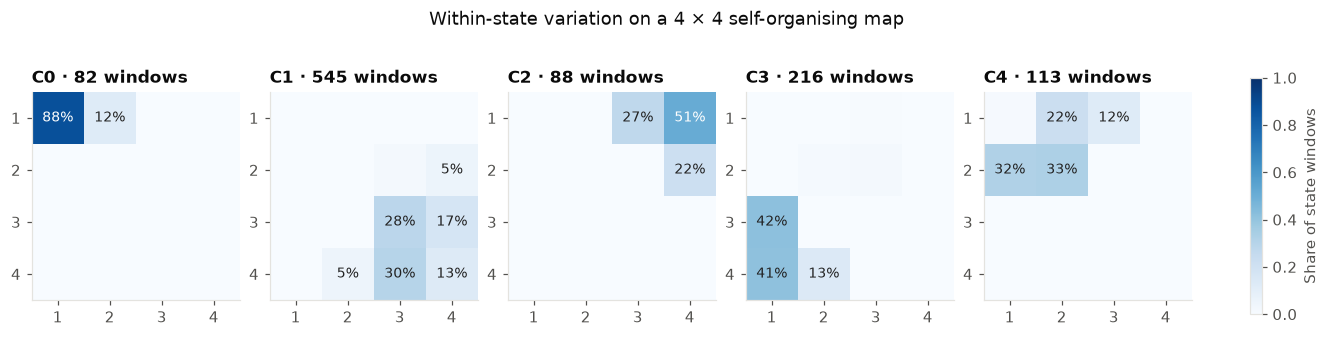

In [106]:
def s6_plot_som(som, cluster_ids, figure_path):
    side = int(np.sqrt(len(som["grid"])))
    fig, axes = plt.subplots(1, len(cluster_ids), figsize=(12, 3.2), layout="constrained")
    for cluster, ax in zip(cluster_ids, axes):
        shares = som["shares"][cluster].to_numpy().reshape(side, side)
        image = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
        count = som["counts"][cluster].sum()
        ax.set_title(f"C{cluster} · {count} windows")
        ax.set_xticks(range(side), range(1, side + 1))
        ax.set_yticks(range(side), range(1, side + 1))
        ax.grid(False)
        for (row, column), share in np.ndenumerate(shares):
            if share >= 0.025:
                ax.text(column, row, f"{share:.0%}", ha="center", va="center",
                        color="white" if share > 0.5 else "#222222", fontsize=9)
    fig.colorbar(image, ax=axes, shrink=0.75, label="Share of state windows")
    fig.suptitle("Within-state variation on a 4 × 4 self-organising map")
    fig.savefig(figure_path / "som_state_overlay.png", dpi=200)
    plt.show()


s6_plot_som(s6_som, s6_cluster_ids, s6_figures)

### Investigation 4 — Clustering, anomalies and events

#### Global and within-state anomaly flags

We compare the flags already produced by Section 4. Global Isolation Forest
ranks all eligible windows together. The three contextual flags use
within-state ranks, and the Section 4 consensus requires at least two of those
votes. The flagged percentage for each state uses that state's window count
as its denominator. Pairwise Jaccard similarity divides the shared count by
the number flagged by either method. These overlaps describe detector agreement
on the same readings.

,windows,Global IF,Contextual LOF,Centroid distance,Within-state IF,Consensus,Global IF (%),Contextual LOF (%),Centroid distance (%),Within-state IF (%),Consensus (%)
cluster,,,,,,,,,,,
0,82,42,5,5,5,5,51.22,6.10,6.10,6.10,6.10
1,545,0,28,28,28,14,0.00,5.14,5.14,5.14,2.57
2,88,0,5,5,5,1,0.00,5.68,5.68,5.68,1.14
3,216,0,11,11,11,9,0.00,5.09,5.09,5.09,4.17
4,113,11,6,6,6,6,9.73,5.31,5.31,5.31,5.31


,detector_a,detector_b,both,a_only,b_only,either,jaccard
0,Global IF,Contextual LOF,9,44,46,99,0.091
1,Global IF,Centroid distance,10,43,45,98,0.102
2,Global IF,Within-state IF,10,43,45,98,0.102
3,Global IF,Consensus,10,43,25,78,0.128
4,Contextual LOF,Centroid distance,21,34,34,89,0.236
5,Contextual LOF,Within-state IF,17,38,38,93,0.183
6,Contextual LOF,Consensus,29,26,6,61,0.475
7,Centroid distance,Within-state IF,15,40,40,95,0.158
8,Centroid distance,Consensus,27,28,8,63,0.429
9,Within-state IF,Consensus,23,32,12,67,0.343


,score_iso_global,score_lof,score_centroid,score_iso_state
score_iso_global,1.00,0.20,0.42,0.73
score_lof,0.20,1.00,0.57,0.50
score_centroid,0.42,0.57,1.00,0.66
score_iso_state,0.73,0.50,0.66,1.00


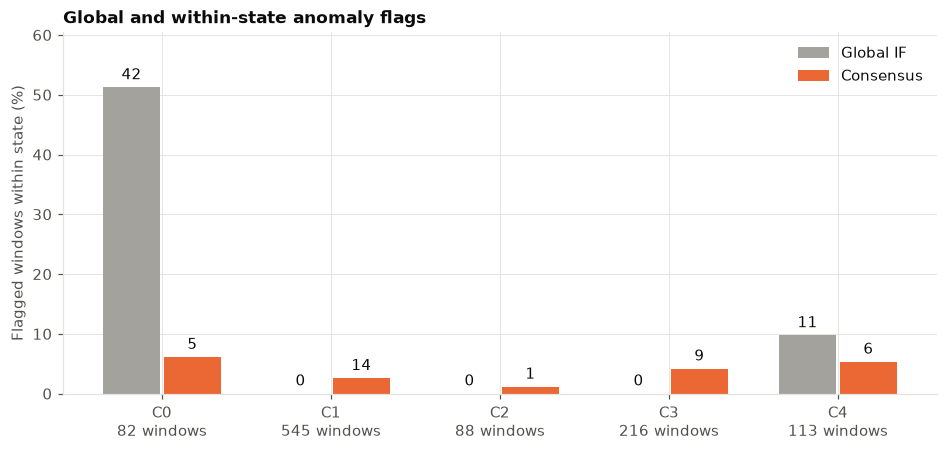

In [107]:
from itertools import combinations as s6_combinations
from types import SimpleNamespace as s6_Namespace


def s6_compare_detectors(windows, cluster_ids, window_key, results_dir, figures_dir):
    detectors = {
        "Global IF": "global_if_flag",
        "Contextual LOF": "contextual_lof_flag",
        "Centroid distance": "centroid_flag",
        "Within-state IF": "iso_state_flag",
        "Consensus": "anomaly",
    }
    votes = windows[list(detectors.values())].rename(columns={v: k for k, v in detectors.items()})
    counts = votes.groupby(windows.cluster).sum().reindex(cluster_ids)
    counts.insert(0, "windows", windows.groupby("cluster").size().reindex(cluster_ids))
    for detector in detectors:
        counts[f"{detector} (%)"] = 100 * counts[detector] / counts.windows

    pairwise = []
    for left, right in s6_combinations(detectors, 2):
        both = int((votes[left] & votes[right]).sum())
        either = int((votes[left] | votes[right]).sum())
        pairwise.append({
            "detector_a": left, "detector_b": right, "both": both,
            "a_only": int(votes[left].sum()) - both, "b_only": int(votes[right].sum()) - both,
            "either": either, "jaccard": both / either if either else np.nan,
        })
    overlap = pd.DataFrame(pairwise)
    scores = ["score_iso_global", "score_lof", "score_centroid", "score_iso_state"]
    score_correlations = windows[scores].corr(method="spearman")
    display(counts.round(2), overlap.round(3), score_correlations.round(2))
    counts.to_csv(results_dir / "anomaly_by_state.csv")
    overlap.to_csv(results_dir / "anomaly_detector_overlap.csv", index=False)
    score_correlations.to_csv(results_dir / "anomaly_score_correlations.csv")
    windows[window_key + ["cluster", *detectors.values(), "anomaly_votes", *scores,
                          "anomaly_category", "anomaly_drivers"]].to_csv(
        results_dir / "window_anomaly_flags.csv", index=False)

    fig, ax = plt.subplots(figsize=(8.5, 4.0), layout="constrained")
    for offset, detector, color in [(-0.18, "Global IF", C_GREY), (0.18, "Consensus", C_ORANGE)]:
        bars = ax.bar(cluster_ids + offset, counts[f"{detector} (%)"], width=0.34,
                      color=color, label=detector)
        ax.bar_label(bars, labels=counts[detector].astype(str), padding=3)
    ax.set_xticks(cluster_ids, [f"C{cluster}\n{n} windows" for cluster, n in counts.windows.items()])
    ax.set_ylabel("Flagged windows within state (%)")
    ax.set_title("Global and within-state anomaly flags")
    ax.margins(y=0.18)
    ax.legend()
    fig.savefig(figures_dir / "anomaly_by_state.png")
    plt.show()
    return s6_Namespace(anomaly_by_state=counts, anomaly_overlap=overlap,
                        score_correlations=score_correlations)


s6_integration = s6_compare_detectors(s6_synthesis, s6_cluster_ids, s6_window_key,
                                      s6_results, s6_figures)

#### Sensitivity to anomaly-selected deletion

For each removal policy, refit the Section 2 K-means configuration using only
the retained windows. Keep the original feature transformations and scaling
fixed. Predict labels for all original windows and align the refitted labels
one-to-one by maximum agreement with the original labels. Report reassignment
counts, ARI for all, retained and removed windows, and the displacement of
each centroid in the original standardised feature space.

Run 500 draws for each of three policies and two controls. Equal-size samples
match the total number deleted. Cluster-stratified samples also match how many
come from each original state. Both controls sample without replacement
within a draw. Independent random streams start from seed 4368003. The
intervals describe the 2.5th to 97.5th percentiles of these draws. The
empirical tail fractions use the add-one correction, with lower ARI counted
as more disruptive and larger values counted as more disruptive for shifts
and reassignment. These are comparisons within one recording. Nearby windows
can share sensor conditions.

Consensus, Equal-size random, 500 refits complete
Consensus, Cluster-stratified random, 500 refits complete
Global IF, Equal-size random, 500 refits complete
Global IF, Cluster-stratified random, 500 refits complete
Contextual LOF, Equal-size random, 500 refits complete
Contextual LOF, Cluster-stratified random, 500 refits complete
Completed 3,000 random refits in 31.7 s.


,removed,changed_all,changed_retained,changed_removed,ARI_all,ARI_retained,ARI_removed,largest_centroid_shift,mean_centroid_shift,C0_centroid_shift,C1_centroid_shift,C2_centroid_shift,C3_centroid_shift,C4_centroid_shift,removed_C0,removed_C1,removed_C2,removed_C3,removed_C4
policy,,,,,,,,,,,,,,,,,,,
Consensus,35,11,9,2,0.978,0.981,0.843,0.609,0.256,0.609,0.044,0.240,0.089,0.296,5,14,1,9,6
Global IF,53,25,23,2,0.980,0.985,0.828,2.218,0.658,2.218,0.000,0.108,0.050,0.913,42,0,0,0,11
Contextual LOF,55,11,10,1,0.976,0.977,0.975,0.609,0.274,0.609,0.050,0.349,0.097,0.264,5,28,5,11,6


p2.5  median   p97.5  targeted  tail_fraction
policy         control                   metric                                                                
Consensus      Equal-size random         changed_all             0.000   1.000   9.000    11.000          0.004
                                         ARI_all                 0.980   0.997   1.000     0.978          0.014
                                         largest_centroid_shift  0.064   0.133   0.287     0.609          0.002
               Cluster-stratified random changed_all             0.000   1.000   9.000    11.000          0.004
                                         ARI_all                 0.980   0.997   1.000     0.978          0.020
                                         largest_centroid_shift  0.101   0.157   0.269     0.609          0.002
Global IF      Equal-size random         changed_all             0.000   2.000  10.000    25.000          0.002
                                         ARI_all                 0.977   0.995   1.000     0.980          0.134
                                         largest_centroid_shift  0.089   0.173   0.322     2.218          0.002
               Cluster-stratified random changed_all             0.000   5.000  24.000    25.000          0.026
                                         ARI_all                 0.971   0.992   1.000     0.980          0.236
                                         largest_centroid_shift  0.415   0.841   1.608     2.218          0.002
Contextual LOF Equal-size random         changed_all             0.000   2.000  10.000    11.000          0.006
                                         ARI_all                 0.977   0.995   1.000     0.976          0.014
                                         largest_centroid_shift  0.092   0.175   0.315     0.609          0.002
               Cluster-stratified random changed_all             0.000   2.000  10.000    11.000          0.006
                                         ARI_all                 0.977   0.994   1.000     0.976          0.010
                                         largest_centroid_shift  0.110   0.178   0.324     0.609          0.002

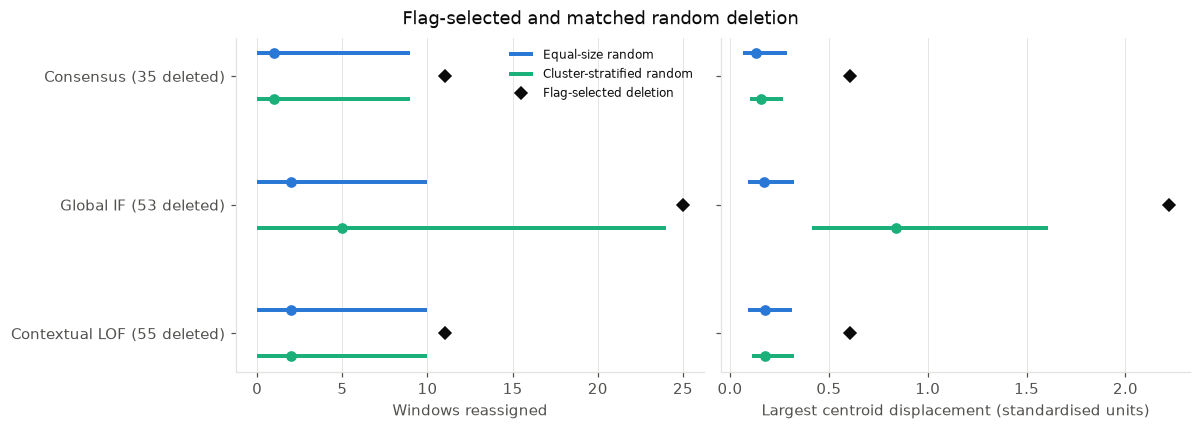

In [108]:
from time import perf_counter as s6_perf_counter
from threadpoolctl import threadpool_limits as s6_threadpool_limits


def s6_deletion_experiments(windows, matrix, labels, cluster_ids, params, reference_centres,
                            window_key, results_dir, figures_dir):
    masks = {
        "Consensus": windows["anomaly"].to_numpy(bool),
        "Global IF": windows["global_if_flag"].to_numpy(bool),
        "Contextual LOF": windows["contextual_lof_flag"].to_numpy(bool),
    }
    state_rows = [np.flatnonzero(labels == cluster) for cluster in cluster_ids]

    def refit(removed):
        fitted = KMeans(**params).fit(matrix[~removed])
        if np.unique(fitted.labels_).size != len(cluster_ids):
            raise ValueError("A deletion refit did not retain the requested number of populated clusters.")
        proposed = fitted.predict(matrix)
        mapping = s6_optimal_cluster_alignment(labels, proposed, len(cluster_ids))
        aligned = mapping[proposed]
        shifts = np.linalg.norm(fitted.cluster_centers_[np.argsort(mapping)] - reference_centres, axis=1)
        changed = aligned != labels
        metrics = {
            "removed": int(removed.sum()),
            "changed_all": int(changed.sum()),
            "changed_retained": int(changed[~removed].sum()),
            "changed_removed": int(changed[removed].sum()),
            "ARI_all": adjusted_rand_score(labels, aligned),
            "ARI_retained": adjusted_rand_score(labels[~removed], aligned[~removed]),
            "ARI_removed": adjusted_rand_score(labels[removed], aligned[removed]) if removed.any() else np.nan,
            "largest_centroid_shift": shifts.max(),
            "mean_centroid_shift": shifts.mean(),
            **{f"C{c}_centroid_shift": shift for c, shift in zip(cluster_ids, shifts)},
        }
        return metrics, aligned

    control_types = ("Equal-size random", "Cluster-stratified random")
    control_specs = [(policy, control) for policy in masks for control in control_types]
    control_seeds = np.random.SeedSequence(4368003).spawn(len(control_specs))
    n_draws = 500
    targeted, assignments, random_rows = [], [], []
    started = s6_perf_counter()
    with s6_threadpool_limits(limits=1):
        for policy, mask in masks.items():
            metrics, aligned = refit(mask)
            targeted.append({
                "policy": policy, **metrics,
                **{f"removed_C{c}": int(mask[rows].sum()) for c, rows in zip(cluster_ids, state_rows)},
            })
            assignments.append(windows[window_key + ["cluster"]].assign(
                policy=policy, removed=mask, refit_cluster=aligned, changed=aligned != labels,
            ))
        for (policy, control), seed in zip(control_specs, control_seeds):
            mask = masks[policy]
            state_counts = [int(mask[rows].sum()) for rows in state_rows]
            size = int(mask.sum())
            rng = np.random.default_rng(seed)
            for draw in range(1, n_draws + 1):
                if control == "Equal-size random":
                    chosen = rng.choice(len(windows), size, replace=False)
                else:
                    chosen = np.concatenate([rng.choice(rows, count, replace=False)
                                             for rows, count in zip(state_rows, state_counts)])
                removed = np.zeros(len(windows), dtype=bool)
                removed[chosen] = True
                metrics, _ = refit(removed)
                random_rows.append({"policy": policy, "control": control, "draw": draw, **metrics})
            print(f"{policy}, {control}, {n_draws} refits complete", flush=True)

    observed = pd.DataFrame(targeted).set_index("policy")
    random = pd.DataFrame(random_rows)
    if len(random) != len(control_specs) * n_draws or not random.groupby(
            ["policy", "control"]).size().eq(n_draws).all():
        raise ValueError("One or more deletion controls did not complete every draw.")
    print(f"Completed {len(random):,} random refits in {s6_perf_counter() - started:.1f} s.")

    summary_rows = []
    for (policy, control), draws in random.groupby(["policy", "control"], sort=False):
        for metric in draws.columns.drop(["policy", "control", "draw", "removed"]):
            lo, median, hi = draws[metric].quantile([0.025, 0.5, 0.975])
            value = observed.loc[policy, metric]
            extreme = draws[metric].le(value) if metric.startswith("ARI_") else draws[metric].ge(value)
            summary_rows.append({
                "policy": policy, "control": control, "metric": metric,
                "p2.5": lo, "median": median, "p97.5": hi, "targeted": value,
                "tail_fraction": (1 + extreme.sum()) / (len(draws) + 1),
            })
    summary = pd.DataFrame(summary_rows)
    display(observed.round(3))
    display(summary.loc[summary.metric.isin(["changed_all", "ARI_all", "largest_centroid_shift"])]
            .round(3).set_index(["policy", "control", "metric"]))
    observed.to_csv(results_dir / "targeted_removal.csv")
    pd.concat(assignments, ignore_index=True).to_csv(results_dir / "targeted_removal_assignments.csv", index=False)
    random.to_csv(results_dir / "random_deletion_draws.csv", index=False)
    summary.to_csv(results_dir / "random_deletion_summary.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.8), sharey=True, layout="constrained")
    intervals = summary.set_index(["policy", "control", "metric"])
    axes_data = [("changed_all", "Windows reassigned"),
                 ("largest_centroid_shift", "Largest centroid displacement (standardised units)")]
    for ax, (metric, xlabel) in zip(axes, axes_data):
        for y, policy in enumerate(masks):
            for offset, control, color in zip((-0.18, 0.18), control_types, (C_BLUE, C_AQUA)):
                interval = intervals.loc[(policy, control, metric)]
                ax.hlines(y + offset, interval["p2.5"], interval["p97.5"], color=color,
                          linewidth=2.6, label=control if y == 0 else None)
                ax.plot(interval["median"], y + offset, "o", color=color)
            ax.plot(observed.loc[policy, metric], y, "D", color=INK,
                    label="Flag-selected deletion" if y == 0 else None)
        ax.set_xlabel(xlabel)
        ax.set_yticks(range(len(masks)), [f"{policy} ({int(observed.loc[policy, 'removed'])} deleted)"
                                        for policy in masks])
        ax.grid(axis="y", visible=False)
    axes[0].invert_yaxis()
    axes[0].legend(loc="best", fontsize=8)
    fig.suptitle("Flag-selected and matched random deletion")
    fig.savefig(figures_dir / "deletion_controls.png")
    plt.show()
    return s6_Namespace(removal_results=observed, control_draws=random, control_summary=summary)


s6_controls = s6_deletion_experiments(
    s6_synthesis, s6_matrix, s6_reference_labels, s6_cluster_ids, s6_kmeans_params,
    km_final.cluster_centers_, s6_window_key, s6_results, s6_figures,
)

#### Event proximity and anomaly episodes

We retain Section 5's annotated whole-room transitions, causal leave-date-out
Fusion AND estimated event times, and the existing one-to-one event evaluation.
Proximity is a separate comparison. A consensus flag is near an event if one
of the readings in its window falls within five minutes of the event in the
same acquisition run. A gap longer than 65 seconds starts a new run within
the original recording segment. Every event must match an original timestamp
in its segment. Events in dropped bins stay in the denominator. Consecutive
flagged bins form one episode within a run. If a flagged bin spans a gap,
its observed portions can belong to different run-specific episodes.

For each event source, 5,000 matched recording-time draws preserve how many
events occurred in each segment, acquisition run, calendar date and
eligible-bin stratum. We sample observed times without replacement within
a stratum and simulate counts from the corresponding hypergeometric
distribution. The reference ranges describe coincidence under those
constraints. Activity and time of day can still vary within a stratum.

In [109]:
def s6_event_proximity(windows, readings, origins, estimates, reference, attached_events,
                       event_benchmarks, audit_2min, window_key, results_dir):
    margin = pd.Timedelta(minutes=5)
    bin_key = ["segment", "win"]
    run_key = ["segment", "acquisition_run"]
    points = readings[["ts", "segment", "date", LABEL, "S5_CO2", *PIR]].sort_values("ts").copy()
    points["previous_gap_s"] = points.groupby("segment").ts.diff().dt.total_seconds()
    points["acquisition_run"] = points.ts.diff().dt.total_seconds().gt(s6_quality_gap_s).cumsum()
    points["win"] = s6_window_numbers(points.ts, points.segment.map(origins))
    points = points.merge(windows[window_key + ["cluster", "anomaly"]], on=bin_key,
                          how="left", validate="many_to_one")
    points["eligible"] = points["start"].notna()
    points["anomaly"] = points["anomaly"].eq(True)
    observed_starts = (points.loc[points.eligible].groupby(bin_key, as_index=False).ts.min()
                      .rename(columns={"ts": "start"}))
    pd.testing.assert_frame_equal(observed_starts, windows[window_key].sort_values(bin_key).reset_index(drop=True))

    flagged = points.loc[points.anomaly, run_key + ["win", "ts"]]
    new_episode = (flagged.acquisition_run.ne(flagged.acquisition_run.shift())
                   | flagged.win.diff().gt(1))
    points["episode"] = new_episode.cumsum().reindex(points.index).astype("Int64")
    episodes = points.loc[points.anomaly].groupby("episode").agg(
        segment=("segment", "first"), acquisition_run=("acquisition_run", "first"),
        first_reading=("ts", "min"), last_reading=("ts", "max"), windows=("win", "nunique"),
    )
    episodes["minutes_spanned"] = (episodes.last_reading - episodes.first_reading).dt.total_seconds() / 60

    estimated = (estimates[["segment", "detected_time", "event_type"]]
                 .rename(columns={"detected_time": "event_time"}).assign(source="Fusion AND estimates"))
    recorded = (reference[["segment", "ts", "type"]]
                .rename(columns={"ts": "event_time", "type": "event_type"}).assign(source="Recorded transitions"))
    tagged = pd.concat([estimated, recorded], ignore_index=True)
    tagged["event_id"] = np.arange(len(tagged))
    tagged = tagged.merge(
        points[run_key + ["ts", "date", "win", "eligible", "anomaly", "previous_gap_s"]]
        .rename(columns={"ts": "event_time", "anomaly": "in_consensus_window"}),
        on=["segment", "event_time"], how="left", validate="many_to_one", indicator=True,
    )
    if not tagged["_merge"].eq("both").all():
        raise ValueError("Each Section 5 event must identify an original reading in its recorded segment.")
    tagged = tagged.drop(columns="_merge")
    estimate_key = ["segment", "event_time", "event_type"]
    section5_eligibility = (attached_events.rename(columns={"detected_time": "event_time"})
                           .set_index(estimate_key)["has_group_cluster"].sort_index())
    pd.testing.assert_series_equal(
        tagged.loc[tagged.source.eq("Fusion AND estimates")].set_index(estimate_key).eligible.sort_index(),
        section5_eligibility, check_names=False,
    )

    # Copy the Section 5 matching outcomes for interpretation of individual events.
    predicted_status = (audit_2min.dropna(subset=["predicted_time"])
                       .rename(columns={"predicted_time": "event_time", "type": "event_type"}))
    true_status = (audit_2min.dropna(subset=["true_time"])
                  .rename(columns={"true_time": "event_time", "type": "event_type"}))
    status = pd.concat([
        predicted_status[["event_time", "event_type", "status"]].assign(source="Fusion AND estimates"),
        true_status[["event_time", "event_type", "status"]].assign(source="Recorded transitions"),
    ]).rename(columns={"status": "status_2min"})
    tagged = tagged.merge(status, on=["source", "event_time", "event_type"],
                          how="left", validate="one_to_one")
    if tagged.status_2min.isna().any():
        raise ValueError("The Section 5 match audit is missing an event outcome.")

    nearby = tagged[run_key + ["event_id", "event_time", "source", "event_type", "status_2min"]].merge(
        points.loc[points.eligible, run_key + ["win", "start", "ts", "anomaly", "episode"]],
        on=run_key, validate="many_to_many")
    nearby["distance_s"] = (nearby.ts - nearby.event_time).abs().dt.total_seconds()
    nearby = nearby.loc[nearby.distance_s.le(margin.total_seconds())].sort_values(["distance_s", "ts"])
    links = nearby.drop_duplicates(["event_id", *window_key])
    anomaly_links = links.loc[links.anomaly]
    tagged["near_consensus"] = tagged.event_id.isin(anomaly_links.event_id)
    overlap = tagged.groupby("source", sort=False).agg(
        events=("event_id", "size"),
        events_with_eligible_bin=("eligible", "sum"),
        events_inside_consensus_bin=("in_consensus_window", "sum"),
        events_near_consensus=("near_consensus", "sum"),
    )
    hit_windows = anomaly_links.drop_duplicates(["source", *window_key]).groupby("source").size()
    hit_episodes = anomaly_links.groupby("source").episode.nunique()
    overlap["unique_consensus_windows_near_events"] = hit_windows.reindex(overlap.index, fill_value=0)
    overlap["unique_consensus_episodes_near_events"] = hit_episodes.reindex(overlap.index, fill_value=0)
    overlap["all_consensus_windows"] = int(windows.anomaly.sum())
    overlap["all_consensus_episodes"] = len(episodes)
    by_direction = tagged.groupby(["source", "event_type"], sort=False).agg(
        events=("event_id", "size"), events_near_consensus=("near_consensus", "sum"),
    )

    n_draws = 5_000
    strata = run_key + ["date", "eligible"]
    nearest = pd.merge_asof(
        points[["ts", *strata]], points.loc[points.anomaly, run_key + ["ts"]].rename(columns={"ts": "flagged_ts"}),
        left_on="ts", right_on="flagged_ts", by=run_key, direction="nearest", tolerance=margin,
    ).assign(hit=lambda frame: frame.flagged_ts.notna())
    hit_lookup = nearest.set_index(["segment", "ts"]).hit
    tagged_index = pd.MultiIndex.from_frame(tagged[["segment", "event_time"]])
    np.testing.assert_array_equal(tagged["near_consensus"], hit_lookup.reindex(tagged_index))
    available = nearest.groupby(strata).hit.agg(["size", "sum"])
    rng = np.random.default_rng(4368004)
    time_rows = []
    for source, source_events in tagged.groupby("source", sort=False):
        sampled_hits = np.zeros(n_draws, dtype=int)
        for stratum, n_events in source_events.groupby(strata).size().items():
            n_available, n_hits = available.loc[stratum]
            if n_events > n_available:
                raise ValueError(f"Too few observed times for control sampling in stratum {stratum}.")
            sampled_hits += rng.multivariate_hypergeometric(
                [n_available - n_hits, n_hits], n_events, size=n_draws)[:, 1]
        observed_hits = int(overlap.loc[source, "events_near_consensus"])
        low, median, high = np.quantile(sampled_hits, [0.025, 0.5, 0.975])
        time_rows.append({
            "source": source, "observed_hits": observed_hits, "mean_random_hits": sampled_hits.mean(),
            "p2.5": low, "median": median, "p97.5": high,
            "upper_tail_fraction": (1 + np.count_nonzero(sampled_hits >= observed_hits)) / (n_draws + 1),
        })
    time = pd.DataFrame(time_rows).set_index("source")
    display(event_benchmarks.loc[event_benchmarks.method.isin(["Fusion AND", "PIR", "Raw PIR (no persistence)"]),
                                ["method", "tolerance_min", "dates_scored", "n_reference_room_events",
                                 "TP", "FP", "FN", "Precision", "Recall", "F1", "ConfirmLag_min"]].round(3))
    display(overlap, by_direction, time.round(3))
    display(anomaly_links[["source", "event_type", "event_time", *window_key, "ts", "distance_s", "episode"]])
    overlap.to_csv(results_dir / "event_anomaly_overlap.csv")
    by_direction.to_csv(results_dir / "event_anomaly_by_direction.csv")
    tagged.to_csv(results_dir / "event_window_audit.csv", index=False)
    anomaly_links.to_csv(results_dir / "event_anomaly_links.csv", index=False)
    episodes.to_csv(results_dir / "consensus_episodes.csv")
    time.to_csv(results_dir / "event_overlap_time_controls.csv")
    return s6_Namespace(event_overlap=overlap, time_controls=time, event_points=tagged,
                        recording_points=points, event_window_overlap=links, anomaly_episodes=episodes)


s6_events = s6_event_proximity(s6_synthesis, df, segment_starts, events6, T, attached,
                              HANDOFF6, AUDIT, s6_window_key, s6_results)

,method,tolerance_min,dates_scored,n_reference_room_events,TP,FP,FN,Precision,Recall,F1,ConfirmLag_min
0,Raw PIR (no persistence),2,7,8,6,13,2,0.316,0.750,0.444,7.750
1,Raw PIR (no persistence),5,7,8,7,12,1,0.368,0.875,0.519,11.933
2,PIR,2,7,8,7,5,1,0.583,0.875,0.700,15.500
3,PIR,5,7,8,8,4,0,0.667,1.000,0.800,13.717
8,Fusion AND,2,7,8,7,3,1,0.700,0.875,0.778,15.000
9,Fusion AND,5,7,8,8,2,0,0.800,1.000,0.889,13.467


,events,events_with_eligible_bin,events_inside_consensus_bin,events_near_consensus,unique_consensus_windows_near_events,unique_consensus_episodes_near_events,all_consensus_windows,all_consensus_episodes
source,,,,,,,,
Fusion AND estimates,10,9,0,0,0,0,35,28
Recorded transitions,8,7,0,0,0,0,35,28


events  events_near_consensus
source               event_type                               
Fusion AND estimates departure        6                      0
                     arrival          4                      0
Recorded transitions departure        5                      0
                     arrival          3                      0

,observed_hits,mean_random_hits,p2.5,median,p97.5,upper_tail_fraction
source,,,,,,
Fusion AND estimates,0,0.846,0.0,1.0,3.0,1.0
Recorded transitions,0,0.681,0.0,1.0,2.0,1.0


,source,event_type,event_time,segment,win,start,ts,distance_s,episode


#### Exceptional windows in C0, C3 and C4

We compare globally flagged C0 windows with the rest of that high-activity
state. The most extreme global scores provide individual timestamps for
the sensor review. We also inspect every occupied C3 window and every empty
C4 window, using raw occupancy counts, motion, sound, light and CO₂. The
measured CO₂ change is the last minus first observed reading. The rolling
CO₂ slope describes a separate sensor feature. The event column uses the
same-run five-minute proximity rule and displays Section 5's existing
two-minute event-match status. Occupancy labels and motion provide different
evidence. The raw data do not identify people or establish a sensor fault.

In [110]:
def s6_review_cases(windows, timeline, window_key, results_dir):
    high_activity = windows.loc[windows.cluster.eq(0)]
    comparison = high_activity.groupby("global_if_flag").agg(
        windows=("win", "size"), occupied_windows=("occupied", "sum"), consensus_windows=("anomaly", "sum"),
        light_lux=("light_mean", "median"), sound_mean_V=("sound_mean", "median"),
        sound_max_V=("sound_max", "median"), PIR_fraction=("pir_frac", "median"),
        CO2_excess_ppm=("CO2_excess_mean", "median"), source_CO2_slope=("CO2_slope_mean", "median"),
    )
    c0_review = (high_activity.loc[high_activity.global_if_flag]
                 .sort_values(["score_iso_global", "start"], ascending=[False, True])
                 [window_key + ["occupied", "occ_mode", "light_mean", "sound_mean", "pir_frac",
                                "CO2_excess_mean", "CO2_slope_mean", "score_iso_global", "anomaly"]])
    display(comparison.round(3), c0_review.head(5).round(3))
    comparison.to_csv(results_dir / "high_activity_global_IF_review.csv")
    c0_review.to_csv(results_dir / "high_activity_global_IF_examples.csv", index=False)

    points = timeline.recording_points
    bin_key = ["segment", "win"]
    raw_context = (points.loc[points.eligible].assign(PIR_on=lambda frame: frame[PIR].max(axis=1).gt(0))
                   .groupby(bin_key).agg(
                       last_reading=("ts", "max"), minimum_count=(LABEL, "min"), maximum_count=(LABEL, "max"),
                       PIR_readings=("PIR_on", "sum"),
                       co2_change_ppm=("S5_CO2", lambda values: values.iloc[-1] - values.iloc[0]),
                       recording_runs=("acquisition_run", "nunique"),
                   ))
    mask = (windows.cluster.eq(3) & windows.occupied) | (windows.cluster.eq(4) & ~windows.occupied)
    case_columns = window_key + ["cluster", "n_readings", "occ_mode", "light_mean", "sound_max", "pir_frac",
                                 "CO2_excess_mean", "CO2_slope_mean", "anomaly", "anomaly_votes",
                                 "anomaly_category", "anomaly_drivers"]
    cases = windows.loc[mask, case_columns].join(raw_context, on=bin_key, validate="one_to_one")
    nearby = (timeline.event_window_overlap.merge(cases[window_key], on=window_key, validate="many_to_one")
              .assign(event=lambda frame: frame.source + " · " + frame.event_type + " · "
                      + frame.event_time.dt.strftime("%d %b %H:%M:%S") + " · " + frame.status_2min))
    notes = nearby.groupby(window_key).event.agg(" | ".join).rename("nearby_events")
    cases = cases.join(notes, on=window_key, validate="one_to_one")
    display(cases.round(3))
    cases.to_csv(results_dir / "occupied_C3_and_empty_C4.csv", index=False)
    return s6_Namespace(global_if_c0=comparison, global_if_c0_cases=c0_review, exception_windows=cases)


s6_cases = s6_review_cases(s6_synthesis, s6_events, s6_window_key, s6_results)

/var/folders/0h/47l1qjhn3ljfnsz7_cjvrv4m0000gn/T/ipykernel_28629/3433901156.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparison.round(3), c0_review.head(5).round(3))


,windows,occupied_windows,consensus_windows,light_lux,sound_mean_V,sound_max_V,PIR_fraction,CO2_excess_ppm,source_CO2_slope
global_if_flag,,,,,,,,,
False,40,40,0,101.012,0.555,3.180,0.500,441.50,1.798
True,42,42,5,143.413,0.763,3.465,0.658,540.75,1.501


,segment,win,start,occupied,occ_mode,light_mean,sound_mean,pir_frac,CO2_excess_mean,CO2_slope_mean,score_iso_global,anomaly
21,1,0,2017-12-22 13:08:03,True,3,177.250,1.340,0.90,463.5,6.309,0.697,True
20,0,21,2017-12-22 12:34:52,True,3,172.675,1.114,0.95,285.5,1.401,0.692,True
19,0,20,2017-12-22 12:29:46,True,3,169.800,0.891,0.95,263.0,0.461,0.687,False
95,1,74,2017-12-22 19:18:13,True,3,138.250,0.933,0.75,864.0,0.255,0.667,False
22,1,1,2017-12-22 13:13:09,True,3,177.125,0.765,0.85,490.0,8.167,0.662,False


/var/folders/0h/47l1qjhn3ljfnsz7_cjvrv4m0000gn/T/ipykernel_28629/3433901156.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cases.round(3))


,segment,win,start,cluster,n_readings,occ_mode,light_mean,sound_max,pir_frac,CO2_excess_mean,...,anomaly_votes,anomaly_category,anomaly_drivers,last_reading,minimum_count,maximum_count,PIR_readings,co2_change_ppm,recording_runs,nearby_events
2,0,2,2017-12-22 10:59:54,3,10,1,65.175,1.57,0.250,11.000,...,3,Multi-sensor behaviour,"S1_Sound_max, S6_PIR_frac, S1_Sound_mean, S2_S...",2017-12-22 11:04:29,1,1,5,15,1,NaN
3,0,3,2017-12-22 11:05:00,3,10,1,64.925,0.93,0.050,21.000,...,2,Multi-sensor behaviour,"S1_Sound_max, CO2_slope_mean, S1_Sound_mean, S...",2017-12-22 11:09:36,1,1,1,20,1,NaN
4,0,4,2017-12-22 11:10:06,3,9,1,65.972,1.44,0.111,35.000,...,3,Multi-sensor behaviour,"S1_Sound_max, S1_Sound_mean, CO2_slope_mean, S...",2017-12-22 11:14:12,1,1,2,10,1,NaN
5,0,5,2017-12-22 11:14:42,3,10,1,65.800,0.94,0.100,39.000,...,2,Multi-sensor behaviour,"S1_Sound_max, S1_Sound_mean, S6_PIR_frac, CO2_...",2017-12-22 11:19:18,1,1,2,15,1,NaN
6,0,6,2017-12-22 11:19:49,3,10,1,66.300,1.10,0.100,50.000,...,3,Multi-sensor behaviour,"S1_Sound_mean, S1_Sound_max, S6_PIR_frac, CO2_...",2017-12-22 11:24:24,1,1,2,0,1,NaN
54,1,33,2017-12-22 15:53:29,3,9,1,59.861,0.15,0.000,238.889,...,3,Multi-sensor behaviour,"CO2_slope_mean, CO2_excess_mean, S1_Temp_mean,...",2017-12-22 15:57:34,1,1,0,5,1,NaN
326,1,307,2017-12-23 14:43:22,4,10,0,34.975,1.61,0.250,177.000,...,0,NaN,NaN,2017-12-23 14:47:58,0,0,4,10,1,Fusion AND estimates · arrival · 23 Dec 14:43:...
327,1,308,2017-12-23 14:48:29,4,9,0,33.417,0.69,0.000,186.667,...,0,NaN,NaN,2017-12-23 14:52:34,0,0,0,-5,1,Fusion AND estimates · departure · 23 Dec 14:4...
329,1,310,2017-12-23 14:58:11,4,10,0,31.200,0.66,0.050,160.500,...,0,NaN,NaN,2017-12-23 15:02:46,0,0,1,-15,1,NaN


### Overall findings

The room states combine light, sound, motion, temperature and CO₂. The
alternative representations and resolution comparison describe how
sensitive the groupings are to modelling decisions. Section 4's
review candidates have more local context than the global flags.
Neither recorded occupancy nor event estimates measure sensor health.

The deletion experiments quantify changes in the fitted representation.
Event alignment describes this short recording and the specific timing
rule above. Nearby windows and events share sensor evidence and can be
temporally dependent.

In [111]:
def s6_summarise():
    counts = s6_integration.anomaly_by_state
    removal = s6_controls.removal_results.loc["Consensus"]
    resolution = s6_resolution.loc["Also eligible at 2 minutes"]
    detection = HANDOFF6.set_index(["method", "tolerance_min"])
    fusion = detection.loc[("Fusion AND", 2)]
    pir = detection.loc[("PIR", 2)]
    recorded = s6_events.event_overlap.loc["Recorded transitions"]
    estimated = s6_events.event_overlap.loc["Fusion AND estimates"]
    table = pd.DataFrame([
        ("Five-minute baseline", f"{len(s6_synthesis):,} windows and {len(s6_cluster_ids)} states"),
        ("Aggregation sensitivity",
         f"ARI {resolution.cluster_ARI:.3f} and provisional flag overlaps "
         f"{resolution.IF_Jaccard:.3f} (IF), {resolution.LOF_Jaccard:.3f} (LOF), "
         f"{resolution.population_LOF_Jaccard:.3f} (population-adjusted LOF)"),
        ("C2 context",
         f"{int(s6_c2_summary.negative_source_slope)}/{int(s6_c2_summary.windows)} negative CO₂ slopes. "
         f"{s6_c2_timing.loc['Recorded transitions', 'C2_within_15min']} C2 starts within 15 minutes "
         "of a recorded departure in the same run"),
        ("Alternative representations",
         f"GMM ARI {s6_method_comparison.iloc[0, 0]:.3f}, "
         f"{s6_method_comparison.iloc[0, 1]:.1f}% aligned agreement. "
         f"SOM populated nodes {s6_som['node_profiles'].windows.gt(0).sum()}/{len(s6_som['grid'])}"),
        ("Global IF in C0", f"{int(counts.loc[0, 'Global IF'])}/{counts.loc[0, 'windows']} C0 windows"),
        ("Within-state consensus",
         f"{int(counts.Consensus.sum())}/{len(s6_synthesis):,} windows, "
         + ", ".join(f"C{i} {int(n)}" for i, n in counts.Consensus.items())),
        ("Consensus deletion",
         f"{int(removal.changed_all)} assignments change, ARI {removal.ARI_all:.3f}, "
         f"maximum centroid shift {removal.largest_centroid_shift:.3f}"),
        ("Original event benchmark at ±2 minutes", f"Fusion AND F1 {fusion.F1:.3f}, PIR F1 {pir.F1:.3f}"),
        ("Consensus flags near events",
         f"{recorded.events_near_consensus}/{recorded.events} recorded transitions and "
         f"{estimated.events_near_consensus}/{estimated.events} estimated events"),
    ], columns=["Finding", "Computed result"])
    display(table)
    return table


s6_poster_evidence = s6_summarise()
s6_poster_evidence.to_csv(s6_results / "poster_evidence.csv", index=False)

,Finding,Computed result
0,Five-minute baseline,"1,044 windows and 5 states"
1,Aggregation sensitivity,ARI 0.854 and provisional flag overlaps 0.443 ...
2,C2 context,82/88 negative CO₂ slopes. 15 C2 starts within...
3,Alternative representations,"GMM ARI 0.762, 88.7% aligned agreement. SOM po..."
4,Global IF in C0,42/82 C0 windows
5,Within-state consensus,"35/1,044 windows, C0 5, C1 14, C2 1, C3 9, C4 6"
6,Consensus deletion,"11 assignments change, ARI 0.978, maximum cent..."
7,Original event benchmark at ±2 minutes,"Fusion AND F1 0.778, PIR F1 0.700"
8,Consensus flags near events,0/8 recorded transitions and 0/10 estimated ev...


## References
- Singh, A. P., Jain, V., Chaudhari, S., Kraemer, F. A., Werner, S. and Garg, V. (2018) 'Machine learning-based occupancy estimation using multivariate sensor nodes', *2018 IEEE Globecom Workshops (GC Wkshps)*, pp. 1–6.
- Singh, A. P. and Chaudhari, S. (2018) *Room Occupancy Estimation* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5P605

### AI Integrity Statement

Generative AI tools, including ChatGPT, were used during the development of this project to support brainstorming, clarify technical concepts, assist with Python debugging, suggest code improvements, and improve the clarity of documentation. AI assistance was used as a supplementary learning and development tool rather than a replacement for independent research or critical analysis.

All data preparation, methodological decisions, model implementation, experimental evaluation, interpretation of results, and conclusions were reviewed and validated by the group. The group takes full responsibility for the accuracy, reproducibility, and academic integrity of the submitted work and ensures that all group members understand and can explain the methods and results presented.